# Appliance Energy Prediction — Deep Learning Forecasting of Household Appliance Energy Use

**Target:** `Appliances` — appliance energy consumption (Wh) per 10-minute interval
**Task:** one-step-ahead forecast — predict the consumption of the *next* 10-minute interval using only information available **before** that interval starts.

## Notebook roadmap

| Section | Content |
|---|---|
| **0** | Setup and configuration |
| **1. Data Understanding and Preprocessing** | EDA, missing values, outliers, chronological split, scaling strategy |
| **2. Feature Engineering** | time features, rolling windows, lags (autocorrelation-based), interactions, domain features, feature selection |
| **3. Model Development** | baselines, architecture design (LSTM / GRU / CNN-LSTM / MLP), activations and optimizers, loss functions, regularization |
| **4. Model Training and Evaluation** | training and validation curves, MAE / RMSE / MAPE / R², comparison with baselines, visualizations |
| **5. Model Optimization** | hyper-parameter tuning (random + grid search, walk-forward cross-validation), dropout, early stopping, before/after evaluation on the test set |

## Review of the earlier version — mistakes found and corrected

| # | Problem found | Correction in this notebook |
|---|---|---|
| 1 | **Sequence windows never contained the latest consumption.** Each window ended one row *before* the target row, but the lag/rolling features that carry the previous consumption sit *in* the target row. The LSTM/GRU therefore could not see the value of the previous interval, while the persistence baseline could. | Features of row *i* are built only from information available before interval *i*; every window now **ends at row *i*** (§3.1). |
| 2 | **Unequal information sets.** Linear Regression / Random Forest used the sensor readings of the *same* interval as the target, whereas the LSTM/GRU did not. The comparison was unfair, and for a forecasting task the same-interval sensor values would not be available. | Sensor/weather columns are shifted by one interval, and a leakage test verifies that row *i* does not depend on any raw value of interval *i* (§2.6). |
| 3 | **No validation set; models were judged on the test set.** Early stopping used `validation_split` of the already-scaled training data, and the LSTM/GRU were compared on test results. | Chronological **train / validation / test** split. All design decisions use the validation set; the test set is used once, for the final report (§2.6, §4). |
| 4 | Scalers were fitted on the whole training period, including the validation portion. | Scalers are fitted on the training sub-set only (§3.1). |
| 5 | **Feature selection was computed but never applied** (random-forest importances were only plotted). All columns, including `rv1` and `rv2` (random noise variables), were fed to every model. | Three selection methods + voting + validation check; the selected feature set is what the models use (§2.7). |
| 6 | GRU was first evaluated on **standardized** predictions against targets in Wh and patched in later cells. | One `regression_metrics` / `predict_wh` path that always inverse-transforms (§3.1). |
| 7 | About 30 debug/audit cells (old cells 43–72) rebuilt the test sequences repeatedly with contradictory assertions (some asserted the last window equals `X_test_scaled[-12:]`, another asserted the opposite). | Replaced by one windowing function and one automatic alignment test (§3.1). |
| 8 | Duplicate/inconsistent variables (`y_test`, `y_test_fs`, `y_test_raw`, `y_test_actual`, `y_test_wh`) and two different 80/20 splits (`model_ready`, then `train_all/test_all`). | One timeline, one set of index ranges, one set of arrays. |
| 9 | EDA columns (`hour`, `day_of_week` as text) were written into the main dataframe. | EDA uses a separate copy (§1.4). |
| 10 | Model-development subtasks missing: only LSTM/GRU with hand-picked settings; no CNN-LSTM; no comparison of activations, optimizers, losses or regularization; no loss curves; outlier decision not tested; lags not derived from autocorrelation; no domain features. | Sections 2.3, 2.5, 3.2–3.6, 4.1. |
| 11 | Data path only worked on Google Colab. | Falls back to a local CSV (set `ENERGY_CSV`). |
| 12 | **Raw sensor/weather columns drift with the season** (found while re-running the baselines: mean outdoor temperature is about 6 °C in the training weeks and about 14 °C in the test weeks). Tree models that use the absolute sensor values extrapolate badly, and a validation block from the same season cannot reveal it. | Walk-forward (expanding-window) feature-group test inside the training period (§2.7b). |

## 0. Setup and configuration

In [1]:
import os, random, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

TARGET = "Appliances"          # target variable (Wh per 10 minutes)
STEP = pd.Timedelta(minutes=10)

pd.set_option("display.max_columns", 50)
sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 100

## 1. Data Understanding and Preprocessing
**Objective:** analyse and prepare the dataset for modelling.

### 1.1 Load the dataset

In [2]:
# Load the data. On Google Colab the file is read from Google Drive;
# elsewhere set the ENERGY_CSV environment variable (or place the file next to the notebook).
try:
    from google.colab import drive
    drive.mount("/content/drive")
    csv_path = "/content/drive/MyDrive/Energy Prediction System/Dataset/energy_data_set.csv"
except ImportError:
    csv_path = os.environ.get("ENERGY_CSV", "energy_data_set.csv")
    print("Not running on Colab - reading the local CSV file.")

df = pd.read_csv(csv_path)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)
display(df.head())

Not running on Colab - reading the local CSV file.
Dataset loaded successfully!
Dataset shape: (19735, 29)


,date,Appliances,lights,T1,RH_1,T2,RH_2,T3,RH_3,T4,RH_4,T5,RH_5,T6,RH_6,T7,RH_7,T8,RH_8,T9,RH_9,T_out,Press_mm_hg,RH_out,Windspeed,Visibility,Tdewpoint,rv1,rv2
0,2016-01-11 17:00:00,60,30,19.89,47.596667,19.2,44.790000,19.79,44.730000,19.000000,45.566667,17.166667,55.20,7.026667,84.256667,17.200000,41.626667,18.2,48.900000,17.033333,45.53,6.600000,733.5,92.0,7.000000,63.000000,5.3,13.275433,13.275433
1,2016-01-11 17:10:00,60,30,19.89,46.693333,19.2,44.722500,19.79,44.790000,19.000000,45.992500,17.166667,55.20,6.833333,84.063333,17.200000,41.560000,18.2,48.863333,17.066667,45.56,6.483333,733.6,92.0,6.666667,59.166667,5.2,18.606195,18.606195
2,2016-01-11 17:20:00,50,30,19.89,46.300000,19.2,44.626667,19.79,44.933333,18.926667,45.890000,17.166667,55.09,6.560000,83.156667,17.200000,41.433333,18.2,48.730000,17.000000,45.50,6.366667,733.7,92.0,6.333333,55.333333,5.1,28.642668,28.642668
3,2016-01-11 17:30:00,50,40,19.89,46.066667,19.2,44.590000,19.79,45.000000,18.890000,45.723333,17.166667,55.09,6.433333,83.423333,17.133333,41.290000,18.1,48.590000,17.000000,45.40,6.250000,733.8,92.0,6.000000,51.500000,5.0,45.410389,45.410389
4,2016-01-11 17:40:00,60,40,19.89,46.333333,19.2,44.530000,19.79,45.000000,18.890000,45.530000,17.200000,55.09,6.366667,84.893333,17.200000,41.230000,18.1,48.590000,17.000000,45.40,6.133333,733.9,92.0,5.666667,47.666667,4.9,10.084097,10.084097


### 1.2 Dataset overview

In [3]:
display(df.head())
display(df.tail())

print("Number of observations:", df.shape[0])
print("Number of columns:", df.shape[1])

print("\nColumn names:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()

,date,Appliances,lights,T1,RH_1,T2,RH_2,T3,RH_3,T4,RH_4,T5,RH_5,T6,RH_6,T7,RH_7,T8,RH_8,T9,RH_9,T_out,Press_mm_hg,RH_out,Windspeed,Visibility,Tdewpoint,rv1,rv2
0,2016-01-11 17:00:00,60,30,19.89,47.596667,19.2,44.790000,19.79,44.730000,19.000000,45.566667,17.166667,55.20,7.026667,84.256667,17.200000,41.626667,18.2,48.900000,17.033333,45.53,6.600000,733.5,92.0,7.000000,63.000000,5.3,13.275433,13.275433
1,2016-01-11 17:10:00,60,30,19.89,46.693333,19.2,44.722500,19.79,44.790000,19.000000,45.992500,17.166667,55.20,6.833333,84.063333,17.200000,41.560000,18.2,48.863333,17.066667,45.56,6.483333,733.6,92.0,6.666667,59.166667,5.2,18.606195,18.606195
2,2016-01-11 17:20:00,50,30,19.89,46.300000,19.2,44.626667,19.79,44.933333,18.926667,45.890000,17.166667,55.09,6.560000,83.156667,17.200000,41.433333,18.2,48.730000,17.000000,45.50,6.366667,733.7,92.0,6.333333,55.333333,5.1,28.642668,28.642668
3,2016-01-11 17:30:00,50,40,19.89,46.066667,19.2,44.590000,19.79,45.000000,18.890000,45.723333,17.166667,55.09,6.433333,83.423333,17.133333,41.290000,18.1,48.590000,17.000000,45.40,6.250000,733.8,92.0,6.000000,51.500000,5.0,45.410389,45.410389
4,2016-01-11 17:40:00,60,40,19.89,46.333333,19.2,44.530000,19.79,45.000000,18.890000,45.530000,17.200000,55.09,6.366667,84.893333,17.200000,41.230000,18.1,48.590000,17.000000,45.40,6.133333,733.9,92.0,5.666667,47.666667,4.9,10.084097,10.084097


,date,Appliances,lights,T1,RH_1,T2,RH_2,T3,RH_3,T4,RH_4,T5,RH_5,T6,RH_6,T7,RH_7,T8,RH_8,T9,RH_9,T_out,Press_mm_hg,RH_out,Windspeed,Visibility,Tdewpoint,rv1,rv2
19730,2016-05-27 17:20:00,100,0,25.566667,46.560000,25.890000,42.025714,27.200000,41.163333,24.7,45.590000,23.20,52.400000,24.796667,1.0,24.500000,44.500000,24.7000,50.07400,23.2,46.7900,22.733333,755.2,55.666667,3.333333,23.666667,13.333333,43.096812,43.096812
19731,2016-05-27 17:30:00,90,0,25.500000,46.500000,25.754000,42.080000,27.133333,41.223333,24.7,45.590000,23.23,52.326667,24.196667,1.0,24.557143,44.414286,24.7000,49.79000,23.2,46.7900,22.600000,755.2,56.000000,3.500000,24.500000,13.300000,49.282940,49.282940
19732,2016-05-27 17:40:00,270,10,25.500000,46.596667,25.628571,42.768571,27.050000,41.690000,24.7,45.730000,23.23,52.266667,23.626667,1.0,24.540000,44.400000,24.7000,49.66000,23.2,46.7900,22.466667,755.2,56.333333,3.666667,25.333333,13.266667,29.199117,29.199117
19733,2016-05-27 17:50:00,420,10,25.500000,46.990000,25.414000,43.036000,26.890000,41.290000,24.7,45.790000,23.20,52.200000,22.433333,1.0,24.500000,44.295714,24.6625,49.51875,23.2,46.8175,22.333333,755.2,56.666667,3.833333,26.166667,13.233333,6.322784,6.322784
19734,2016-05-27 18:00:00,430,10,25.500000,46.600000,25.264286,42.971429,26.823333,41.156667,24.7,45.963333,23.20,52.200000,21.026667,1.0,24.500000,44.054000,24.7360,49.73600,23.2,46.8450,22.200000,755.2,57.000000,4.000000,27.000000,13.200000,34.118851,34.118851


Number of observations: 19735
Number of columns: 29

Column names:
['date', 'Appliances', 'lights', 'T1', 'RH_1', 'T2', 'RH_2', 'T3', 'RH_3', 'T4', 'RH_4', 'T5', 'RH_5', 'T6', 'RH_6', 'T7', 'RH_7', 'T8', 'RH_8', 'T9', 'RH_9', 'T_out', 'Press_mm_hg', 'RH_out', 'Windspeed', 'Visibility', 'Tdewpoint', 'rv1', 'rv2']

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 19735 entries, 0 to 19734
Data columns (total 29 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   date         19735 non-null  str    
 1   Appliances   19735 non-null  int64  
 2   lights       19735 non-null  int64  
 3   T1           19735 non-null  float64
 4   RH_1         19735 non-null  float64
 5   T2           19735 non-null  float64
 6   RH_2         19735 non-null  float64
 7   T3           19735 non-null  float64
 8   RH_3         19735 non-null  float64
 9   T4           19735 non-null  float64
 10  RH_4         19735 non-null  float64
 11  T5           19

In [4]:
# Target variable and candidate input columns
feature_columns = [col for col in df.columns if col not in [TARGET, "date"]]

print("Target variable:", TARGET)
print("Number of candidate input columns:", len(feature_columns))
print("\nCandidate input columns:")
for i, col in enumerate(feature_columns, start=1):
    print(f"{i:02d}. {col}")

Target variable: Appliances
Number of candidate input columns: 27

Candidate input columns:
01. lights
02. T1
03. RH_1
04. T2
05. RH_2
06. T3
07. RH_3
08. T4
09. RH_4
10. T5
11. RH_5
12. T6
13. RH_6
14. T7
15. RH_7
16. T8
17. RH_8
18. T9
19. RH_9
20. T_out
21. Press_mm_hg
22. RH_out
23. Windspeed
24. Visibility
25. Tdewpoint
26. rv1
27. rv2


### 1.3 Handling missing values and data-quality checks
**Strategy:** detect missing values, duplicates, impossible values and timestamp problems. If missing values were found, sensor readings would be filled by **time-based linear interpolation** (short gaps only, because the signals change smoothly over 10 minutes) and rows with an invalid timestamp or missing target would be removed. Interpolating the *target* would invent consumption, so it is never imputed.

In [5]:
# Convert and sort timestamps first, so that any interpolation is time-aware
df["date"] = pd.to_datetime(df["date"], errors="coerce")
print("Invalid timestamps:", int(df["date"].isna().sum()))
df = df.dropna(subset=["date"]).sort_values("date").reset_index(drop=True)

# Missing values
missing = df.isna().sum()
print("Missing values per column (top 5):")
print(missing.sort_values(ascending=False).head())
print("Total missing values:", int(missing.sum()))

# Duplicates, impossible values
print("\nDuplicate rows:", int(df.duplicated().sum()))
print("Repeated timestamps:", int(df["date"].duplicated().sum()))
print("Negative target values:", int((df[TARGET] < 0).sum()))

# Timestamp regularity (10-minute sampling expected)
intervals = df["date"].diff().dropna()
print("\nStart:", df["date"].min(), "| End:", df["date"].max())
print("Most common intervals:")
print(intervals.value_counts().head())
print("Intervals different from 10 minutes:", int((intervals != STEP).sum()))

# Apply the documented strategy only if something was actually found
if missing.sum() > 0:
    sensor_cols = [c for c in df.columns if c not in ("date", TARGET)]
    df = df.dropna(subset=[TARGET]).reset_index(drop=True)
    df[sensor_cols] = df.set_index("date")[sensor_cols].interpolate(method="time", limit=6).values
    print("\nSensor gaps interpolated; remaining missing:", int(df.isna().sum().sum()))
else:
    print("\nNo imputation required.")

display(df.describe().T)

Invalid timestamps: 0
Missing values per column (top 5):
date          0
Appliances    0
lights        0
T1            0
RH_1          0
dtype: int64
Total missing values: 0

Duplicate rows: 0
Repeated timestamps: 0
Negative target values: 0

Start: 2016-01-11 17:00:00 | End: 2016-05-27 18:00:00
Most common intervals:
date
0 days 00:10:00    19734
Name: count, dtype: int64
Intervals different from 10 minutes: 0

No imputation required.


,count,mean,min,25%,50%,75%,max,std
date,19735,2016-03-20 05:29:59.999999,2016-01-11 17:00:00,2016-02-14 23:15:00,2016-03-20 05:30:00,2016-04-23 11:45:00,2016-05-27 18:00:00,NaN
Appliances,19735.0,97.694958,10.0,50.0,60.0,100.0,1080.0,102.524891
lights,19735.0,3.801875,0.0,0.0,0.0,0.0,70.0,7.935988
T1,19735.0,21.686571,16.79,20.76,21.6,22.6,26.26,1.606066
RH_1,19735.0,40.259739,27.023333,37.333333,39.656667,43.066667,63.36,3.979299
T2,19735.0,20.341219,16.1,18.79,20.0,21.5,29.856667,2.192974
RH_2,19735.0,40.42042,20.463333,37.9,40.5,43.26,56.026667,4.069813
T3,19735.0,22.267611,17.2,20.79,22.1,23.29,29.236,2.006111
RH_3,19735.0,39.2425,28.766667,36.9,38.53,41.76,50.163333,3.254576
T4,19735.0,20.855335,15.1,19.53,20.666667,22.1,26.2,2.042884


### 1.4 Exploratory data analysis (EDA)
EDA columns are added to a **separate copy** (`eda`), so the main dataframe stays free of exploratory helper columns.

Appliances energy consumption statistics:


count    19735.000000
mean        97.694958
std        102.524891
min         10.000000
25%         50.000000
50%         60.000000
75%        100.000000
max       1080.000000
Name: Appliances, dtype: float64

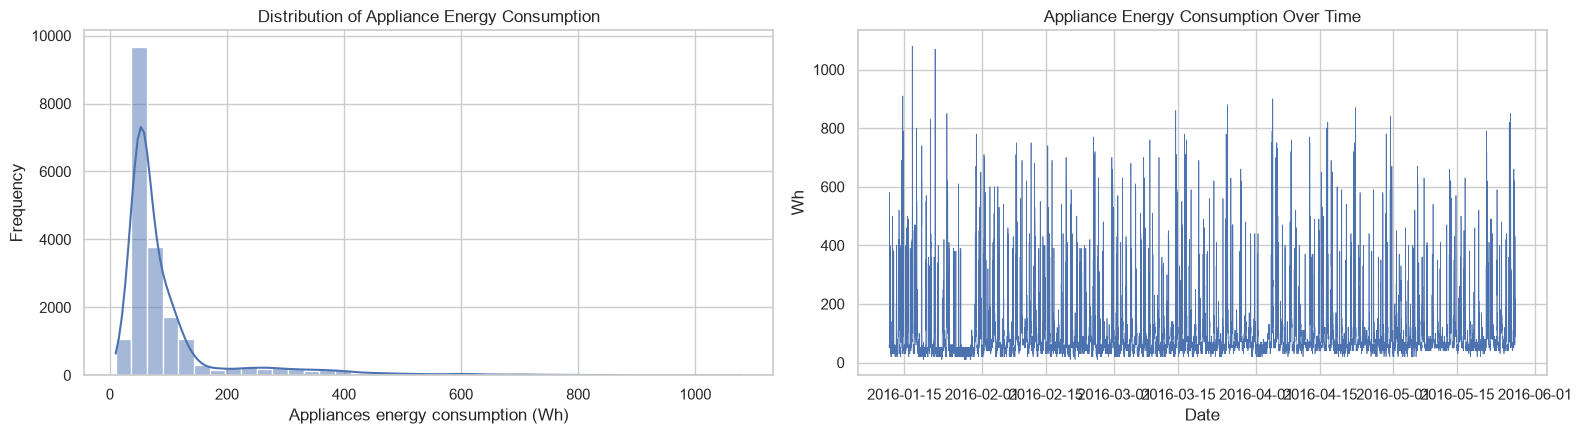

In [6]:
# Target distribution and time series
print("Appliances energy consumption statistics:")
display(df[TARGET].describe())

fig, axes = plt.subplots(1, 2, figsize=(16, 4.5))
sns.histplot(df[TARGET], bins=40, kde=True, ax=axes[0])
axes[0].set(title="Distribution of Appliance Energy Consumption",
            xlabel="Appliances energy consumption (Wh)", ylabel="Frequency")
axes[1].plot(df["date"], df[TARGET], linewidth=0.5)
axes[1].set(title="Appliance Energy Consumption Over Time",
            xlabel="Date", ylabel="Wh")
plt.tight_layout()
plt.show()

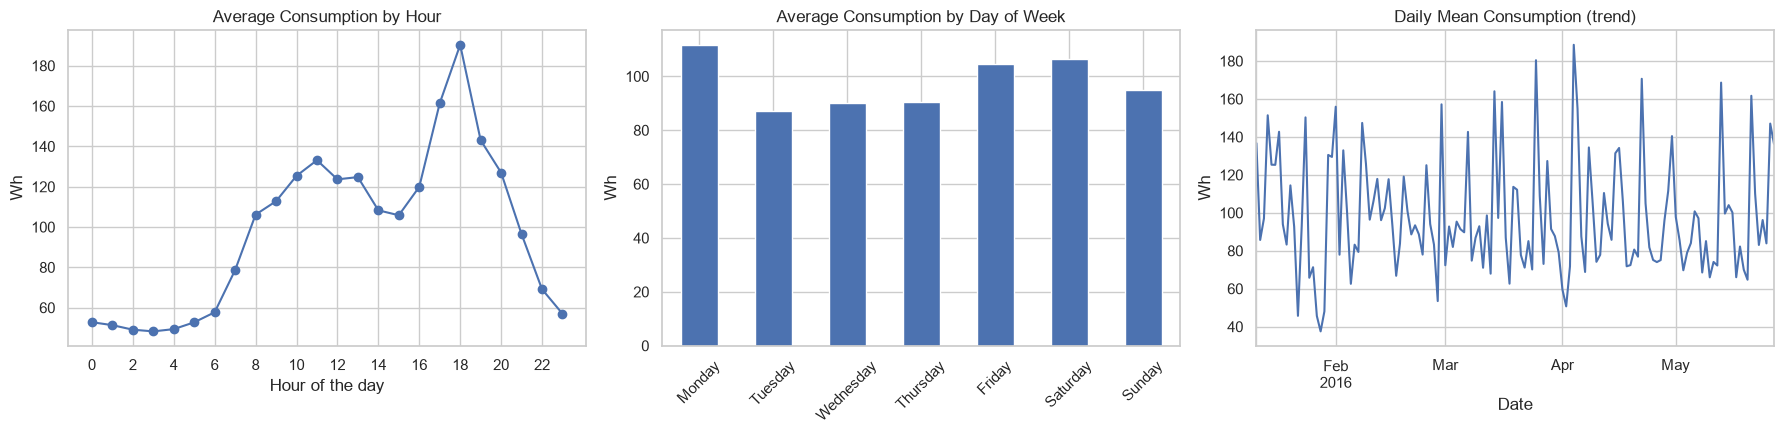

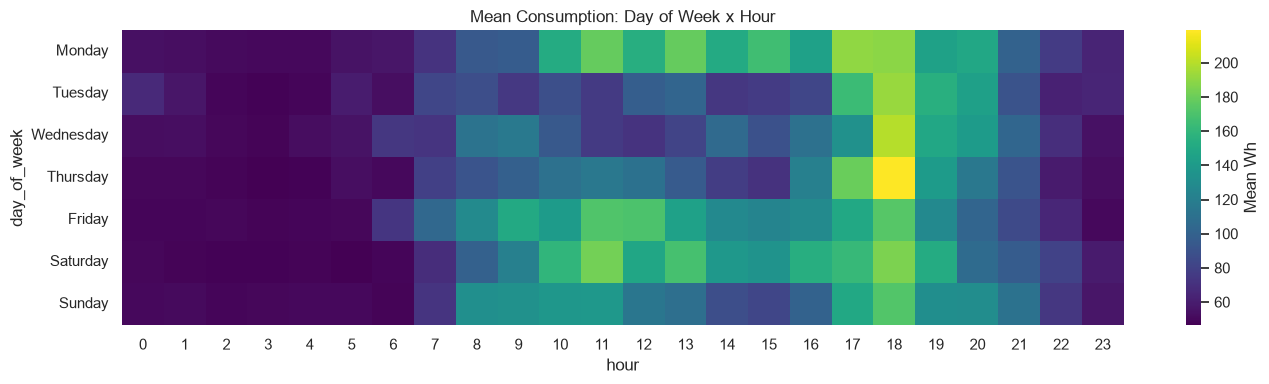

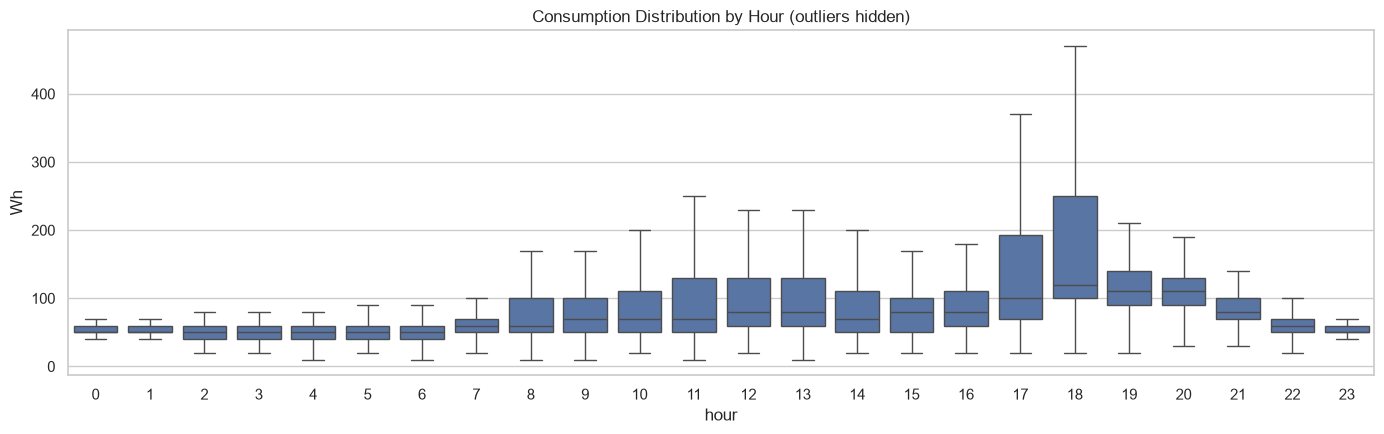

In [7]:
# Temporal patterns (hour of day, day of week, daily trend)
eda = df[["date", TARGET]].copy()
eda["hour"] = eda["date"].dt.hour
eda["day_of_week"] = eda["date"].dt.day_name()
day_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]

fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
eda.groupby("hour")[TARGET].mean().plot(marker="o", ax=axes[0])
axes[0].set(title="Average Consumption by Hour", xlabel="Hour of the day", ylabel="Wh")
axes[0].set_xticks(range(0, 24, 2))

eda.groupby("day_of_week")[TARGET].mean().reindex(day_order).plot(kind="bar", ax=axes[1])
axes[1].set(title="Average Consumption by Day of Week", xlabel="", ylabel="Wh")
axes[1].tick_params(axis="x", rotation=45)

eda.set_index("date")[TARGET].resample("D").mean().plot(ax=axes[2])
axes[2].set(title="Daily Mean Consumption (trend)", xlabel="Date", ylabel="Wh")
plt.tight_layout()
plt.show()

# Seasonal pattern heatmap: hour x day of week
pivot = eda.pivot_table(index="day_of_week", columns="hour", values=TARGET, aggfunc="mean").reindex(day_order)
plt.figure(figsize=(14, 4))
sns.heatmap(pivot, cmap="viridis", cbar_kws={"label": "Mean Wh"})
plt.title("Mean Consumption: Day of Week x Hour")
plt.tight_layout()
plt.show()

# Box plot by hour: spread and skew of consumption through the day
plt.figure(figsize=(14, 4.5))
sns.boxplot(data=eda, x="hour", y=TARGET, showfliers=False)
plt.title("Consumption Distribution by Hour (outliers hidden)")
plt.ylabel("Wh")
plt.tight_layout()
plt.show()

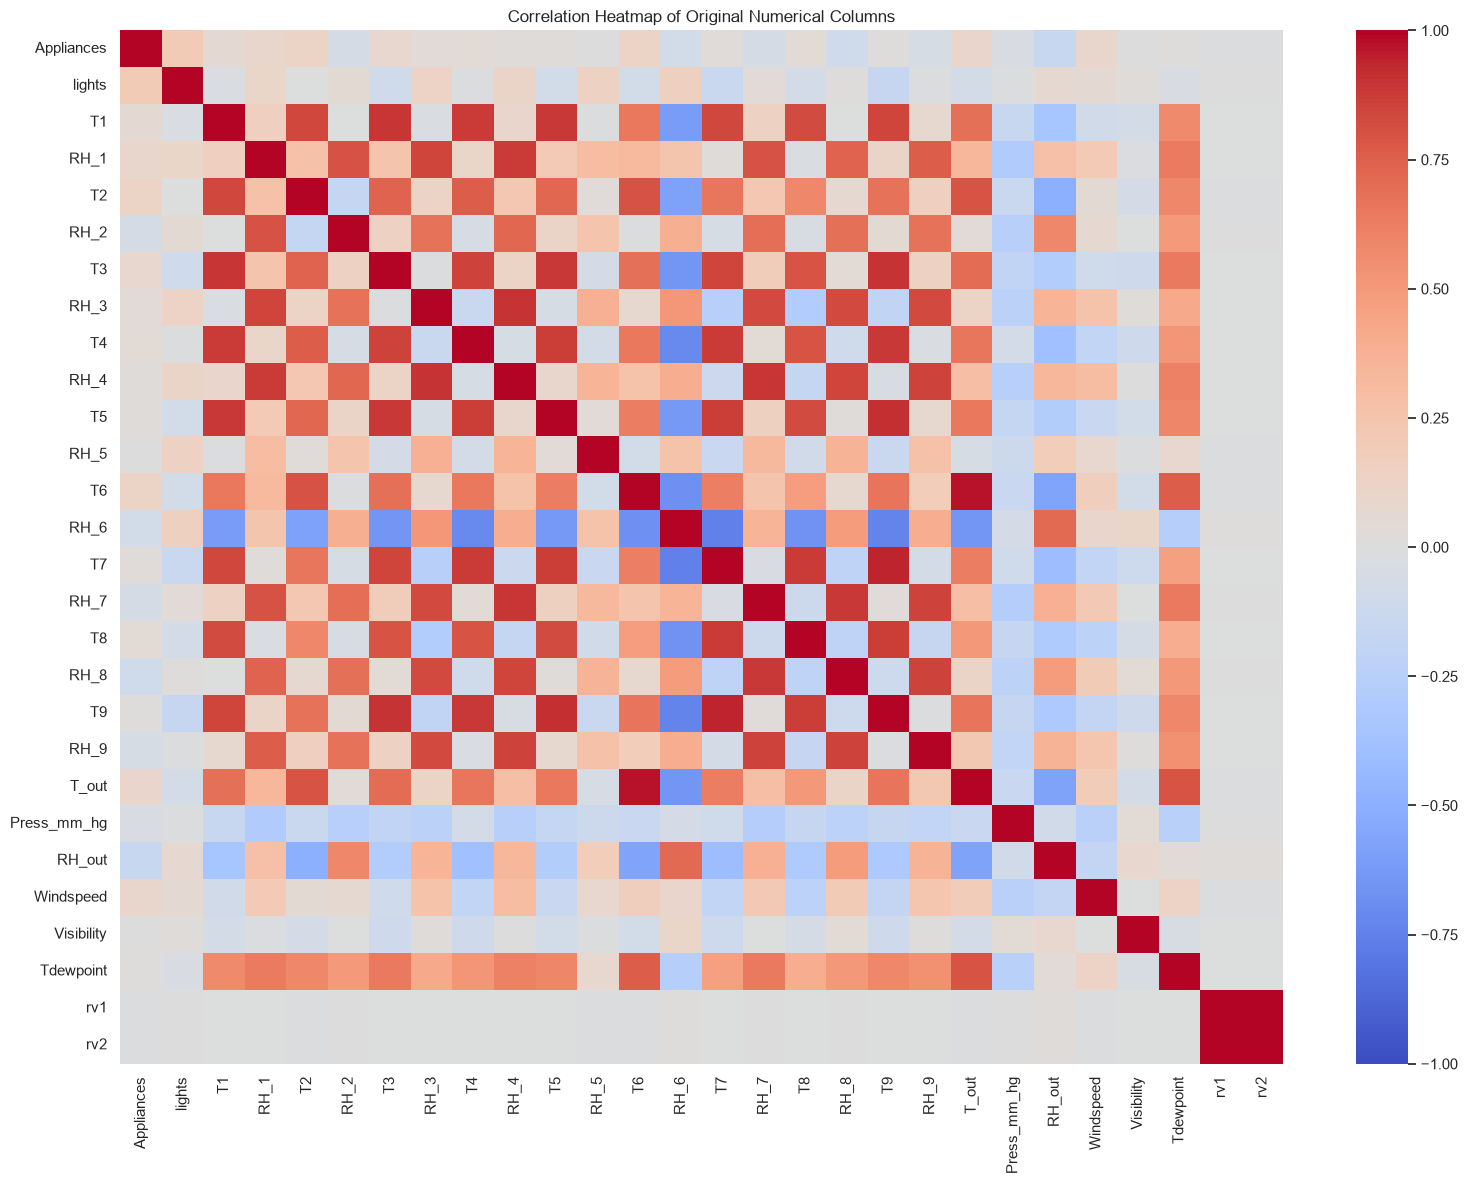

Original columns most correlated with Appliances:


,Correlation
lights,0.197278
RH_out,-0.152282
T2,0.120073
T6,0.117638
T_out,0.099155
RH_8,-0.094039
Windspeed,0.087122
RH_1,0.086031
T3,0.085060
RH_6,-0.083178


rv1 and rv2 identical: True
Correlation of rv1 with the target: -0.0111


In [8]:
# Correlation heatmap of the original numeric columns
numeric_df = df.select_dtypes(include="number")
correlation_matrix = numeric_df.corr()

plt.figure(figsize=(16, 12))
sns.heatmap(correlation_matrix, cmap="coolwarm", center=0, vmin=-1, vmax=1, annot=False)
plt.title("Correlation Heatmap of Original Numerical Columns")
plt.tight_layout()
plt.show()

target_correlations = (correlation_matrix[TARGET].drop(TARGET)
                       .sort_values(key=abs, ascending=False))
print("Original columns most correlated with Appliances:")
display(target_correlations.head(10).to_frame("Correlation"))

# rv1 and rv2 are documented as random variables; check whether they carry information
print("rv1 and rv2 identical:", bool(np.allclose(df["rv1"], df["rv2"])))
print("Correlation of rv1 with the target:", round(df["rv1"].corr(df[TARGET]), 4))

### EDA findings
The dataset contains 19,735 observations recorded every 10 minutes between 11 January and 27 May 2016. The target is right-skewed (median 60 Wh, mean ≈ 97.7 Wh, maximum 1,080 Wh). There are no missing values, duplicates, invalid or repeated timestamps and no negative consumption values; the 10-minute interval is perfectly regular.

* **Daily pattern:** consumption is lowest at night (about 48 Wh at 03:00) and highest in the evening (about 190 Wh at 18:00), with a smaller midday plateau. The day-of-week averages are similar (lowest Tuesday ≈ 87 Wh, highest Monday ≈ 112 Wh), and the hour × day-of-week heatmap shows the same evening peak on every day.
* **Correlations:** all linear correlations between the original columns and the target are weak (|r| < 0.2): `lights` (+0.20), `RH_out` (−0.15) and the indoor temperatures `T2`, `T6` (about +0.12). This already suggests that **past consumption** (autocorrelation) will matter much more than the sensors.
* `rv1` and `rv2` are random-number columns supplied with the data set: they are identical to each other and uncorrelated with the target (r = −0.01), so they must not be used as features.
* **Consequence for modelling:** time features and lagged/rolling consumption should help; high-consumption observations must be investigated rather than removed automatically.

### 1.5 Chronological train / test split (80 % / 20 %)
The data is a time series, so it is **never shuffled**: the first 80 % of the timeline is used for training and the last 20 % for testing. A part of the training period (the final 15 %) is later held out as a **validation set** (§2.6) for all model-selection decisions, so that the test set remains untouched until the final evaluation in section 4.

In [9]:
SPLIT_FRACTION = 0.80
SPLIT_INDEX = int(len(df) * SPLIT_FRACTION)   # first index of the test period

train_df = df.iloc[:SPLIT_INDEX].copy()
test_df = df.iloc[SPLIT_INDEX:].copy()

print("Total observations:", len(df))
print("Training observations:", len(train_df), f"({len(train_df) / len(df):.2%})")
print("Testing observations:", len(test_df), f"({len(test_df) / len(df):.2%})")
print("\nTraining period:", train_df["date"].min(), "to", train_df["date"].max())
print("Testing period: ", test_df["date"].min(), "to", test_df["date"].max())
assert train_df["date"].max() < test_df["date"].min()

Total observations: 19735
Training observations: 15788 (80.00%)
Testing observations: 3947 (20.00%)

Training period: 2016-01-11 17:00:00 to 2016-04-30 08:10:00
Testing period:  2016-04-30 08:20:00 to 2016-05-27 18:00:00


### 1.6 Outlier detection and treatment
Outliers are detected on the **training period only** with the IQR rule and the Z-score rule, and with box plots.

**Decision:** statistical outliers are **retained by default**. The high values are genuine appliance activity (cooking, laundry, ...) rather than sensor errors: all lie within the physically plausible range, and removing them would hide exactly the peaks the model is supposed to predict. The decision is not taken on belief alone: §3.2 measures the effect of capping the training target on validation accuracy.

Q1: 50.00 Wh | Q3: 100.00 Wh | IQR: 50.00 Wh
IQR bounds: -25.00 to 175.00 Wh
IQR outliers:     1776 (11.25%)
Z-score (|z|>3):  416 (2.63%)
Largest training value: 1080 Wh (physically plausible - kept)


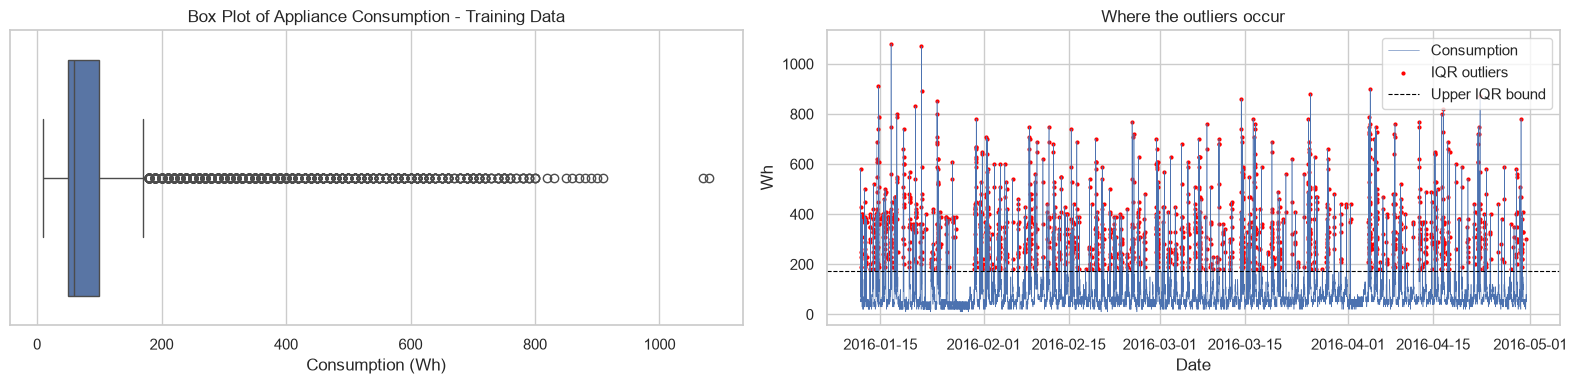

In [10]:
y_tr = train_df[TARGET]

# IQR rule
Q1, Q3 = y_tr.quantile(0.25), y_tr.quantile(0.75)
IQR = Q3 - Q1
lower_bound, upper_bound = Q1 - 1.5 * IQR, Q3 + 1.5 * IQR
iqr_outliers = train_df[(y_tr < lower_bound) | (y_tr > upper_bound)]

# Z-score rule
z = (y_tr - y_tr.mean()) / y_tr.std()
z_outliers = train_df[z.abs() > 3]

print(f"Q1: {Q1:.2f} Wh | Q3: {Q3:.2f} Wh | IQR: {IQR:.2f} Wh")
print(f"IQR bounds: {lower_bound:.2f} to {upper_bound:.2f} Wh")
print(f"IQR outliers:     {len(iqr_outliers)} ({len(iqr_outliers) / len(train_df):.2%})")
print(f"Z-score (|z|>3):  {len(z_outliers)} ({len(z_outliers) / len(train_df):.2%})")
print(f"Largest training value: {y_tr.max():.0f} Wh (physically plausible - kept)")

fig, axes = plt.subplots(1, 2, figsize=(16, 4))
sns.boxplot(x=y_tr, ax=axes[0])
axes[0].set(title="Box Plot of Appliance Consumption - Training Data", xlabel="Consumption (Wh)")
axes[1].plot(train_df["date"], y_tr, linewidth=0.4, label="Consumption")
axes[1].scatter(iqr_outliers["date"], iqr_outliers[TARGET], s=4, color="red", label="IQR outliers")
axes[1].axhline(upper_bound, color="black", linestyle="--", linewidth=0.8, label="Upper IQR bound")
axes[1].set(title="Where the outliers occur", xlabel="Date", ylabel="Wh")
axes[1].legend()
plt.tight_layout()
plt.show()

### 1.7 Scaling and normalization strategy
**Choice: Standardization (`StandardScaler`, zero mean / unit variance).** The inputs have very different units and ranges (temperatures in °C, humidity in %, visibility in metres, lags in Wh), and neural networks and linear models train poorly on such unscaled inputs. Standardization is preferred to Min-Max scaling because the target and several features are right-skewed with large peaks: Min-Max scaling would squeeze most values into a very small range, and unseen test peaks would fall outside [0, 1]. Tree-based models do not need scaling but are unaffected by it.

The scalers are **fitted on the training sub-set only** and then applied to the validation and test periods, so no test statistics leak into training. The implementation follows the feature engineering, because the scaler must be fitted on the final feature set (§3.1). The target is also standardized for the neural networks, and every prediction is **converted back to Wh** before any metric is computed.

## 2. Feature Engineering
**Objective:** create and select features that improve model performance.

### Forecasting setup (important)
The model predicts the consumption of interval *i* from information that is **available before interval *i* starts**:

* **Past consumption** — lags and rolling statistics are built from `Appliances` values of earlier intervals only.
* **Sensor and weather readings** — taken from the **previous** interval (shifted by one step). The readings of the same interval as the target would not exist yet in a real forecasting deployment.
* **Calendar information** (hour, weekday, month, holiday) — describes interval *i* itself; it is known in advance.

A leakage test in §2.6 verifies this property automatically.

### 2.1 – 2.5 Feature construction
The whole pipeline is wrapped in one function, `build_features`, so that it can be tested for leakage and re-used.

| Subtask | Features |
|---|---|
| 2.1 Time-based | hour, day of week, month, weekday/weekend indicator, cyclical sin/cos encodings (hour of day with minute resolution) |
| 2.2 Rolling windows | rolling mean over 1 h, 3 h and 24 h; rolling std over 1 h and 3 h (past values only) |
| 2.3 Lags | consumption 10, 20, 30 min, 1 h, 2 h, 3 h and 24 h earlier (chosen from the autocorrelation analysis below) |
| 2.4 Interactions | indoor T x RH (kitchen/living room region), outdoor T x RH |
| 2.5 Domain-specific | public-holiday flag, mean indoor temperature, mean indoor humidity, indoor-outdoor temperature difference, lighting-on indicator |

### 2.3a Autocorrelation analysis: choosing the lags
The lag periods are chosen from the autocorrelation function (ACF) of the **training** target. The ACF decays quickly over the first hour, shows a secondary bump around lag 10 (about 100 minutes, a typical usage cycle), and rises again at lag 144 (exactly 24 hours): consumption repeats day by day.

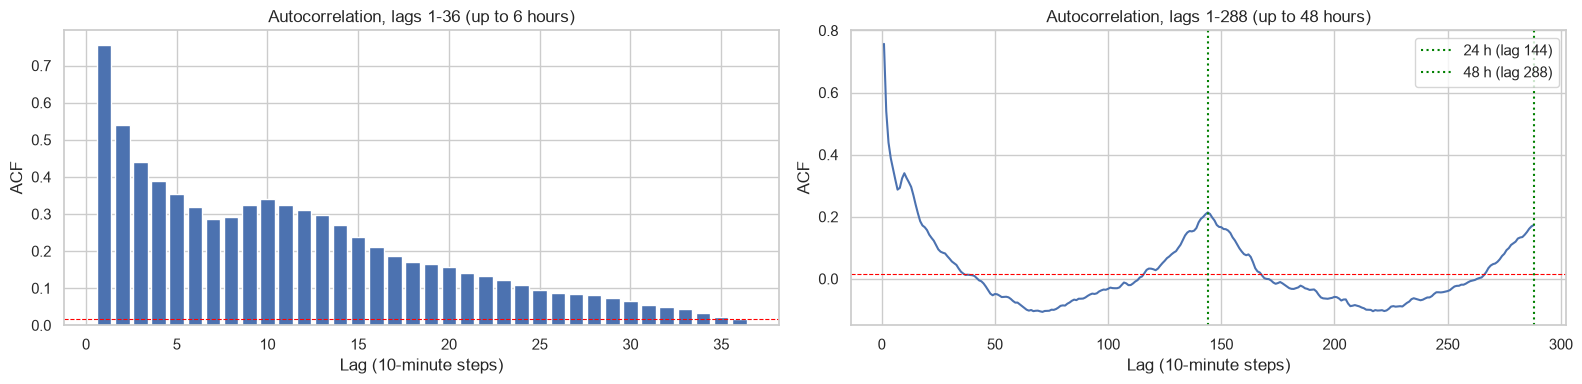

Selected lags and their training-set autocorrelation:


,lag (steps),time before target,ACF,significant
0,1,10 min,0.757,True
1,2,20 min,0.540,True
2,3,30 min,0.439,True
3,6,1 h,0.320,True
4,12,2 h,0.311,True
5,18,3 h,0.172,True
6,144,24 h,0.214,True


Strongest autocorrelations (excluding lags 1-3):


,|ACF|
4,0.388529
5,0.353992
10,0.340110
11,0.324520
9,0.323559
6,0.319804
12,0.311027
13,0.296132


In [11]:
y_train_target = train_df[TARGET]
n_train_raw = len(y_train_target)
conf = 2 / np.sqrt(n_train_raw)          # approximate 95 % significance band

acf = pd.Series({lag: y_train_target.autocorr(lag=lag) for lag in range(1, 289)}, name="ACF")

fig, axes = plt.subplots(1, 2, figsize=(16, 4))
axes[0].bar(acf.index[:36], acf.values[:36])
axes[0].axhline(conf, color="red", linestyle="--", linewidth=0.8)
axes[0].set(title="Autocorrelation, lags 1-36 (up to 6 hours)", xlabel="Lag (10-minute steps)", ylabel="ACF")
axes[1].plot(acf.index, acf.values)
axes[1].axhline(conf, color="red", linestyle="--", linewidth=0.8)
axes[1].axvline(144, color="green", linestyle=":", label="24 h (lag 144)")
axes[1].axvline(288, color="green", linestyle=":", label="48 h (lag 288)")
axes[1].set(title="Autocorrelation, lags 1-288 (up to 48 hours)", xlabel="Lag (10-minute steps)", ylabel="ACF")
axes[1].legend()
plt.tight_layout()
plt.show()

LAGS = [1, 2, 3, 6, 12, 18, 144]       # 10, 20, 30 min, 1 h, 2 h, 3 h, 24 h
print("Selected lags and their training-set autocorrelation:")
display(pd.DataFrame({
    "lag (steps)": LAGS,
    "time before target": [f"{l * 10} min" if l * 10 < 60 else f"{l * 10 / 60:g} h" for l in LAGS],
    "ACF": [round(acf[l], 3) for l in LAGS],
    "significant": [abs(acf[l]) > conf for l in LAGS],
}))
print("Strongest autocorrelations (excluding lags 1-3):")
display(acf.loc[4:].abs().sort_values(ascending=False).head(8).to_frame("|ACF|"))

In [12]:
# ---------------------------------------------------------------
# Feature construction (sections 2.1 - 2.5)
# ---------------------------------------------------------------
# Public holidays in Belgium (the measurements were taken in Belgium) within the
# measurement period 11 Jan - 27 May 2016: Easter Monday, Labour Day, Ascension, Whit Monday.
HOLIDAYS = pd.to_datetime(["2016-03-28", "2016-05-01", "2016-05-05", "2016-05-16"]).date

INDOOR_T = ["T1", "T2", "T3", "T4", "T5", "T7", "T8", "T9"]            # T6 is the outdoor north-side sensor
INDOOR_RH = ["RH_1", "RH_2", "RH_3", "RH_4", "RH_5", "RH_7", "RH_8", "RH_9"]
EXCLUDED = {"date", TARGET, "hour", "day_of_week", "month"}            # raw integer calendar columns: sin/cos versions are used


def build_features(raw):
    """Create all model features. Row i is built only from information known before interval i."""
    d = raw.copy()
    d["date"] = pd.to_datetime(d["date"], errors="coerce")
    d = (d.dropna(subset=["date"]).sort_values("date")
           .drop_duplicates(subset="date").reset_index(drop=True))

    # Sensor and weather readings come from the PREVIOUS interval (no look-ahead)
    sensors = [c for c in d.columns if c not in ("date", TARGET)]
    d[sensors] = d[sensors].shift(1)

    # 2.1 Time-based features of the interval being predicted
    d["hour"] = d["date"].dt.hour
    d["day_of_week"] = d["date"].dt.dayofweek
    d["month"] = d["date"].dt.month
    d["is_weekend"] = (d["day_of_week"] >= 5).astype(int)
    day_fraction = (d["date"].dt.hour * 60 + d["date"].dt.minute) / 1440
    d["hour_sin"] = np.sin(2 * np.pi * day_fraction)
    d["hour_cos"] = np.cos(2 * np.pi * day_fraction)
    d["day_sin"] = np.sin(2 * np.pi * d["day_of_week"] / 7)
    d["day_cos"] = np.cos(2 * np.pi * d["day_of_week"] / 7)
    d["month_sin"] = np.sin(2 * np.pi * (d["month"] - 1) / 12)
    d["month_cos"] = np.cos(2 * np.pi * (d["month"] - 1) / 12)

    # 2.2 Rolling statistics of PAST consumption (shift(1) excludes the current target)
    past = d[TARGET].shift(1)
    d["appliances_rolling_mean_1h"] = past.rolling(6, min_periods=6).mean()
    d["appliances_rolling_mean_3h"] = past.rolling(18, min_periods=18).mean()
    d["appliances_rolling_mean_24h"] = past.rolling(144, min_periods=144).mean()
    d["appliances_rolling_std_1h"] = past.rolling(6, min_periods=6).std()
    d["appliances_rolling_std_3h"] = past.rolling(18, min_periods=18).std()

    # 2.3 Lagged consumption
    for lag in LAGS:
        d[f"appliances_lag_{lag}"] = d[TARGET].shift(lag)

    # 2.4 Interaction features (computed from the already shifted sensor values)
    d["T2_RH2_interaction"] = d["T2"] * d["RH_2"]
    d["Tout_RHout_interaction"] = d["T_out"] * d["RH_out"]

    # 2.5 Domain-specific features
    d["is_holiday"] = d["date"].dt.date.isin(HOLIDAYS).astype(int)
    d["indoor_temp_mean"] = d[INDOOR_T].mean(axis=1)
    d["indoor_rh_mean"] = d[INDOOR_RH].mean(axis=1)
    d["indoor_outdoor_temp_diff"] = d["indoor_temp_mean"] - d["T_out"]
    d["lights_on"] = (d["lights"] > 0).astype(int)

    d = d.replace([np.inf, -np.inf], np.nan)
    return d


model_df = build_features(df)
FEATURE_POOL = [c for c in model_df.columns
                if c not in EXCLUDED and pd.api.types.is_numeric_dtype(model_df[c])]

print("Modelling table:", model_df.shape)
print("Candidate features:", len(FEATURE_POOL))
display(model_df[["date", TARGET, "hour_sin", "is_weekend", "is_holiday", "appliances_lag_1",
                  "appliances_lag_3", "appliances_rolling_mean_1h", "indoor_outdoor_temp_diff"]].iloc[150:155])

Modelling table: (19735, 58)
Candidate features: 53


,date,Appliances,hour_sin,is_weekend,is_holiday,appliances_lag_1,appliances_lag_3,appliances_rolling_mean_1h,indoor_outdoor_temp_diff
150,2016-01-12 18:00:00,80,-1.000000,0,0,230.0,380.0,218.333333,13.130000
151,2016-01-12 18:10:00,90,-0.999048,0,0,80.0,370.0,221.666667,13.355417
152,2016-01-12 18:20:00,70,-0.996195,0,0,90.0,230.0,226.666667,13.483750
153,2016-01-12 18:30:00,40,-0.991445,0,0,70.0,80.0,203.333333,13.595208
154,2016-01-12 18:40:00,40,-0.984808,0,0,40.0,90.0,146.666667,13.702917


### 2.6 Modelling table, train / validation / test split and leakage test
* The test boundary is the same chronological 80 % boundary as in §1.5.
* Rows whose lags/rolling windows reach before the start of the data (the first 144 rows, about one day) cannot be used and are dropped. They all belong to the training period.
* The last 15 % of the training period becomes the **validation set**. The **training sub-set** is what remains.
* The leakage test perturbs every raw value of interval *i* and checks that the features of row *i* do not change.

In [13]:
VAL_FRACTION = 0.15      # share of the training period kept for validation

# Same chronological boundary as section 1.5, then drop rows without full lag/rolling history
required = FEATURE_POOL + [TARGET]
train_ready = model_df.iloc[:SPLIT_INDEX].dropna(subset=required).copy()
test_ready = model_df.iloc[SPLIT_INDEX:].dropna(subset=required).copy()
assert len(test_ready) == len(test_df), "no test rows may be lost"

# One chronological timeline: training sub-set | validation | test
full = pd.concat([train_ready, test_ready], ignore_index=True)
n_train, n_test = len(train_ready), len(test_ready)
n_val = int(n_train * VAL_FRACTION)
n_sub = n_train - n_val

idx_sub = np.arange(0, n_sub)                       # training sub-set
idx_val = np.arange(n_sub, n_train)                 # validation (model selection)
idx_test = np.arange(n_train, n_train + n_test)     # test (final report only)

# The timeline must be contiguous and strictly chronological
assert (full["date"].diff().dropna() == STEP).all()
assert full.loc[n_sub - 1, "date"] < full.loc[n_sub, "date"] < full.loc[n_train, "date"]

print(f"Training sub-set: {len(idx_sub):6d} rows  {full.loc[idx_sub[0], 'date']}  ->  {full.loc[idx_sub[-1], 'date']}")
print(f"Validation:       {len(idx_val):6d} rows  {full.loc[idx_val[0], 'date']}  ->  {full.loc[idx_val[-1], 'date']}")
print(f"Test:             {len(idx_test):6d} rows  {full.loc[idx_test[0], 'date']}  ->  {full.loc[idx_test[-1], 'date']}")

Training sub-set:  13298 rows  2016-01-12 17:00:00  ->  2016-04-14 01:10:00
Validation:         2346 rows  2016-04-14 01:20:00  ->  2016-04-30 08:10:00
Test:               3947 rows  2016-04-30 08:20:00  ->  2016-05-27 18:00:00


In [14]:
# Leakage test: changing ANY raw value of interval k must not change the features of row k
k = 5000
raw_perturbed = df.copy()
value_cols = [c for c in df.columns if c != "date"]
raw_perturbed.loc[k, value_cols] = raw_perturbed.loc[k, value_cols] + 10_000.0

f_original = build_features(df)
f_perturbed = build_features(raw_perturbed)

same_row_k = np.allclose(f_original.loc[k, FEATURE_POOL].astype(float),
                         f_perturbed.loc[k, FEATURE_POOL].astype(float), equal_nan=True)
next_row_changed = not np.allclose(f_original.loc[k + 1, FEATURE_POOL].astype(float),
                                   f_perturbed.loc[k + 1, FEATURE_POOL].astype(float), equal_nan=True)

assert same_row_k, "LEAKAGE: features of row k depend on interval k"
assert next_row_changed, "Test sanity check failed: row k+1 should use interval k"
print("PASS: the features of row k do not depend on the raw values of interval k.")
print("PASS: row k+1 does use interval k (past information is available).")

PASS: the features of row k do not depend on the raw values of interval k.
PASS: row k+1 does use interval k (past information is available).


### 2.7 Feature selection
Feature selection uses the **training period only** (never the test period). Three independent views are combined:

1. **Correlation analysis** — absolute Pearson correlation with the target (|r| ≥ 0.05) and removal of duplicated columns.
2. **Tree-based importance** — Random Forest importances; keep features that make up 95 % of the cumulative importance.
3. **Recursive Feature Elimination (RFE)** — Ridge regression on standardized inputs, eliminating features until 25 remain.

A feature is kept when at least **2 of the 3 methods** select it. The result is then checked in two ways: (a) against the full set on the validation set, and (b) with a **walk-forward feature-group test** (§2.7b) that asks whether the raw sensor/weather columns are still useful when the season changes.

In [15]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.feature_selection import RFE
from sklearn.linear_model import Ridge
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

X_sel = full.loc[idx_sub, FEATURE_POOL]
y_sel = full.loc[idx_sub, TARGET]

# 0. Remove exactly duplicated columns (e.g. rv1 == rv2)
duplicated_cols = X_sel.columns[X_sel.T.duplicated(keep="first")].tolist()
pool = [c for c in FEATURE_POOL if c not in duplicated_cols]
print("Duplicated columns removed:", duplicated_cols)

# Method 1: correlation with the target
corr_with_target = X_sel[pool].corrwith(y_sel).abs().sort_values(ascending=False)
sel_corr = set(corr_with_target[corr_with_target >= 0.05].index)

# Method 2: random-forest importance (95 % cumulative importance)
rf_selector = RandomForestRegressor(n_estimators=200, min_samples_leaf=3, max_features=0.5,
                                    random_state=SEED, n_jobs=-1)
rf_selector.fit(X_sel[pool], y_sel)
importance = pd.Series(rf_selector.feature_importances_, index=pool).sort_values(ascending=False)
sel_rf = set(importance[importance.cumsum() - importance < 0.95].index)   # up to the feature that crosses 95 %

# Method 3: RFE with Ridge on standardized inputs
rfe = RFE(Ridge(alpha=1.0), n_features_to_select=25, step=2)
rfe.fit(StandardScaler().fit_transform(X_sel[pool]), y_sel)
sel_rfe = set(np.array(pool)[rfe.support_])

votes = pd.DataFrame({
    "corr |r|": corr_with_target.reindex(pool).round(3),
    "RF importance": importance.reindex(pool).round(4),
    "corr": [c in sel_corr for c in pool],
    "RF": [c in sel_rf for c in pool],
    "RFE": [c in sel_rfe for c in pool],
}, index=pool)
votes["votes"] = votes[["corr", "RF", "RFE"]].sum(axis=1)
votes = votes.sort_values(["votes", "RF importance"], ascending=False)
display(votes)

voted_features = votes.index[votes["votes"] >= 2].tolist()
print(f"\nFeatures with >= 2 votes: {len(voted_features)} of {len(pool)}")
print("Dropped:", [c for c in pool if c not in voted_features])

Duplicated columns removed: ['rv2']


,corr |r|,RF importance,corr,RF,RFE,votes
appliances_lag_1,0.761,0.4363,True,True,True,3
appliances_rolling_mean_1h,0.595,0.0778,True,True,True,3
appliances_lag_2,0.550,0.0638,True,True,True,3
appliances_rolling_std_3h,0.526,0.0265,True,True,True,3
appliances_lag_3,0.449,0.0182,True,True,True,3
hour_sin,0.281,0.0167,True,True,True,3
appliances_rolling_mean_3h,0.516,0.0167,True,True,True,3
hour_cos,0.196,0.0131,True,True,True,3
appliances_lag_6,0.330,0.0085,True,True,True,3
T4,0.066,0.0080,True,True,True,3



Features with >= 2 votes: 33 of 52
Dropped: ['lights', 'RH_3', 'RH_4', 'T5', 'RH_5', 'T7', 'RH_7', 'T9', 'Press_mm_hg', 'Visibility', 'Tdewpoint', 'rv1', 'is_weekend', 'day_sin', 'day_cos', 'month_sin', 'month_cos', 'is_holiday', 'indoor_rh_mean']


Validation RMSE, all 52 features:       61.293 Wh
Validation RMSE, selected 33 features: 61.610 Wh
-> The voted subset is as good as the full set on the validation set: it is used as the candidate.


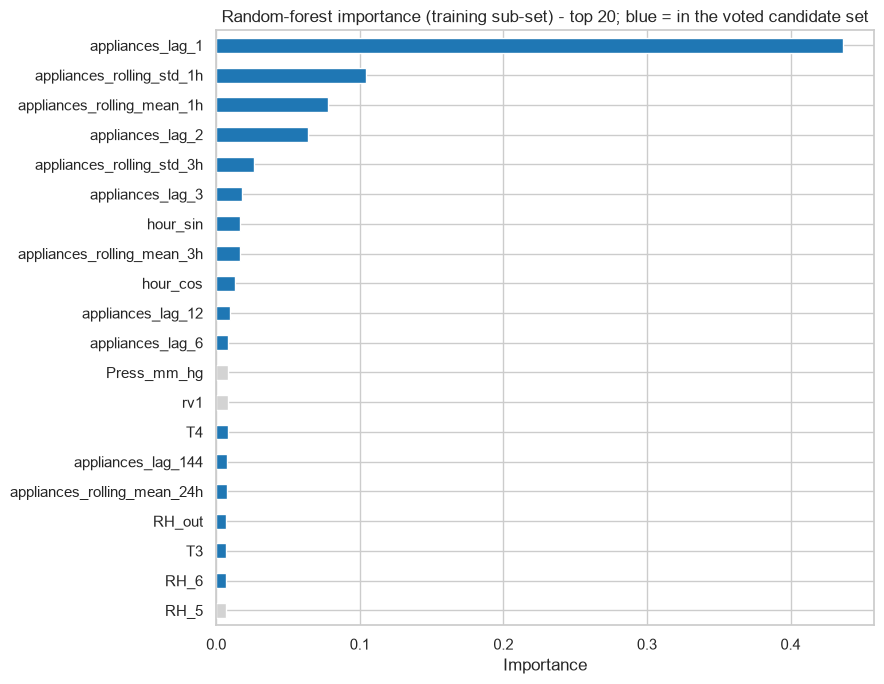

In [16]:
# Validation check: is the reduced feature set at least as good as the full one?
def quick_val_rmse(features):
    model = RandomForestRegressor(n_estimators=150, min_samples_leaf=3, max_features=0.5,
                                  random_state=SEED, n_jobs=-1)
    model.fit(full.loc[idx_sub, features], full.loc[idx_sub, TARGET])
    pred = model.predict(full.loc[idx_val, features])
    return np.sqrt(mean_squared_error(full.loc[idx_val, TARGET], pred))

rmse_all = quick_val_rmse(pool)
rmse_voted = quick_val_rmse(voted_features)
print(f"Validation RMSE, all {len(pool)} features:       {rmse_all:.3f} Wh")
print(f"Validation RMSE, selected {len(voted_features)} features: {rmse_voted:.3f} Wh")

if rmse_voted <= rmse_all * 1.01:
    print("-> The voted subset is as good as the full set on the validation set: it is used as the candidate.")
else:
    voted_features = pool
    print("-> Reduction hurts validation accuracy; the full set is used as the candidate.")

plt.figure(figsize=(9, 7))
importance.head(20).sort_values().plot(kind="barh", color=["tab:blue" if c in voted_features else "lightgray" for c in importance.head(20).sort_values().index])
plt.title("Random-forest importance (training sub-set) - top 20; blue = in the voted candidate set")
plt.xlabel("Importance")
plt.tight_layout()
plt.show()

### 2.7b Walk-forward feature-group test (robustness to seasonal drift)
The data covers January to May, so the weather changes systematically: the mean outdoor temperature is far higher in the later weeks than in the early ones. A model that relies on the **absolute value** of temperature or humidity can look good on a validation block taken from the same season as the training data and then fail later. A single validation block cannot reveal this, so the candidate feature sets are compared with **walk-forward (expanding-window) validation inside the training period**: five consecutive folds, each trained on everything before it and tested on the next block. The test period is not used.

Candidate sets: the voted set; the voted set without the raw indoor/outdoor environment columns; the voted set without the outdoor weather columns only; and all past-consumption + calendar features.

In [17]:
from sklearn.model_selection import TimeSeriesSplit
from sklearn.pipeline import make_pipeline

PAST_COLS = [c for c in pool if c.startswith("appliances_")]
TIME_COLS = ["hour_sin", "hour_cos", "day_sin", "day_cos", "month_sin", "month_cos", "is_weekend", "is_holiday"]
OUTDOOR_COLS = ["T6", "RH_6", "T_out", "RH_out", "Press_mm_hg", "Windspeed", "Visibility", "Tdewpoint",
                "Tout_RHout_interaction", "indoor_outdoor_temp_diff"]

candidate_sets = {
    "voted set": voted_features,
    "voted, no environment columns": [c for c in voted_features if c in PAST_COLS + TIME_COLS],
    "voted, no outdoor weather": [c for c in voted_features if c not in OUTDOOR_COLS],
    "all past-consumption + calendar": [c for c in pool if c in PAST_COLS + TIME_COLS],
}

train_period = full.loc[np.concatenate([idx_sub, idx_val])]          # training period only - no test rows
y_period = train_period[TARGET].to_numpy()
folds = list(TimeSeriesSplit(n_splits=5).split(train_period))

rows = []
for set_name, feats in candidate_sets.items():
    for model_name in ["Random Forest", "Ridge"]:
        fold_rmse = []
        for tr, te in folds:
            if model_name == "Random Forest":
                m = RandomForestRegressor(n_estimators=100, min_samples_leaf=3, max_features=0.5,
                                          random_state=SEED, n_jobs=-1)
            else:
                m = make_pipeline(StandardScaler(), Ridge(alpha=1.0))
            m.fit(train_period.iloc[tr][feats], y_period[tr])
            fold_rmse.append(np.sqrt(mean_squared_error(y_period[te], m.predict(train_period.iloc[te][feats]))))
        rows.append({"Feature set": set_name, "Model": model_name, "# features": len(feats),
                     "Mean RMSE (Wh)": np.mean(fold_rmse), "Worst fold (Wh)": np.max(fold_rmse),
                     **{f"fold {k + 1}": v for k, v in enumerate(fold_rmse)}})
walk_forward = pd.DataFrame(rows)
display(walk_forward.round(2))

# Choose by random-forest walk-forward RMSE; among near-ties (within 1 %) prefer the smaller set
rf_rows = walk_forward[walk_forward["Model"] == "Random Forest"].set_index("Feature set")
best_rmse = rf_rows["Mean RMSE (Wh)"].min()
near_best = rf_rows[rf_rows["Mean RMSE (Wh)"] <= best_rmse * 1.01].sort_values("# features")
chosen_set = near_best.index[0]
FEATURES = candidate_sets[chosen_set]
print(f"\n-> Selected feature set: '{chosen_set}' ({len(FEATURES)} features)")
print(FEATURES)

,Feature set,Model,# features,Mean RMSE (Wh),Worst fold (Wh),fold 1,fold 2,fold 3,fold 4,fold 5
0,voted set,Random Forest,33,65.54,73.37,73.37,64.48,63.77,64.17,61.89
1,voted set,Ridge,33,66.75,71.71,71.71,65.96,66.51,65.46,64.09
2,"voted, no environment columns",Random Forest,14,63.85,73.23,73.23,63.19,61.17,61.82,59.85
3,"voted, no environment columns",Ridge,14,66.30,70.96,70.96,65.84,65.38,65.22,64.08
4,"voted, no outdoor weather",Random Forest,26,65.19,73.11,73.11,64.95,62.44,63.04,62.41
5,"voted, no outdoor weather",Ridge,26,66.57,71.56,71.56,65.79,66.12,65.31,64.06
6,all past-consumption + calendar,Random Forest,20,63.64,72.73,72.73,62.85,60.62,62.07,59.95
7,all past-consumption + calendar,Ridge,20,66.38,71.14,71.14,65.97,65.38,65.30,64.10



-> Selected feature set: 'voted, no environment columns' (14 features)
['appliances_lag_1', 'appliances_rolling_mean_1h', 'appliances_lag_2', 'appliances_rolling_std_3h', 'appliances_lag_3', 'hour_sin', 'appliances_rolling_mean_3h', 'hour_cos', 'appliances_lag_6', 'appliances_lag_18', 'appliances_rolling_std_1h', 'appliances_lag_12', 'appliances_rolling_mean_24h', 'appliances_lag_144']


### Justification of the selected features
* **Removed by design:** `rv2` (exact duplicate of `rv1`). `rv1` received only one vote (the random forest gives a noise column a small non-zero importance, which is why several independent methods are combined) and was dropped.
* **Voting result:** 33 of the 52 non-duplicate candidates received at least 2 votes. Calendar columns such as `is_weekend`, `is_holiday`, `day_sin/cos` and `month_sin/cos` received 0–1 votes: the weekly pattern is weak (§1.4) and the data contains only four public holidays and about four months, so there is nothing to learn from them. The hour-of-day encodings (`hour_sin`, `hour_cos`) were kept by all three methods.
* **Consumption history dominates:** `appliances_lag_1` alone carries 44 % of the random-forest importance, followed by the 1-hour rolling mean/std and lags 2 and 3 — in line with the autocorrelation analysis.
* **Validation check (§2.7):** the 33-feature voted set scores 61.6 Wh validation RMSE against 61.3 Wh for all 52 features, i.e. the reduction costs nothing.
* **Walk-forward group test (§2.7b), training period only:** mean RMSE of the random forest over the five walk-forward folds was 65.5 Wh for the voted set, 65.2 Wh without outdoor weather, 63.9 Wh **without any raw environment column**, and 63.6 Wh for all past-consumption + calendar features (Ridge shows the same ordering). The raw indoor/outdoor sensor columns therefore do not improve forecasts and make them less stable as the season changes. **Selected: the 14 features of the set "voted, no environment columns"** (7 lags: 10, 20, 30 min, 1, 2, 3 h and 24 h; rolling mean 1 h/3 h/24 h; rolling std 1 h/3 h; `hour_sin`, `hour_cos`), which is within 1 % of the best set and the smaller of the two near-ties.
* **Transparency note:** this group test was added after the first run showed that a sensor-based random forest degraded badly on the later (warmer) weeks. The test itself, and the selection it drives, use only training-period data; the test period was never used to pick the features. The sensor columns are still available in the table and the group test can be re-run if another data set is used.

## 3. Model Development
**Objective:** design and implement a deep-learning model that predicts energy consumption, and decide every design choice from evidence.

**Rules followed in this section**
* Every decision (architecture, activation, optimizer, loss, regularization, look-back) is made on the **validation set** only. The test set is not looked at until section 4.
* Experiments change **one design factor at a time** and carry the winner forward. A change is accepted only if it improves validation RMSE by at least 0.5 %; otherwise the simpler/default choice is kept, because single-run differences below that size are within training noise.
* Every model is trained on the chronological training sub-set with early stopping on the validation loss, and every metric is computed in **Wh** after inverse-transforming the predictions.

### 3.1 Data preparation for the models: scaling and sequence windows
* `StandardScaler` for the inputs and the target, **fitted on the training sub-set only**.
* Sequence models receive a window of the last *L* rows. The window for target row *i* covers rows *i − L + 1 … i*. **Row *i* is included on purpose:** its features (lags, rolling statistics, previous-interval sensors, calendar of interval *i*) are exactly the information available before interval *i*, and it is the row that holds the most recent consumption value. The earlier version ended the window at row *i − 1* and therefore hid the latest consumption from the networks.
* Windows at the start of the validation/test periods use the end of the preceding period as history (past information only).

In [18]:
import time
import tensorflow as tf
from tensorflow.keras import Sequential, regularizers
from tensorflow.keras.layers import (Input, LSTM, GRU, Dense, Dropout, Conv1D, Flatten)
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

# ---- scaling: fitted on the training sub-set only ----
y_full = full[TARGET].to_numpy(dtype=np.float32)
x_scaler = StandardScaler().fit(full.loc[idx_sub, FEATURES])
y_scaler = StandardScaler().fit(y_full[idx_sub].reshape(-1, 1))

X_scaled = x_scaler.transform(full[FEATURES]).astype(np.float32)
y_scaled = y_scaler.transform(y_full.reshape(-1, 1)).astype(np.float32).ravel()
print("Scaled feature matrix:", X_scaled.shape, "| features:", len(FEATURES))
print("Target scaler (training sub-set): mean = %.2f Wh, std = %.2f Wh" % (y_scaler.mean_[0], y_scaler.scale_[0]))


# ---- sequence windows: the window for target row i is rows i-L+1 ... i ----
def make_windows(lookback, idx):
    idx = idx[idx >= lookback - 1]
    X = np.stack([X_scaled[i - lookback + 1: i + 1] for i in idx]).astype(np.float32)
    return X, y_scaled[idx], idx

_sequence_cache = {}
def get_sequence_data(lookback):
    if lookback not in _sequence_cache:
        Xtr, ytr, itr = make_windows(lookback, idx_sub)
        Xva, yva, iva = make_windows(lookback, idx_val)
        Xte, yte, ite = make_windows(lookback, idx_test)
        assert len(iva) == len(idx_val) and len(ite) == len(idx_test)   # no validation/test sample lost
        _sequence_cache[lookback] = dict(Xtr=Xtr, ytr=ytr, Xva=Xva, yva=yva, Xte=Xte, yte=yte)
    return _sequence_cache[lookback]


# ---- metrics and prediction helpers (always in Wh) ----
def regression_metrics(y_true, y_pred):
    y_true = np.asarray(y_true, dtype=float).ravel()
    y_pred = np.asarray(y_pred, dtype=float).ravel()
    err = y_true - y_pred
    nonzero = y_true != 0
    return {
        "MAE (Wh)": mean_absolute_error(y_true, y_pred),
        "RMSE (Wh)": float(np.sqrt(mean_squared_error(y_true, y_pred))),
        "MAPE (%)": float(np.mean(np.abs(err[nonzero] / y_true[nonzero])) * 100),
        "R²": r2_score(y_true, y_pred),
    }

def predict_wh(model, X):
    scaled = model.predict(X, batch_size=1024, verbose=0).reshape(-1, 1)
    return y_scaler.inverse_transform(scaled).ravel()

y_val_wh = y_full[idx_val]
y_test_wh = y_full[idx_test]

Scaled feature matrix: (19591, 14) | features: 14
Target scaler (training sub-set): mean = 98.31 Wh, std = 106.56 Wh


In [19]:
# ---- automatic alignment test (replaces the old debugging cells) ----
L = 12
d = get_sequence_data(L)
lag1_col = FEATURES.index("appliances_lag_1") if "appliances_lag_1" in FEATURES else None

# 1) the last row of every window is the target row itself (it carries lag_1 = previous consumption)
for i in [idx_sub[L], idx_val[0], idx_val[100], idx_test[0], idx_test[-1]]:
    window, _, _ = make_windows(L, np.array([i]))
    np.testing.assert_allclose(window[0, -1], X_scaled[i])
    if lag1_col is not None:
        raw_row = x_scaler.inverse_transform(window[0, -1:])[0]
        assert np.isclose(raw_row[lag1_col], y_full[i - 1], atol=1e-3), "last window row must hold y[i-1]"

# 2) the first test window ends at the first test row and starts in the training period
w0, _, _ = make_windows(L, np.array([idx_test[0]]))
np.testing.assert_allclose(w0[0], X_scaled[idx_test[0] - L + 1: idx_test[0] + 1])
assert idx_test[0] - L + 1 < idx_test[0]

# 3) one window per target, targets aligned with rows
assert len(d["Xte"]) == len(y_test_wh) == len(idx_test)
np.testing.assert_allclose(y_scaler.inverse_transform(d["yte"].reshape(-1, 1)).ravel(), y_test_wh, rtol=1e-5)
print("PASS: windows end at the target row and carry the latest consumption (lag_1 = y[i-1]).")
print("PASS: windows, targets and index ranges are aligned. Train/val/test windows:",
      d["Xtr"].shape, d["Xva"].shape, d["Xte"].shape)

PASS: windows end at the target row and carry the latest consumption (lag_1 = y[i-1]).
PASS: windows, targets and index ranges are aligned. Train/val/test windows: (13287, 12, 14) (2346, 12, 14) (3947, 12, 14)


### 3.2 Baseline models
Simple models establish the benchmark that the deep-learning models must beat:

* **Persistence** — predict the previous interval's consumption (`appliances_lag_1`).
* **Seasonal persistence** — predict the consumption 24 hours earlier (`appliances_lag_144`).
* **Linear Regression** and **Ridge Regression** (regularization strength chosen on the validation set).
* **Random Forest**.

All baselines use the same selected features, the same training sub-set and the same information as the neural networks. Validation metrics drive decisions; test predictions are stored and only reported in section 4.

In [20]:
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LinearRegression

Xf_sub, Xf_val, Xf_test = (full.loc[i, FEATURES] for i in (idx_sub, idx_val, idx_test))
y_sub_wh = y_full[idx_sub]

baseline_val_pred, baseline_test_pred = {}, {}

# Persistence baselines (no training)
for name, col in [("Persistence", "appliances_lag_1"), ("Seasonal persistence (24 h)", "appliances_lag_144")]:
    baseline_val_pred[name] = full.loc[idx_val, col].to_numpy()
    baseline_test_pred[name] = full.loc[idx_test, col].to_numpy()

# Linear regression
linear_model = make_pipeline(StandardScaler(), LinearRegression()).fit(Xf_sub, y_sub_wh)
baseline_val_pred["Linear Regression"] = linear_model.predict(Xf_val)
baseline_test_pred["Linear Regression"] = linear_model.predict(Xf_test)

# Ridge regression: alpha chosen on the validation set
ridge_rows = []
for alpha in [0.1, 1, 10, 100, 1000, 5000]:
    m = make_pipeline(StandardScaler(), Ridge(alpha=alpha)).fit(Xf_sub, y_sub_wh)
    ridge_rows.append((alpha, regression_metrics(y_val_wh, m.predict(Xf_val))["RMSE (Wh)"]))
best_alpha = min(ridge_rows, key=lambda r: r[1])[0]
print("Ridge validation RMSE by alpha:", [(a, round(r, 3)) for a, r in ridge_rows], "-> alpha =", best_alpha)
ridge_model = make_pipeline(StandardScaler(), Ridge(alpha=best_alpha)).fit(Xf_sub, y_sub_wh)
baseline_val_pred["Ridge Regression"] = ridge_model.predict(Xf_val)
baseline_test_pred["Ridge Regression"] = ridge_model.predict(Xf_test)

# Random forest
rf_model = RandomForestRegressor(n_estimators=200, min_samples_leaf=3, max_features=0.5,
                                 random_state=SEED, n_jobs=-1).fit(Xf_sub, y_sub_wh)
baseline_val_pred["Random Forest"] = rf_model.predict(Xf_val)
baseline_test_pred["Random Forest"] = rf_model.predict(Xf_test)

baseline_val_results = pd.DataFrame(
    [{"Model": n, **regression_metrics(y_val_wh, p)} for n, p in baseline_val_pred.items()]
).sort_values("RMSE (Wh)").reset_index(drop=True)
print("\nBaseline models - VALIDATION results")
display(baseline_val_results.round(4))

Ridge validation RMSE by alpha: [(0.1, 62.78), (1, 62.781), (10, 62.787), (100, 62.85), (1000, 63.675), (5000, 66.936)] -> alpha = 0.1



Baseline models - VALIDATION results


,Model,MAE (Wh),RMSE (Wh),MAPE (%),R²
0,Random Forest,26.1851,57.5794,25.0078,0.6450
1,Linear Regression,27.8732,62.7804,26.5773,0.5779
2,Ridge Regression,27.8732,62.7804,26.5773,0.5779
3,Persistence,27.5874,69.9269,22.6342,0.4764
4,Seasonal persistence (24 h),54.7528,117.5915,54.8433,-0.4808


In [21]:
# Does treating the outliers help?  Cap the TRAINING target at the IQR upper bound and compare on the
# validation set (validation targets are left untouched, so peaks are still judged).
clip_value = upper_bound
rows = []
for target_name, y_fit in [("Outliers retained", y_sub_wh), (f"Target capped at {clip_value:.0f} Wh", np.minimum(y_sub_wh, clip_value))]:
    lin = make_pipeline(StandardScaler(), LinearRegression()).fit(Xf_sub, y_fit)
    rf = RandomForestRegressor(n_estimators=200, min_samples_leaf=3, max_features=0.5,
                               random_state=SEED, n_jobs=-1).fit(Xf_sub, y_fit)
    for model_name, m in [("Linear Regression", lin), ("Random Forest", rf)]:
        rows.append({"Training target": target_name, "Model": model_name,
                     **regression_metrics(y_val_wh, m.predict(Xf_val))})
outlier_impact = pd.DataFrame(rows)
print("Impact of outlier treatment on validation accuracy:")
display(outlier_impact.round(4))

Impact of outlier treatment on validation accuracy:


,Training target,Model,MAE (Wh),RMSE (Wh),MAPE (%),R²
0,Outliers retained,Linear Regression,27.8732,62.7804,26.5773,0.5779
1,Outliers retained,Random Forest,26.1851,57.5794,25.0078,0.6450
2,Target capped at 175 Wh,Linear Regression,31.9158,79.7251,24.4338,0.3193
3,Target capped at 175 Wh,Random Forest,29.5816,77.5243,21.2408,0.3564


**Outlier decision.** Capping the training target at the IQR upper bound (175 Wh) makes the validation RMSE much **worse** (Linear Regression 62.8 → 79.7 Wh, Random Forest 57.6 → 77.5 Wh) and R² drops from 0.58–0.65 to 0.32–0.36. It lowers only the MAPE, which is a percentage and therefore dominated by the many small values. The high values are genuine consumption peaks that the model is judged on, so the outliers are **retained** (no removal, no capping) in all later steps.

### 3.3 Deep-learning model design: choosing the architecture
Candidate architectures (all use the same inputs, loss, optimizer and early stopping, so the comparison isolates the architecture):

| Name | Design | Why it is a candidate |
|---|---|---|
| LSTM-1L / LSTM-2L | 1 or 2 stacked LSTM layers (64 → 32 units) + dense head | gated memory, standard for sequences; the earlier version used LSTM-2L |
| GRU-1L / GRU-2L | 1 or 2 stacked GRU layers | fewer parameters than LSTM, often equally accurate; the earlier version used GRU-1L |
| CNN-LSTM | 2 × Conv1D (local patterns) → LSTM (temporal order) | convolutions extract short-term shape features before the recurrent layer |
| MLP | flattened window → dense layers | a *non-sequential* deep model: checks whether recurrence is needed at all |

Common starting settings: 12-step look-back (2 hours), tanh recurrent activation, ReLU dense activation, dropout 0.2, Adam (learning rate 0.001), MSE loss, early stopping (patience 6) and learning-rate reduction on plateau.

In [22]:
BASE_CFG = dict(arch="LSTM", units=(64, 32), dense=16, rnn_act="tanh", dense_act="relu",
                dropout=0.2, l2=0.0, optimizer="adam", lr=1e-3, loss="mse", lookback=12)
MAX_EPOCHS, BATCH_SIZE, PATIENCE = 40, 128, 6


def make_optimizer(name, lr):
    name = name.lower()
    if name == "adam":    return tf.keras.optimizers.Adam(learning_rate=lr, clipnorm=1.0)
    if name == "rmsprop": return tf.keras.optimizers.RMSprop(learning_rate=lr, clipnorm=1.0)
    if name == "nadam":   return tf.keras.optimizers.Nadam(learning_rate=lr, clipnorm=1.0)
    if name == "sgd":     return tf.keras.optimizers.SGD(learning_rate=lr, momentum=0.9, clipnorm=1.0)
    raise ValueError(name)

def make_loss(name):
    if name == "huber":   # delta = 1 standard deviation of the (standardized) target
        return tf.keras.losses.Huber(delta=1.0)
    return name           # "mse" or "mae"


def build_model(cfg, n_features):
    reg = regularizers.l2(cfg["l2"]) if cfg["l2"] else None
    layers = [Input(shape=(cfg["lookback"], n_features))]
    arch, units = cfg["arch"], cfg["units"]
    if arch in ("LSTM", "GRU"):
        Rnn = LSTM if arch == "LSTM" else GRU
        for k, u in enumerate(units):
            layers += [Rnn(u, activation=cfg["rnn_act"], return_sequences=k < len(units) - 1,
                           kernel_regularizer=reg),
                       Dropout(cfg["dropout"])]
    elif arch == "CNN-LSTM":
        layers += [Conv1D(32, 3, padding="same", activation=cfg["dense_act"], kernel_regularizer=reg),
                   Conv1D(32, 3, padding="same", activation=cfg["dense_act"], kernel_regularizer=reg),
                   LSTM(units[0], activation=cfg["rnn_act"], kernel_regularizer=reg),
                   Dropout(cfg["dropout"])]
    elif arch == "MLP":
        layers.append(Flatten())
        for u in units:
            layers += [Dense(u, activation=cfg["dense_act"], kernel_regularizer=reg), Dropout(cfg["dropout"])]
    else:
        raise ValueError(arch)
    if cfg["dense"]:        # dense = 0 -> no extra dense head (single hidden layer models, section 5)
        layers.append(Dense(cfg["dense"], activation=cfg["dense_act"], kernel_regularizer=reg))
    layers.append(Dense(1))
    model = Sequential(layers)
    model.compile(optimizer=make_optimizer(cfg["optimizer"], cfg["lr"]), loss=make_loss(cfg["loss"]), metrics=["mae"])
    return model


experiment_log = []      # one row per trained configuration
trained = {}             # name -> dict(model, history, cfg)

def fit_dl(cfg, Xtr, ytr, Xva, yva, seed):
    """Train one network with early stopping on the validation loss. Optional cfg keys:
    batch, patience, max_epochs (defaults: BATCH_SIZE, PATIENCE, MAX_EPOCHS)."""
    tf.keras.utils.set_random_seed(seed)
    model = build_model(cfg, Xtr.shape[2])
    patience = cfg.get("patience", PATIENCE)
    callbacks = [EarlyStopping(monitor="val_loss", patience=patience, restore_best_weights=True),
                 ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=max(2, patience // 2), min_lr=1e-5)]
    hist = model.fit(Xtr, ytr, validation_data=(Xva, yva), epochs=cfg.get("max_epochs", MAX_EPOCHS),
                     batch_size=cfg.get("batch", BATCH_SIZE), callbacks=callbacks, verbose=0)
    return model, hist.history


def run_experiment(stage, name, cfg, seed=SEED, store_test=False):
    """Train one configuration and score it on the VALIDATION set (in Wh)."""
    data = get_sequence_data(cfg["lookback"])
    start = time.time()
    model, history = fit_dl(cfg, data["Xtr"], data["ytr"], data["Xva"], data["yva"], seed)
    seconds = time.time() - start

    val_pred = predict_wh(model, data["Xva"])
    row = {"Stage": stage, "Name": name, **regression_metrics(y_val_wh, val_pred),
           "Train RMSE (Wh)": float(np.sqrt(mean_squared_error(y_sub_wh[cfg["lookback"] - 1:],
                                                                predict_wh(model, data["Xtr"])))),
           "Epochs": len(history["loss"]), "Best epoch": int(np.argmin(history["val_loss"]) + 1),
           "Params": model.count_params(), "Time (s)": round(seconds, 1)}
    row["Overfit gap (Wh)"] = row["RMSE (Wh)"] - row["Train RMSE (Wh)"]
    experiment_log.append(row)
    trained[name] = dict(model=model, history=history, cfg=cfg, val_pred=val_pred)
    if store_test:
        trained[name]["test_pred"] = predict_wh(model, data["Xte"])
    print(f"[{stage}] {name:38s} val RMSE {row['RMSE (Wh)']:7.3f} | MAE {row['MAE (Wh)']:7.3f} | "
          f"R² {row['R²']:.4f} | epochs {row['Epochs']:2d} | {seconds:5.1f}s")
    return row


def stage_table(stage):
    rows = pd.DataFrame([r for r in experiment_log if r["Stage"] == stage])
    cols = ["Name", "MAE (Wh)", "RMSE (Wh)", "MAPE (%)", "R²", "Train RMSE (Wh)", "Overfit gap (Wh)",
            "Epochs", "Best epoch", "Params", "Time (s)"]
    return rows[cols].sort_values("RMSE (Wh)").reset_index(drop=True)


def pick_winner(stage, incumbent, tol=0.005):
    """Winner = lowest validation RMSE, but the incumbent is kept unless beaten by at least `tol` (0.5 %)."""
    rows = {r["Name"]: r for r in experiment_log if r["Stage"] == stage}
    best = min(rows, key=lambda n: rows[n]["RMSE (Wh)"])
    if incumbent in rows and rows[best]["RMSE (Wh)"] > rows[incumbent]["RMSE (Wh)"] * (1 - tol):
        best = incumbent
    return best

In [23]:
# ---- Stage A: architecture comparison ----
ARCHITECTURES = {
    "LSTM-1L":  dict(arch="LSTM",     units=(64,),     dense=32),
    "LSTM-2L":  dict(arch="LSTM",     units=(64, 32),  dense=16),
    "GRU-1L":   dict(arch="GRU",      units=(64,),     dense=32),
    "GRU-2L":   dict(arch="GRU",      units=(64, 32),  dense=16),
    "CNN-LSTM": dict(arch="CNN-LSTM", units=(64,),     dense=32),
    "MLP":      dict(arch="MLP",      units=(128, 64), dense=32),
}
for name, overrides in ARCHITECTURES.items():
    run_experiment("A: architecture", name, {**BASE_CFG, **overrides}, store_test=True)

stage_a = stage_table("A: architecture")
display(stage_a.round(4))
best_arch_name = pick_winner("A: architecture", incumbent="LSTM-2L")
best_cfg = {**BASE_CFG, **ARCHITECTURES[best_arch_name]}
print("\n-> Architecture carried forward:", best_arch_name)

[A: architecture] LSTM-1L                                val RMSE  58.701 | MAE  26.273 | R² 0.6310 | epochs 27 |  32.3s


[A: architecture] LSTM-2L                                val RMSE  59.567 | MAE  26.475 | R² 0.6200 | epochs 26 |  51.8s


[A: architecture] GRU-1L                                 val RMSE  59.871 | MAE  26.643 | R² 0.6161 | epochs 31 |  38.5s


[A: architecture] GRU-2L                                 val RMSE  59.662 | MAE  26.201 | R² 0.6188 | epochs 34 |  63.2s


[A: architecture] CNN-LSTM                               val RMSE  59.762 | MAE  27.214 | R² 0.6175 | epochs 32 |  50.7s


[A: architecture] MLP                                    val RMSE  59.428 | MAE  27.399 | R² 0.6218 | epochs 30 |  13.5s


,Name,MAE (Wh),RMSE (Wh),MAPE (%),R²,Train RMSE (Wh),Overfit gap (Wh),Epochs,Best epoch,Params,Time (s)
0,LSTM-1L,26.2734,58.7012,24.5181,0.6310,58.8581,-0.1569,27,21,22337,32.3
1,MLP,27.3992,59.4277,28.1256,0.6218,55.0348,4.3929,30,24,32001,13.5
2,LSTM-2L,26.4753,59.5665,24.6873,0.6200,57.6807,1.8858,26,20,33185,51.8
3,GRU-2L,26.2007,59.6619,24.1825,0.6188,58.1931,1.4688,34,28,25313,63.2
4,CNN-LSTM,27.2142,59.7623,25.5257,0.6175,56.7634,2.9989,32,26,31425,50.7
5,GRU-1L,26.6433,59.8708,24.4121,0.6161,59.2911,0.5797,31,25,17473,38.5



-> Architecture carried forward: LSTM-1L


**Architecture decision.** Validation RMSE (Wh) of the six candidates: LSTM-1L **58.70**, MLP 59.43, LSTM-2L 59.57, GRU-2L 59.66, CNN-LSTM 59.76, GRU-1L 59.87. All six are within 2 % of each other, which is about the size of the random seed effect (§4.1 shows ± 1 Wh across seeds). LSTM-1L is carried forward because it has the lowest validation error and is the simplest recurrent model (22 k parameters, no overfit gap). Two observations matter for the original question: (i) the earlier LSTM-2L and GRU-1L designs are not worse or better in any systematic way than the other candidates, so neither was a poor choice in itself — their weak results came from the window/feature problems listed at the top; (ii) the non-sequential **MLP is almost as good**, which shows that, once lag and rolling-window features summarize the recent history, the recurrent structure adds only a little.

### 3.4 Activation functions and optimizers
**Activation functions** (hidden layers)
* **tanh** — the standard recurrent-cell activation: bounded in [−1, 1], which keeps the recurrent state stable over time.
* **ReLU** — standard for dense/convolutional hidden layers: it avoids vanishing gradients and is cheap, but it is unbounded, which can make recurrent states explode.

We test (recurrent, dense) = (tanh, ReLU), (tanh, tanh) and (ReLU, ReLU).

**Optimizers**
* **Adam** — adaptive per-parameter learning rates with momentum; robust default, little tuning needed.
* **RMSprop** — adaptive learning rate without momentum; a classic choice for recurrent networks.
* **Nadam** — Adam with Nesterov momentum.
* **SGD with momentum** — included as a non-adaptive reference to show what adaptive optimizers buy.

Gradient clipping (norm 1.0) is used for all optimizers to keep recurrent training stable.

In [24]:
# ---- Stage B1: activation functions (Adam) ----
incumbent = "act: tanh/relu"
for name, (rnn_act, dense_act) in {"act: tanh/relu": ("tanh", "relu"),
                                   "act: tanh/tanh": ("tanh", "tanh"),
                                   "act: relu/relu": ("relu", "relu")}.items():
    run_experiment("B1: activation", name, {**best_cfg, "rnn_act": rnn_act, "dense_act": dense_act})
display(stage_table("B1: activation").round(4))
best_act = pick_winner("B1: activation", incumbent=incumbent)
best_cfg["rnn_act"], best_cfg["dense_act"] = {"act: tanh/relu": ("tanh", "relu"),
                                              "act: tanh/tanh": ("tanh", "tanh"),
                                              "act: relu/relu": ("relu", "relu")}[best_act]
print("-> Activations carried forward:", best_act)

# ---- Stage B2: optimizers ----
trained["opt: adam"] = trained[best_act]; experiment_log.append({**next(r for r in experiment_log if r["Name"] == best_act),
                                                                   "Stage": "B2: optimizer", "Name": "opt: adam"})
for opt in ["rmsprop", "nadam", "sgd"]:
    run_experiment("B2: optimizer", f"opt: {opt}", {**best_cfg, "optimizer": opt})
display(stage_table("B2: optimizer").round(4))
best_opt = pick_winner("B2: optimizer", incumbent="opt: adam")
best_cfg["optimizer"] = best_opt.split(": ")[1]
print("-> Optimizer carried forward:", best_cfg["optimizer"])

[B1: activation] act: tanh/relu                         val RMSE  58.701 | MAE  26.273 | R² 0.6310 | epochs 27 |  37.4s


[B1: activation] act: tanh/tanh                         val RMSE  59.191 | MAE  26.900 | R² 0.6248 | epochs 40 |  45.1s


[B1: activation] act: relu/relu                         val RMSE  59.698 | MAE  27.000 | R² 0.6184 | epochs 26 |  71.1s


,Name,MAE (Wh),RMSE (Wh),MAPE (%),R²,Train RMSE (Wh),Overfit gap (Wh),Epochs,Best epoch,Params,Time (s)
0,act: tanh/relu,26.2734,58.7012,24.5181,0.6310,58.8581,-0.1569,27,21,22337,37.4
1,act: tanh/tanh,26.8999,59.1911,25.3102,0.6248,58.4350,0.7561,40,34,22337,45.1
2,act: relu/relu,27.0002,59.6978,26.5827,0.6184,59.4086,0.2892,26,20,22337,71.1


-> Activations carried forward: act: tanh/relu


[B2: optimizer] opt: rmsprop                           val RMSE  58.862 | MAE  26.621 | R² 0.6290 | epochs 38 | 116.8s


[B2: optimizer] opt: nadam                             val RMSE  58.827 | MAE  25.973 | R² 0.6294 | epochs 30 |  96.5s


[B2: optimizer] opt: sgd                               val RMSE  61.548 | MAE  27.349 | R² 0.5943 | epochs 40 | 123.5s


,Name,MAE (Wh),RMSE (Wh),MAPE (%),R²,Train RMSE (Wh),Overfit gap (Wh),Epochs,Best epoch,Params,Time (s)
0,opt: adam,26.2734,58.7012,24.5181,0.6310,58.8581,-0.1569,27,21,22337,37.4
1,opt: nadam,25.9732,58.8273,23.9982,0.6294,58.5119,0.3154,30,24,22337,96.5
2,opt: rmsprop,26.6213,58.8619,25.1173,0.6290,56.6527,2.2091,38,32,22337,116.8
3,opt: sgd,27.3494,61.5482,25.1013,0.5943,65.2667,-3.7185,40,40,22337,123.5


-> Optimizer carried forward: adam


**Activation and optimizer decision.** **Activations:** tanh (recurrent) + ReLU (dense) gives the lowest validation RMSE (58.70 Wh), ahead of tanh/tanh (59.19) and ReLU/ReLU (59.70). This matches the theory: tanh keeps the recurrent state bounded, ReLU in the dense head avoids saturation. **Optimizers:** Adam (58.70), Nadam (58.83) and RMSprop (58.86) are practically tied, while SGD with momentum is clearly worse (61.55) and had not converged after 40 epochs (best epoch = 40). **Adam is kept**: it adapts the step size per weight, needs little tuning with the standard learning rate of 0.001, and is at least as good as the alternatives here.

### 3.5 Loss functions
For regression the loss function defines what "good" means:

* **MSE** — penalizes large errors quadratically; matches RMSE/R², but is dominated by the consumption peaks.
* **MAE** — robust to peaks; optimizes the median, which suits a right-skewed target but can under-predict peaks.
* **Huber** — quadratic for small errors and linear for large ones (δ = 1 standard deviation of the target): a compromise between the two.

All losses are compared on the same validation metrics (in Wh), not on their own loss values.

In [25]:
# ---- Stage C: loss functions ----
trained["loss: mse"] = trained["opt: " + best_cfg["optimizer"]]
experiment_log.append({**next(r for r in experiment_log if r["Name"] == "opt: " + best_cfg["optimizer"] and r["Stage"] == "B2: optimizer"),
                       "Stage": "C: loss", "Name": "loss: mse"})
for loss in ["mae", "huber"]:
    run_experiment("C: loss", f"loss: {loss}", {**best_cfg, "loss": loss})
display(stage_table("C: loss").round(4))
best_loss = pick_winner("C: loss", incumbent="loss: mse")
best_cfg["loss"] = best_loss.split(": ")[1]
print("-> Loss function carried forward:", best_cfg["loss"])

[C: loss] loss: mae                              val RMSE  61.627 | MAE  23.702 | R² 0.5933 | epochs 36 | 106.0s


[C: loss] loss: huber                            val RMSE  59.977 | MAE  24.796 | R² 0.6148 | epochs 26 |  85.4s


,Name,MAE (Wh),RMSE (Wh),MAPE (%),R²,Train RMSE (Wh),Overfit gap (Wh),Epochs,Best epoch,Params,Time (s)
0,loss: mse,26.2734,58.7012,24.5181,0.6310,58.8581,-0.1569,27,21,22337,37.4
1,loss: huber,24.7956,59.9766,21.6782,0.6148,61.6604,-1.6837,26,20,22337,85.4
2,loss: mae,23.7018,61.6269,19.1858,0.5933,64.2040,-2.5771,36,30,22337,106.0


-> Loss function carried forward: mse


**Loss decision.** MSE gives the best validation RMSE (58.70 Wh) and R² (0.631), but Huber and MAE give the lowest MAE (24.8 and 23.7 Wh against 26.3 Wh) and MAPE (21.7 % and 19.2 % against 24.5 %). The loss therefore decides what the model optimizes: MSE tries to hit the large consumption peaks (best RMSE), MAE/Huber track the typical level better but under-predict peaks (worse RMSE). Because the selection criterion of this study is RMSE, which is consistent with MSE as the training loss, **MSE is kept**. If an application cared mainly about the typical error rather than the peaks, Huber would be a reasonable alternative.

### 3.6 Model complexity and regularization
Overfitting is controlled with several complementary techniques:

* **Dropout** (0, 0.2, 0.4) — randomly disables units, so that the network cannot rely on single units.
* **L2 weight penalty** (0, 1e-4, 1e-3) — keeps the weights small.
* **Model size** (half / default / double the units) — the capacity itself.
* **Early stopping + learning-rate reduction** (already active in every run) — training stops when the validation loss stops improving and the best weights are restored.

Each run reports the *overfit gap* = validation RMSE − training RMSE (in Wh). The look-back window is also tuned (6, 12, 36 steps = 1 h, 2 h, 6 h).

In [26]:
def scaled_units(cfg, factor):
    return tuple(max(8, int(u * factor)) for u in cfg["units"])

# ---- Stage D1: dropout ----
for p in [0.0, 0.2, 0.4]:
    run_experiment("D1: dropout", f"dropout {p}", {**best_cfg, "dropout": p})
display(stage_table("D1: dropout").round(4))
best_cfg["dropout"] = float(pick_winner("D1: dropout", incumbent=f"dropout {best_cfg['dropout']}").split()[1])
print("-> Dropout carried forward:", best_cfg["dropout"])

# ---- Stage D2: L2 regularization ----
for l2 in [0.0, 1e-4, 1e-3]:
    run_experiment("D2: L2", f"L2 {l2:g}", {**best_cfg, "l2": l2})
display(stage_table("D2: L2").round(4))
best_cfg["l2"] = float(pick_winner("D2: L2", incumbent="L2 0").split()[1])
print("-> L2 carried forward:", best_cfg["l2"])

# ---- Stage D3: model size ----
for label, factor in [("half size", 0.5), ("default size", 1.0), ("double size", 2.0)]:
    run_experiment("D3: size", label, {**best_cfg, "units": scaled_units(best_cfg, factor),
                                       "dense": max(8, int(best_cfg["dense"] * factor))})
display(stage_table("D3: size").round(4))
size_factor = {"half size": 0.5, "default size": 1.0, "double size": 2.0}[pick_winner("D3: size", incumbent="default size")]
best_cfg["units"] = scaled_units(best_cfg, size_factor)
best_cfg["dense"] = max(8, int(best_cfg["dense"] * size_factor))
print("-> Units carried forward:", best_cfg["units"], "dense:", best_cfg["dense"])

# ---- Stage D4: look-back window ----
for lb in [6, 12, 36]:
    run_experiment("D4: look-back", f"look-back {lb}", {**best_cfg, "lookback": lb})
display(stage_table("D4: look-back").round(4))
best_cfg["lookback"] = int(pick_winner("D4: look-back", incumbent="look-back 12").split()[1])
print("-> Look-back carried forward:", best_cfg["lookback"], "steps")

[D1: dropout] dropout 0.0                            val RMSE  59.550 | MAE  27.957 | R² 0.6202 | epochs 30 |  98.8s


[D1: dropout] dropout 0.2                            val RMSE  58.701 | MAE  26.273 | R² 0.6310 | epochs 27 |  90.0s


[D1: dropout] dropout 0.4                            val RMSE  58.894 | MAE  26.238 | R² 0.6286 | epochs 31 |  96.6s


,Name,MAE (Wh),RMSE (Wh),MAPE (%),R²,Train RMSE (Wh),Overfit gap (Wh),Epochs,Best epoch,Params,Time (s)
0,dropout 0.2,26.2734,58.7012,24.5181,0.6310,58.8581,-0.1569,27,21,22337,90.0
1,dropout 0.4,26.2377,58.8936,24.3348,0.6286,59.8981,-1.0045,31,25,22337,96.6
2,dropout 0.0,27.9566,59.5498,26.9393,0.6202,54.0215,5.5283,30,24,22337,98.8


-> Dropout carried forward: 0.2


...

[D4: look-back] look-back 6                            val RMSE  59.803 | MAE  26.197 | R² 0.6170 | epochs 18 |   9.4s


[D4: look-back] look-back 12                           val RMSE  58.701 | MAE  26.273 | R² 0.6310 | epochs 27 |  19.4s


[D4: look-back] look-back 36                           val RMSE  59.001 | MAE  26.484 | R² 0.6272 | epochs 28 |  45.2s


,Name,MAE (Wh),RMSE (Wh),MAPE (%),R²,Train RMSE (Wh),Overfit gap (Wh),Epochs,Best epoch,Params,Time (s)
0,look-back 12,26.2734,58.7012,24.5181,0.6310,58.8581,-0.1569,27,21,22337,19.4
1,look-back 36,26.4836,59.0005,24.4290,0.6272,57.9004,1.1001,28,22,22337,45.2
2,look-back 6,26.1972,59.8031,23.9866,0.6170,62.3849,-2.5818,18,12,22337,9.4


-> Look-back carried forward: 12 steps


**Regularization and complexity decision.** * **Dropout:** without dropout the model overfits (training RMSE 54.0 vs validation 59.6 Wh, gap 5.5 Wh); 0.2 and 0.4 are equally good (58.70 vs 58.89 Wh) and remove the gap. **0.2 is kept** (smallest rate that fixes the overfitting).
* **L2 penalty:** no improvement (58.76 and 59.16 Wh against 58.70 Wh without), so none is used: dropout and early stopping already regularize enough.
* **Model size:** half size (59.63 Wh) is too small, double size (59.15 Wh) overfits more (gap 2.7 Wh) for no gain; **64 units + dense 32** is kept.
* **Look-back:** 12 steps (2 h) is best (58.70 Wh) against 6 steps (59.80) and 36 steps (59.00). Longer windows do not help because the 3-hour and 24-hour behaviour is already contained in the rolling and lag features.
* Early stopping and learning-rate reduction are active in every run. The validation RMSE of the final models is slightly *below* their training RMSE in some runs because the validation weeks are less volatile than the training period (target standard deviation 96.7 vs 106.6 Wh), so the "overfit gap" can be slightly negative.

### 3.7 Selected deep-learning configuration

Selected configuration (chosen on validation data only):
  arch      : LSTM
  units     : (64,)
  dense     : 32
  rnn_act   : tanh
  dense_act : relu
  dropout   : 0.2
  l2        : 0.0
  optimizer : adam
  lr        : 0.001
  loss      : mse
  lookback  : 12

Best validation result per stage:


,Stage,Name,RMSE (Wh),MAE (Wh),R²
0,A: architecture,LSTM-1L,58.7012,26.2734,0.631
1,B1: activation,act: tanh/relu,58.7012,26.2734,0.631
2,B2: optimizer,opt: adam,58.7012,26.2734,0.631
3,C: loss,loss: mse,58.7012,26.2734,0.631
4,D1: dropout,dropout 0.2,58.7012,26.2734,0.631
5,D2: L2,L2 0,58.7012,26.2734,0.631
6,D3: size,default size,58.7012,26.2734,0.631
7,D4: look-back,look-back 12,58.7012,26.2734,0.631


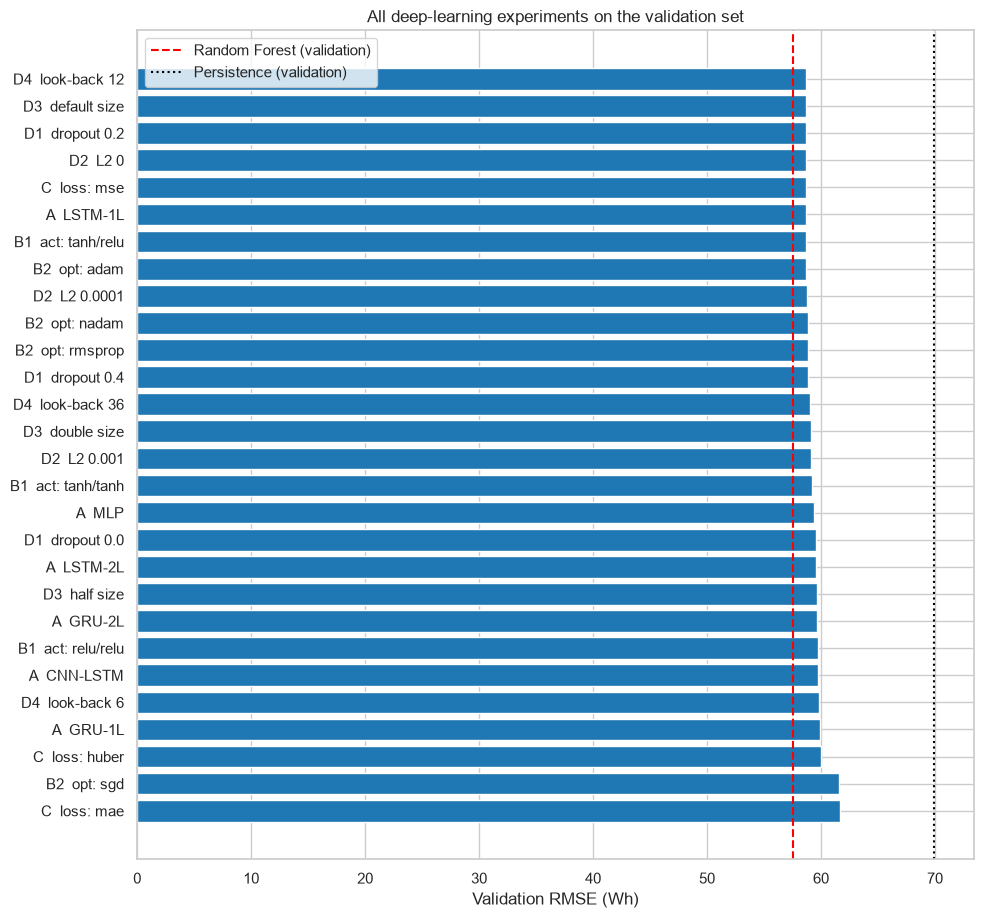

In [27]:
print("Selected configuration (chosen on validation data only):")
for key, value in best_cfg.items():
    print(f"  {key:10s}: {value}")

log_df = pd.DataFrame(experiment_log)
stage_best = (log_df.sort_values("RMSE (Wh)").groupby("Stage").head(1)
              .sort_values("Stage")[["Stage", "Name", "RMSE (Wh)", "MAE (Wh)", "R²"]])
print("\nBest validation result per stage:")
display(stage_best.round(4).reset_index(drop=True))

# All experiments in one picture
plot_log = log_df.sort_values("RMSE (Wh)", ascending=False)
plt.figure(figsize=(10, 0.28 * len(plot_log) + 1.5))
plt.barh(plot_log["Stage"].str.split(":").str[0] + "  " + plot_log["Name"], plot_log["RMSE (Wh)"],
         color="tab:blue")
plt.axvline(baseline_val_results.set_index("Model").loc["Random Forest", "RMSE (Wh)"], color="red",
            linestyle="--", label="Random Forest (validation)")
plt.axvline(baseline_val_results.set_index("Model").loc["Persistence", "RMSE (Wh)"], color="black",
            linestyle=":", label="Persistence (validation)")
plt.xlabel("Validation RMSE (Wh)")
plt.title("All deep-learning experiments on the validation set")
plt.legend()
plt.tight_layout()
plt.show()

## 4. Model Training and Evaluation
**Objective:** train the selected model and assess its performance on the untouched test set.

### 4.1 Training the selected model and monitoring training / validation loss
The configuration chosen in §3 is trained with **three different random seeds** (deep-learning results vary from run to run, so a single run could be lucky or unlucky). Training uses the training sub-set; the validation loss is monitored every epoch for early stopping (patience 6, best weights restored) and learning-rate reduction.

In [28]:
FINAL_SEEDS = [42, 7, 123]
final_runs = {}
for seed in FINAL_SEEDS:
    name = f"final seed {seed}"
    run_experiment("Final", name, best_cfg, seed=seed, store_test=True)
    final_runs[seed] = trained[name]

main_run = final_runs[FINAL_SEEDS[0]]
print("\nFinal model architecture (seed %d):" % FINAL_SEEDS[0])
main_run["model"].summary()

[Final] final seed 42                          val RMSE  58.701 | MAE  26.273 | R² 0.6310 | epochs 27 |  20.0s


[Final] final seed 7                           val RMSE  58.395 | MAE  25.799 | R² 0.6348 | epochs 40 |  28.2s


[Final] final seed 123                         val RMSE  59.598 | MAE  26.868 | R² 0.6196 | epochs 29 |  20.6s

Final model architecture (seed 42):


Model: "sequential_26"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm_24 (LSTM)                  │ (None, 64)             │        20,224 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_29 (Dropout)            │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_54 (Dense)                │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_55 (Dense)                │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 67,013 (261.77 KB)

 Trainable params: 22,337 (87.25 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 44,676 (174.52 KB)

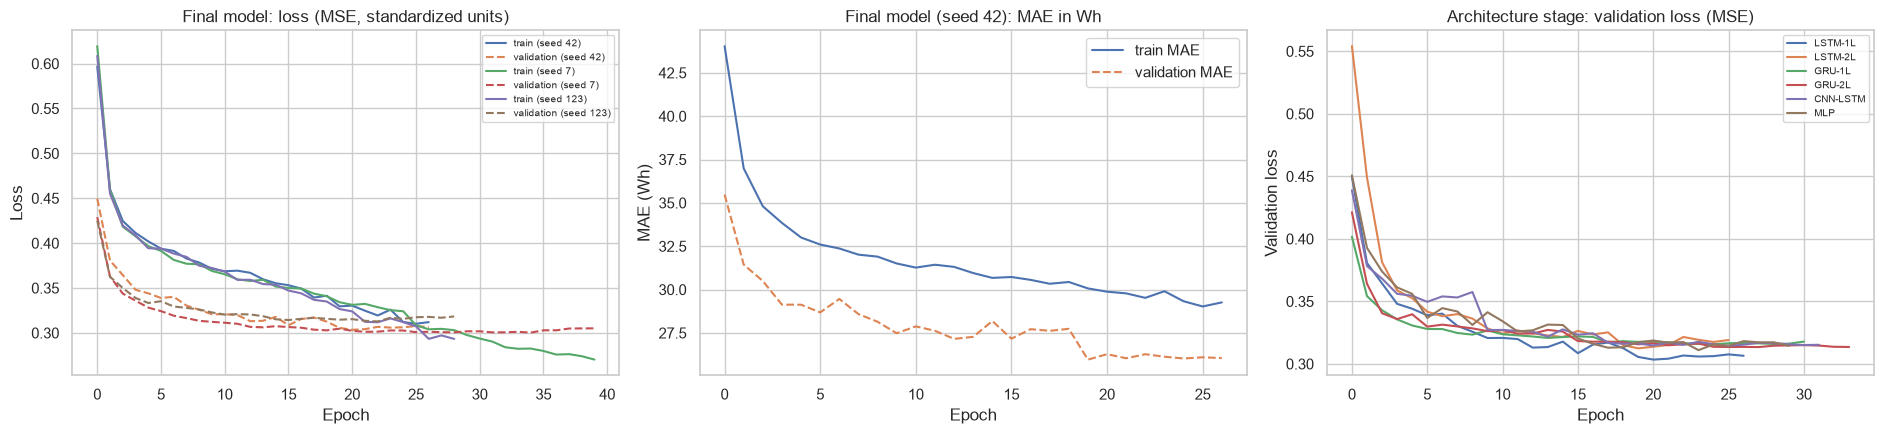

Epochs trained / best epoch per seed: [(27, 21), (40, 35), (29, 23)]


In [29]:
# Training vs validation loss of the final model (all seeds) and of the architecture-stage models
fig, axes = plt.subplots(1, 3, figsize=(19, 4.5))
for seed, run in final_runs.items():
    h = run["history"]
    axes[0].plot(h["loss"], label=f"train (seed {seed})")
    axes[0].plot(h["val_loss"], linestyle="--", label=f"validation (seed {seed})")
axes[0].set(title=f"Final model: loss ({best_cfg['loss'].upper()}, standardized units)", xlabel="Epoch", ylabel="Loss")
axes[0].legend(fontsize=7)

h = main_run["history"]
axes[1].plot(np.array(h["mae"]) * y_scaler.scale_[0], label="train MAE")
axes[1].plot(np.array(h["val_mae"]) * y_scaler.scale_[0], linestyle="--", label="validation MAE")
axes[1].set(title="Final model (seed 42): MAE in Wh", xlabel="Epoch", ylabel="MAE (Wh)")
axes[1].legend()

for name in ARCHITECTURES:
    axes[2].plot(trained[name]["history"]["val_loss"], label=name)
axes[2].set(title="Architecture stage: validation loss (MSE)", xlabel="Epoch", ylabel="Validation loss")
axes[2].legend(fontsize=7)
plt.tight_layout()
plt.show()

best_epochs = [int(np.argmin(r["history"]["val_loss"]) + 1) for r in final_runs.values()]
print("Epochs trained / best epoch per seed:",
      [(len(r["history"]["loss"]), b) for r, b in zip(final_runs.values(), best_epochs)])

### 4.2 Evaluation metrics
* **MAE** — average absolute error in Wh (easy to interpret).
* **RMSE** — square root of the mean squared error in Wh; penalizes large misses (peaks) more.
* **MAPE** — mean absolute percentage error (target is never 0 in this data set; rows with a zero target would be excluded).
* **R²** — share of the variance explained (1 = perfect, 0 = as good as predicting the mean).

### 4.3 Performance assessment on the test set
This is the first and only time the test set is used for evaluation. The test set was **not** used for any decision in section 2 or 3. Every row below is computed on the same 3,947 test targets, in Wh.

In [30]:
test_predictions = dict(baseline_test_pred)

for name in ARCHITECTURES:                                   # architecture-stage models (default hyper-parameters)
    test_predictions[f"DL: {name} (initial)"] = trained[name]["test_pred"]
test_predictions[f"DL: tuned {best_cfg['arch']} (seed {FINAL_SEEDS[0]})"] = main_run["test_pred"]
tuned_name = f"DL: tuned {best_cfg['arch']} (seed {FINAL_SEEDS[0]})"

for name, pred in test_predictions.items():
    assert len(pred) == len(y_test_wh) and np.isfinite(pred).all(), name

test_results = pd.DataFrame(
    [{"Model": n, **regression_metrics(y_test_wh, p)} for n, p in test_predictions.items()]
).sort_values("RMSE (Wh)").reset_index(drop=True)
print("=== TEST-SET RESULTS (all models, original Wh scale) ===")
display(test_results.round(4))

# Seed-to-seed variation of the tuned model
seed_rows = [{"Seed": s, **regression_metrics(y_test_wh, final_runs[s]["test_pred"])} for s in FINAL_SEEDS]
seed_df = pd.DataFrame(seed_rows)
summary = seed_df.drop(columns="Seed").agg(["mean", "std"]).T
print("\nTuned model across seeds (test set):")
display(seed_df.round(4))
display(summary.round(4))

=== TEST-SET RESULTS (all models, original Wh scale) ===


,Model,MAE (Wh),RMSE (Wh),MAPE (%),R²
0,DL: CNN-LSTM (initial),26.4696,57.3111,23.8635,0.6037
1,DL: LSTM-1L (initial),25.8428,57.3860,23.0339,0.6027
2,DL: tuned LSTM (seed 42),25.8428,57.3860,23.0339,0.6027
3,DL: GRU-1L (initial),26.0001,57.4110,22.9971,0.6023
4,DL: LSTM-2L (initial),25.8374,57.9319,22.8946,0.5951
5,DL: GRU-2L (initial),25.5400,58.0318,22.6702,0.5937
6,Random Forest,26.3300,58.4030,23.9055,0.5885
7,DL: MLP (initial),27.1311,59.3263,25.9286,0.5753
8,Linear Regression,27.1273,59.8152,25.0889,0.5683
9,Ridge Regression,27.1272,59.8152,25.0888,0.5683



Tuned model across seeds (test set):


,Seed,MAE (Wh),RMSE (Wh),MAPE (%),R²
0,42,25.8428,57.3860,23.0339,0.6027
1,7,26.6214,59.2983,23.4331,0.5757
2,123,26.2522,57.9214,23.8065,0.5952


,mean,std
MAE (Wh),26.2388,0.3895
RMSE (Wh),58.2019,0.9865
MAPE (%),23.4245,0.3864
R²,0.5912,0.0139


### 4.4 Comparison against the baselines

In [31]:
def pct_better(new, ref):            # positive = new model is better (lower error)
    return (ref - new) / ref * 100

tuned = test_results.set_index("Model")
rows = []
for ref in ["Persistence", "Linear Regression", "Random Forest"]:
    rows.append({
        "Reference": ref,
        "MAE improvement (%)": pct_better(tuned.loc[tuned_name, "MAE (Wh)"], tuned.loc[ref, "MAE (Wh)"]),
        "RMSE improvement (%)": pct_better(tuned.loc[tuned_name, "RMSE (Wh)"], tuned.loc[ref, "RMSE (Wh)"]),
        "R² difference": tuned.loc[tuned_name, "R²"] - tuned.loc[ref, "R²"],
    })
print(f"Tuned deep-learning model vs. baselines (positive % = deep learning is better):")
display(pd.DataFrame(rows).round(3))

best_baseline = test_results[~test_results["Model"].str.startswith("DL:")].iloc[0]["Model"]
best_dl_initial = test_results[test_results["Model"].str.contains("initial")].iloc[0]["Model"]
print("Best baseline on the test set:            ", best_baseline)
print("Best initial (untuned) DL architecture:   ", best_dl_initial)
print("Overall best model (lowest test RMSE):    ", test_results.iloc[0]["Model"])

Tuned deep-learning model vs. baselines (positive % = deep learning is better):


,Reference,MAE improvement (%),RMSE improvement (%),R² difference
0,Persistence,3.031,13.624,0.135
1,Linear Regression,4.735,4.061,0.034
2,Random Forest,1.851,1.741,0.014


Best baseline on the test set:             Random Forest
Best initial (untuned) DL architecture:    DL: CNN-LSTM (initial)
Overall best model (lowest test RMSE):     DL: CNN-LSTM (initial)


### 4.5 Visualizations

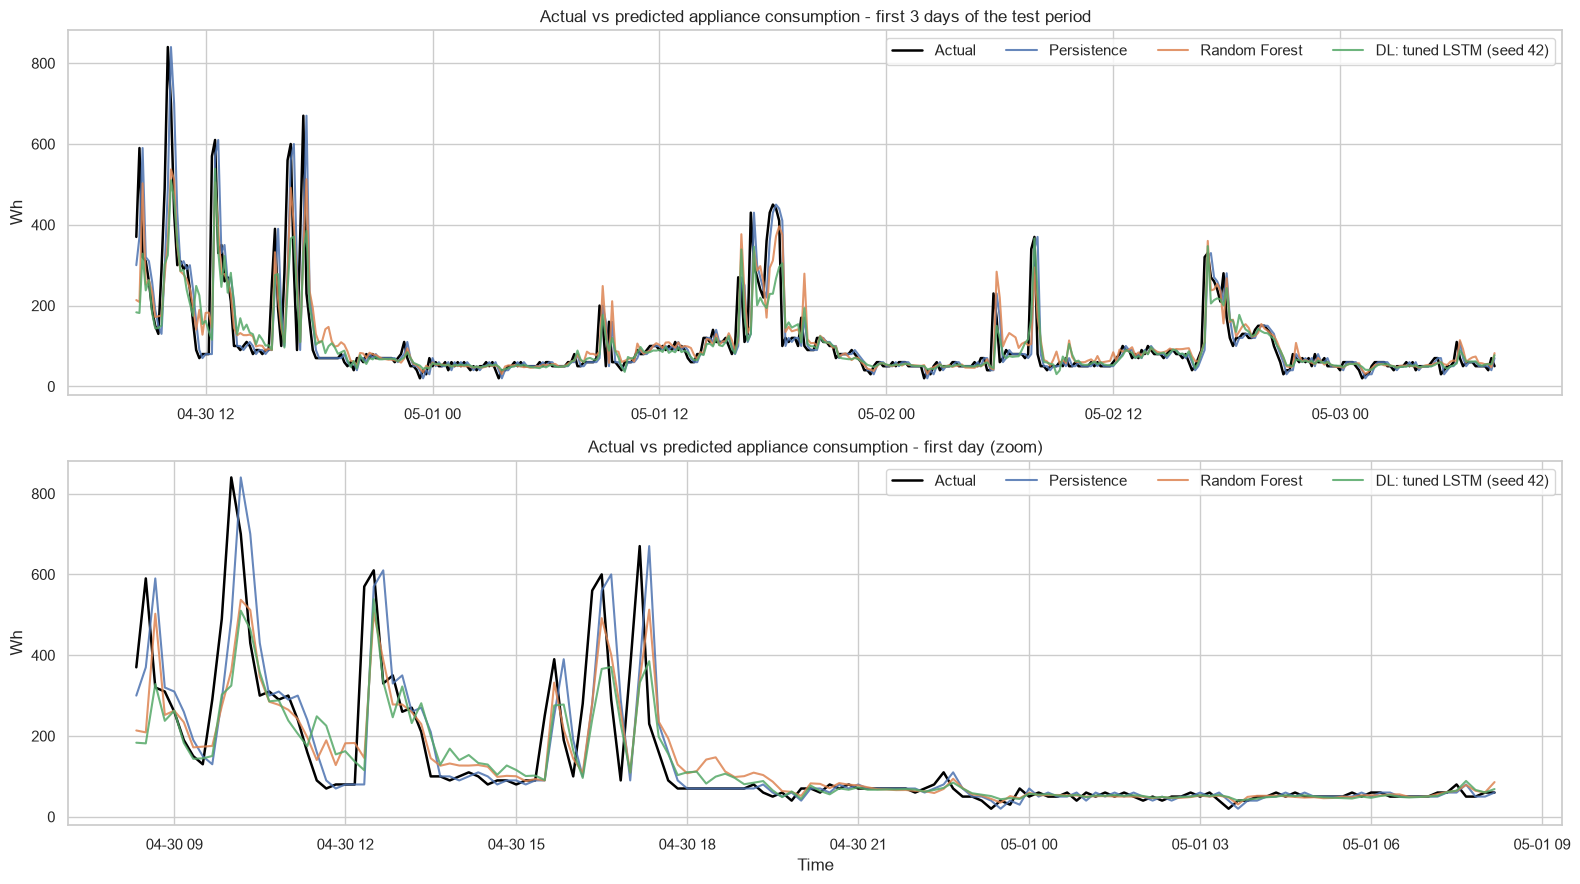

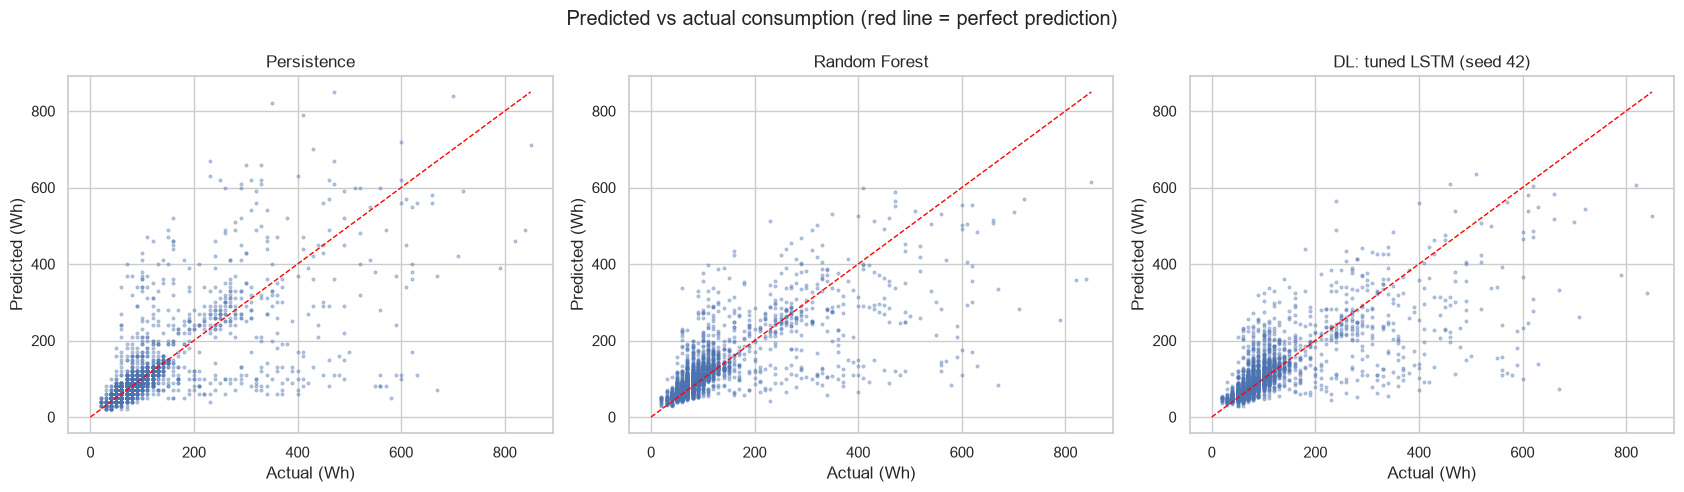

In [32]:
# Predicted vs actual (time series)
selected_models = ["Persistence", "Random Forest", tuned_name]
dates_test = full.loc[idx_test, "date"].to_numpy()

fig, axes = plt.subplots(2, 1, figsize=(16, 9))
for ax, (lo, hi, title) in zip(axes, [(0, 432, "first 3 days of the test period"),
                                      (0, 144, "first day (zoom)")]):
    ax.plot(dates_test[lo:hi], y_test_wh[lo:hi], color="black", linewidth=1.8, label="Actual")
    for name in selected_models:
        ax.plot(dates_test[lo:hi], test_predictions[name][lo:hi], alpha=0.85, label=name)
    ax.set(title=f"Actual vs predicted appliance consumption - {title}", ylabel="Wh")
    ax.legend(ncol=4)
axes[-1].set_xlabel("Time")
plt.tight_layout()
plt.show()

# Predicted vs actual (scatter)
fig, axes = plt.subplots(1, 3, figsize=(17, 5))
for ax, name in zip(axes, selected_models):
    ax.scatter(y_test_wh, test_predictions[name], s=4, alpha=0.35)
    lim = [0, max(y_test_wh.max(), test_predictions[name].max())]
    ax.plot(lim, lim, color="red", linestyle="--", linewidth=1)
    ax.set(title=name, xlabel="Actual (Wh)", ylabel="Predicted (Wh)")
plt.suptitle("Predicted vs actual consumption (red line = perfect prediction)")
plt.tight_layout()
plt.show()

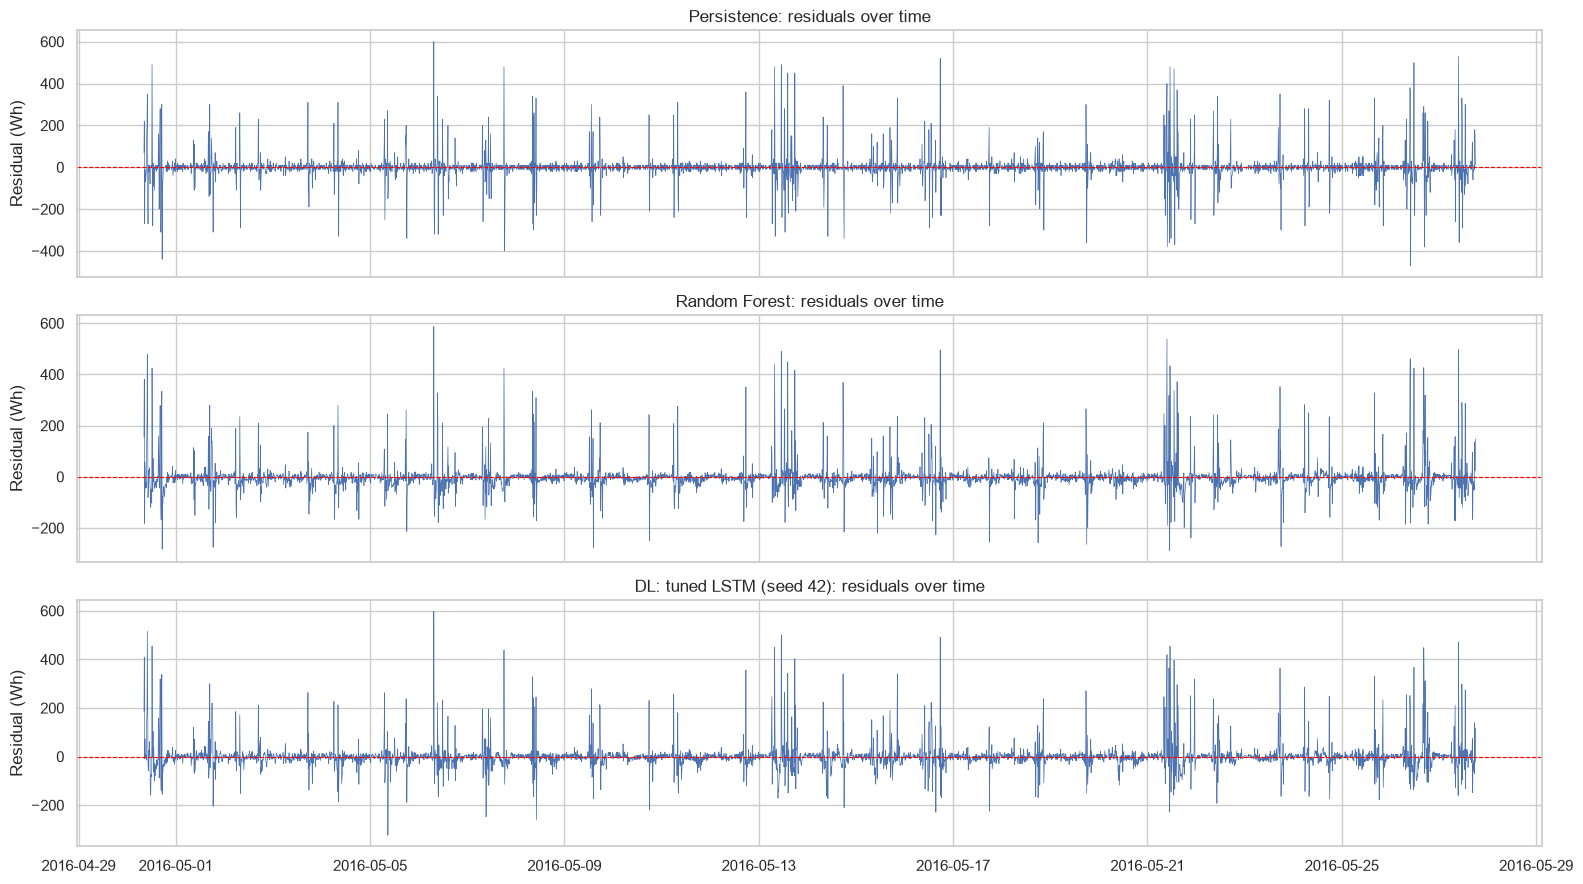

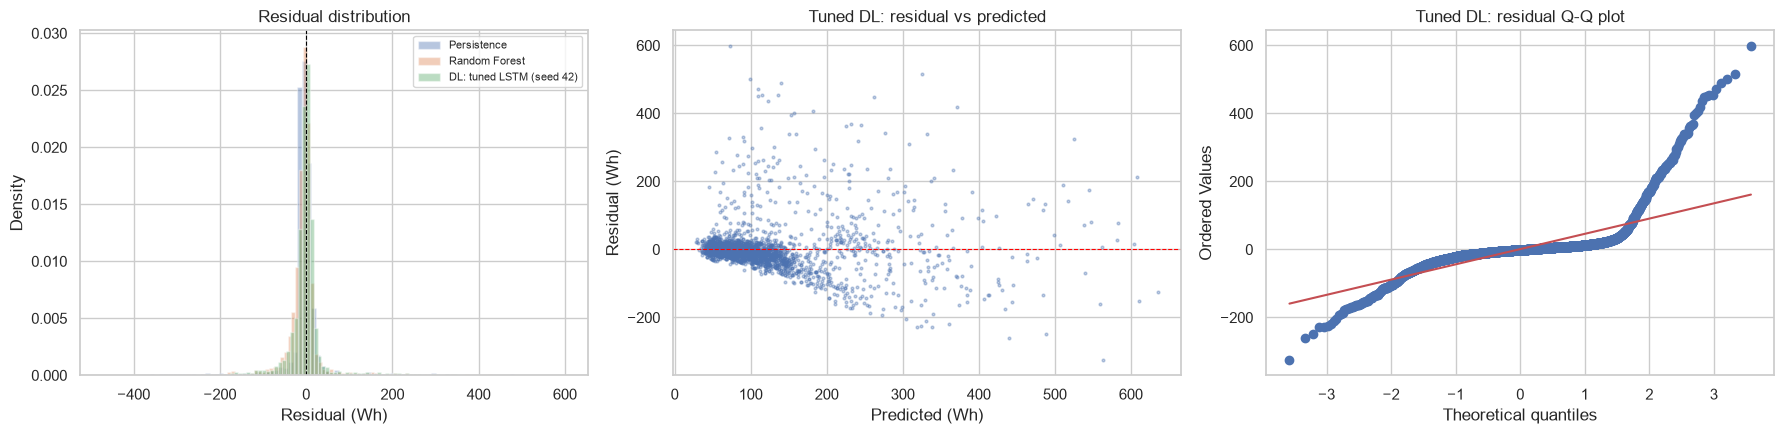

,Mean residual (Wh),Residual std (Wh),Max |residual| (Wh),Share of |residual| > 50 Wh (%)
Persistence,0.033,66.438,600.000,9.830
Random Forest,-2.371,58.355,587.324,11.502
DL: tuned LSTM (seed 42),1.001,57.377,597.841,11.756


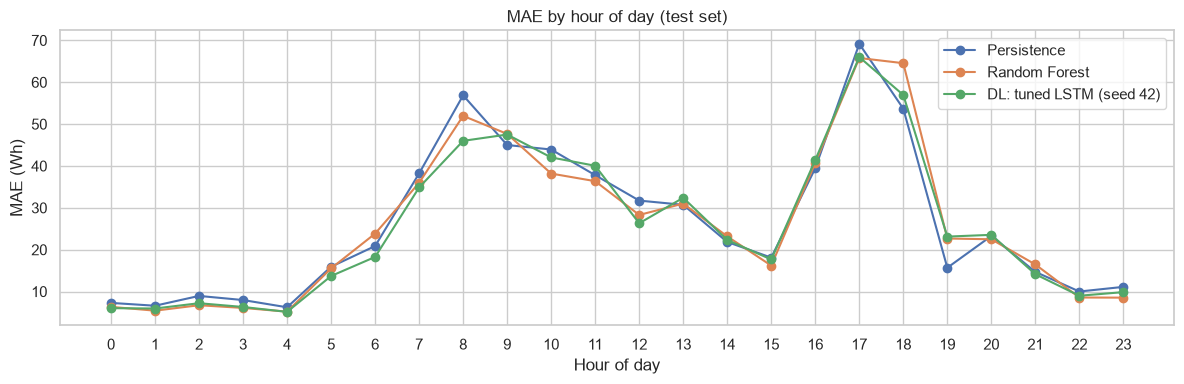

In [33]:
# Residual analysis: residual = actual - predicted
residuals = {n: y_test_wh - test_predictions[n] for n in selected_models}

fig, axes = plt.subplots(len(selected_models), 1, figsize=(16, 9), sharex=True)
for ax, (name, res) in zip(axes, residuals.items()):
    ax.plot(dates_test, res, linewidth=0.5)
    ax.axhline(0, color="red", linestyle="--", linewidth=0.8)
    ax.set(title=f"{name}: residuals over time", ylabel="Residual (Wh)")
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
for name, res in residuals.items():
    axes[0].hist(res, bins=100, alpha=0.4, density=True, label=name)
axes[0].axvline(0, color="black", linestyle="--", linewidth=0.8)
axes[0].set(title="Residual distribution", xlabel="Residual (Wh)", ylabel="Density")
axes[0].legend(fontsize=8)

res = residuals[tuned_name]
axes[1].scatter(test_predictions[tuned_name], res, s=4, alpha=0.35)
axes[1].axhline(0, color="red", linestyle="--", linewidth=0.8)
axes[1].set(title="Tuned DL: residual vs predicted", xlabel="Predicted (Wh)", ylabel="Residual (Wh)")

import scipy.stats as st
st.probplot(res, dist="norm", plot=axes[2])
axes[2].set_title("Tuned DL: residual Q-Q plot")
plt.tight_layout()
plt.show()

residual_summary = pd.DataFrame({
    n: {"Mean residual (Wh)": r.mean(), "Residual std (Wh)": r.std(),
        "Max |residual| (Wh)": np.abs(r).max(),
        "Share of |residual| > 50 Wh (%)": (np.abs(r) > 50).mean() * 100}
    for n, r in residuals.items()}).T
display(residual_summary.round(3))

# Error by hour of day
hourly_mae = pd.DataFrame({n: pd.Series(np.abs(r)).groupby(full.loc[idx_test, "hour"].to_numpy()).mean()
                           for n, r in residuals.items()})
hourly_mae.plot(figsize=(12, 4), marker="o")
plt.title("MAE by hour of day (test set)")
plt.xlabel("Hour of day")
plt.ylabel("MAE (Wh)")
plt.xticks(range(0, 24))
plt.tight_layout()
plt.show()

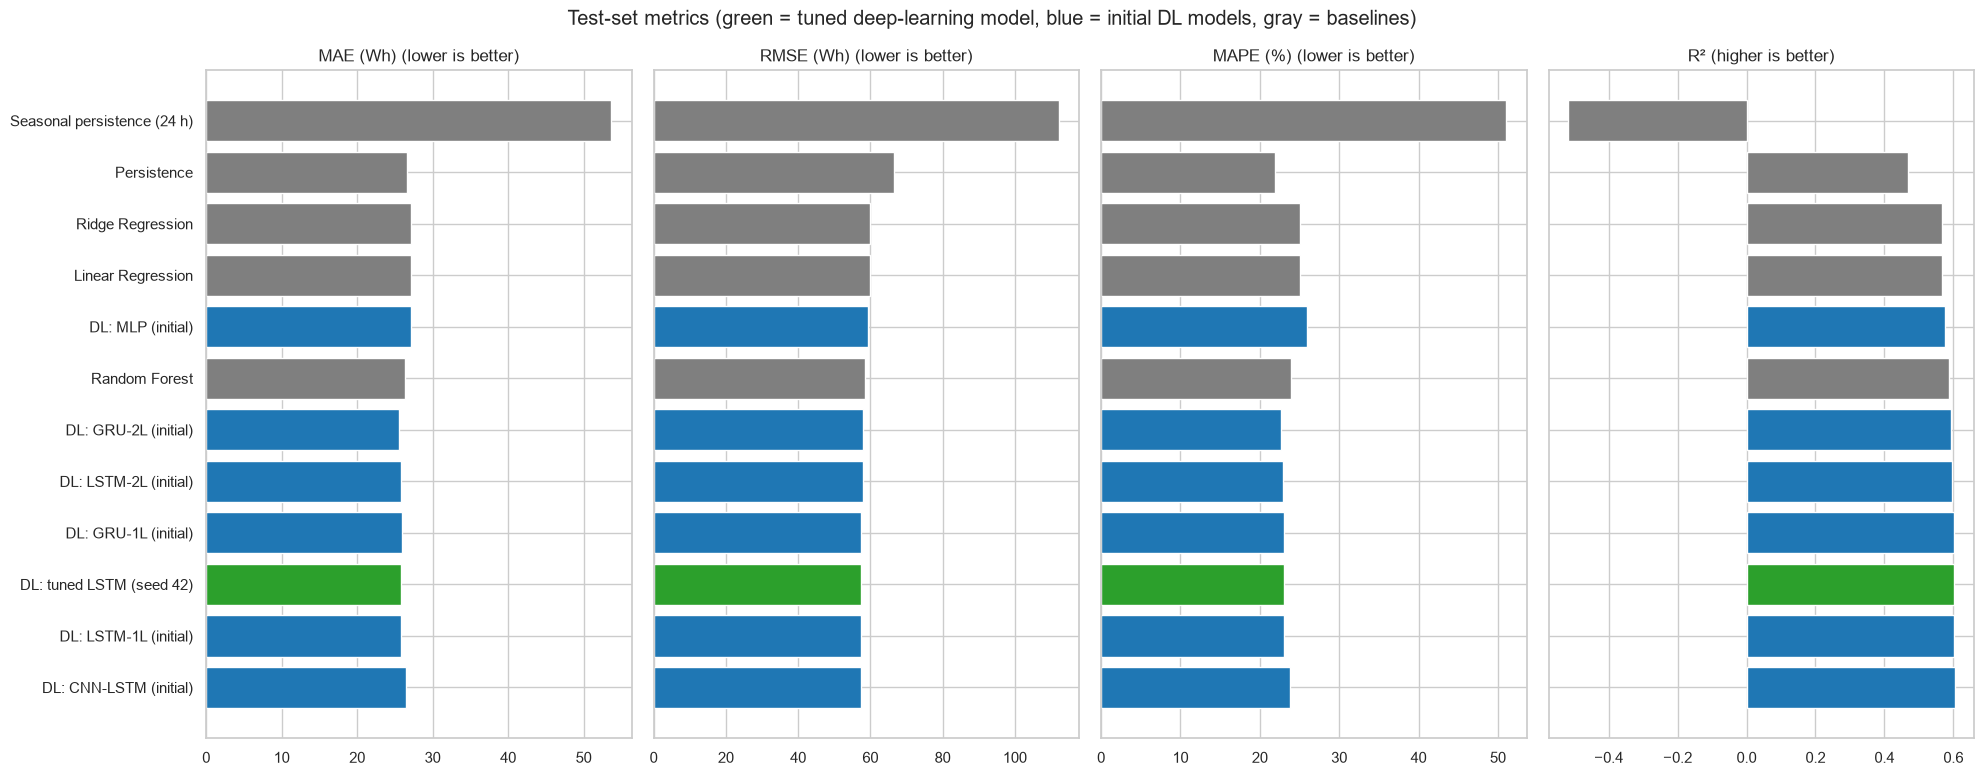

Saved: results/test_results.csv, results/validation_experiments.csv, results/best_dl_model.keras


In [34]:
# Evaluation metrics plot
plot_df = test_results.set_index("Model")
order = plot_df.sort_values("RMSE (Wh)").index
fig, axes = plt.subplots(1, 4, figsize=(20, 0.45 * len(order) + 2.5), sharey=True)
for ax, metric, better in zip(axes, ["MAE (Wh)", "RMSE (Wh)", "MAPE (%)", "R²"],
                              ["lower", "lower", "lower", "higher"]):
    colors = ["tab:green" if str(n).startswith("DL: tuned") else
              "tab:blue" if str(n).startswith("DL:") else "tab:gray" for n in order]
    ax.barh(order, plot_df.loc[order, metric], color=colors)
    ax.set(title=f"{metric} ({better} is better)")
    ax.invert_yaxis()
plt.suptitle("Test-set metrics (green = tuned deep-learning model, blue = initial DL models, gray = baselines)")
plt.tight_layout()
plt.show()

# Save the tables and the final model
os.makedirs("results", exist_ok=True)
test_results.to_csv("results/test_results.csv", index=False)
log_df.to_csv("results/validation_experiments.csv", index=False)
main_run["model"].save("results/best_dl_model.keras")
print("Saved: results/test_results.csv, results/validation_experiments.csv, results/best_dl_model.keras")

### 4.6 Conclusions
**Selected model:** a single-layer LSTM (64 units, dense head of 32 ReLU units, dropout 0.2) with tanh recurrent activation, Adam (learning rate 0.001, reduced on plateau), MSE loss, 12-step look-back and early stopping, trained on 14 past-consumption and time features. None of the later tuning stages found an improvement of at least 0.5 % over the first-stage default, so the tuned model is identical to LSTM-1L from §3.3.

**Test-set results** (3,947 intervals, Wh; mean ± standard deviation over three seeds for the deep-learning model):

| Model | MAE | RMSE | R² |
|---|---|---|---|
| Persistence (previous interval) | 26.65 | 66.44 | 0.467 |
| Linear Regression | 27.13 | 59.82 | 0.568 |
| Random Forest | 26.33 | 58.40 | 0.589 |
| **Tuned LSTM (3 seeds)** | **26.24 ± 0.39** | **58.20 ± 0.99** | **0.591 ± 0.014** |

**What the evidence supports**
1. The deep-learning model is clearly better than persistence in RMSE (about 12 % lower) and about 3 % better than Linear Regression, but its advantage over the **Random Forest is only 0.3 %** in RMSE, far inside the seed-to-seed variation (± 1 Wh). On the validation weeks the Random Forest was even better than every deep-learning model (57.6 vs 58.7 Wh). The honest conclusion is that on this data set **deep learning does not give a meaningful gain over a good tree-based model**; the three models are practically tied.
2. Persistence is a very strong baseline for MAE and MAPE (consumption in the next 10 minutes is similar to the last interval; lag-1 autocorrelation 0.76). The models' gains come from reducing the large misses (RMSE), not from the typical error.
3. The ranking of the initial architectures on the test set (CNN-LSTM 57.3 … MLP 59.3) differs from their validation ranking, and the differences are inside the seed noise. The deep-learning model was therefore **not** re-selected on the test set: the validation-selected configuration is reported.
4. The remaining error is dominated by unpredictable short consumption spikes (the largest residuals are about 600 Wh for every model; see the residual plots). With R² ≈ 0.6, the available features (past consumption, time of day, household sensors) explain only part of the behaviour; a gain would need information about *what the occupants are doing*.
5. The corrections made to the earlier version (§ top of the notebook) mattered more than model choice: the window now contains the latest consumption, all models use identical information, features were selected and tested for stability over seasons, and decisions were made on a validation set.

**Limitations and next steps**
* The data covers only about four and a half months in one house; the 80 % / 20 % split puts mostly January–April in training and May in testing, so seasonal generalization cannot be fully judged. More data across seasons, or walk-forward evaluation over several test blocks, would give a more reliable ranking.
* Hyper-parameter differences below about 1–2 % cannot be resolved with three seeds; repeated runs or an ensemble of seeds would reduce the variance.
* For an edge device the single-layer LSTM (22 k parameters) or even the MLP (32 k parameters, 8 s training) is the more sensible choice than a larger network, since all models reach about the same accuracy.

## 5. Model Optimization
**Objective:** enhance the model's performance through optimization techniques.

### Starting point and scope
* §3–§4 left two sensible, light-weight candidates: a **single-layer LSTM** and a **single-hidden-layer MLP** (the other architectures were not better and are heavier). Both are optimized here; the number of layers is therefore fixed at **one** (two-layer variants were not better in §3.3, and a small network suits an edge device).
* The 14 selected features, the **80 % / 20 % chronological split** and the rule "the test set is used only once, at the end" are **unchanged**.

### Data coverage and a reliable ranking (no new data, same split)
There is no more data than the 4.5 months we have, and the 80 % / 20 % split must stay as it is. §4 showed that the differences between models are of the same size as the random-seed noise, so a single validation run is not enough to rank configurations. Without adding data or changing the split, reliability is increased with four techniques, all of which use **only the 80 % training part**:

| Technique | What it adds |
|---|---|
| **Walk-forward cross-validation inside the training part** | each candidate is trained and scored on four consecutive time blocks (expanding window, scalers re-fitted per fold, early-stopping validation taken from the fold's own training data), so a configuration must work in *different periods*, not only in the last validation weeks |
| **Several random seeds** | averages out the run-to-run variation of neural-network training |
| **Two-stage search (screening → re-ranking)** | cheap single-split screening of many configurations, then the expensive walk-forward test only for the shortlist |
| **Paired block bootstrap on the final test comparison** | the test set is not enlarged, but resampling whole days of test errors gives a confidence interval for each difference between models, so we can say whether a gain is real |

### Plan
| Subtask | Where |
|---|---|
| 1. Hyper-parameter tuning (learning rate, batch size, epochs, layers, neurons) with Random Search, Grid Search | §5.1 |
| 2. Regularization: dropout layers and different dropout rates | §5.2 |
| 3. Early stopping on the validation loss | §5.3 |
| 4. Re-evaluation of the optimized model on the test set and comparison before / after optimization | §5.4 – §5.5 |

### 5.0 Setup: starting configurations, walk-forward evaluation, search budget

In [35]:
import json
from sklearn.model_selection import TimeSeriesSplit

# QUICK_RUN = True shrinks every budget for a fast smoke test of the code; the reported results use False.
QUICK_RUN = bool(int(os.environ.get("NB_QUICK_RUN", "0")))

N_RANDOM = {"LSTM": 16, "MLP": 20}      # random-search budget per model family
CV_SEEDS = (42, 7)                      # seeds for the walk-forward re-ranking
SWEEP_SEEDS = (42, 7)                   # seeds for the dropout and patience sweeps
WF_SPLITS = 4                           # walk-forward folds inside the training part
if QUICK_RUN:
    N_RANDOM, CV_SEEDS, SWEEP_SEEDS, WF_SPLITS, MAX_EPOCHS = {"LSTM": 2, "MLP": 2}, (42,), (42,), 2, 3

# Starting ("before optimization") configurations = the settings used in sections 3-4
FAMILIES = {
    "LSTM": {**BASE_CFG, **ARCHITECTURES["LSTM-1L"]},                       # 1 LSTM layer (64) + dense 32
    "MLP":  {**BASE_CFG, "arch": "MLP", "units": (128,), "dense": 0},       # 1 hidden layer (128), no extra head
}
for fam, cfg in FAMILIES.items():
    print(f"{fam:5s} before-optimization config: units {cfg['units']}, dense {cfg['dense']}, dropout {cfg['dropout']}, lr {cfg['lr']:g}, "
          f"look-back {cfg['lookback']} | batch {cfg.get('batch', BATCH_SIZE)}, patience {cfg.get('patience', PATIENCE)}, max epochs {cfg.get('max_epochs', MAX_EPOCHS)}")

# ---- walk-forward cross-validation INSIDE the 80 % training part (the test part is never used) ----
n_period = n_train                                    # rows of the training part (sub-set + validation)
wf_folds = list(TimeSeriesSplit(n_splits=WF_SPLITS).split(np.arange(n_period)))
X_raw = full[FEATURES].to_numpy(dtype=np.float32)
print("\nWalk-forward folds (rows):", [(len(tr), len(te)) for tr, te in wf_folds],
      "| dates of fold-1 test block:", full.loc[wf_folds[0][1][0], "date"].date(), "->", full.loc[wf_folds[0][1][-1], "date"].date())
assert max(te.max() for _, te in wf_folds) < n_train, "walk-forward must never touch the test period"

_wf_cache = {}
def walk_forward_dl(cfg, seeds=CV_SEEDS):
    """Mean validation RMSE/MAE (Wh) of a configuration over the walk-forward folds and seeds.
    Per fold: scalers fitted on the fold's training rows only; the last 15 % of those rows are used for
    early stopping; the following block (never seen in training) is predicted and scored in Wh."""
    key = json.dumps(cfg, sort_keys=True, default=str) + str(tuple(seeds))
    if key in _wf_cache:
        return _wf_cache[key]
    L = cfg["lookback"]
    fold_rmse, fold_mae = [], []
    for tr, te in wf_folds:
        n_v = int(len(tr) * VAL_FRACTION)
        fit_idx, val_idx = tr[:-n_v], tr[-n_v:]
        xs = StandardScaler().fit(X_raw[fit_idx])
        ys = StandardScaler().fit(y_full[fit_idx].reshape(-1, 1))
        Xs = xs.transform(X_raw).astype(np.float32)
        Ys = ys.transform(y_full.reshape(-1, 1)).astype(np.float32).ravel()

        def windows(idx):
            idx = idx[idx >= L - 1]
            return np.stack([Xs[i - L + 1: i + 1] for i in idx]).astype(np.float32), Ys[idx], idx
        Xf, yf, _ = windows(fit_idx); Xv, yv, _ = windows(val_idx); Xt, _, it = windows(te)
        for seed in seeds:
            model, _ = fit_dl(cfg, Xf, yf, Xv, yv, seed)
            pred = ys.inverse_transform(model.predict(Xt, batch_size=1024, verbose=0).reshape(-1, 1)).ravel()
            m = regression_metrics(y_full[it], pred)
            fold_rmse.append(m["RMSE (Wh)"]); fold_mae.append(m["MAE (Wh)"])
            tf.keras.backend.clear_session()
    per_fold = np.array(fold_rmse).reshape(len(wf_folds), len(seeds)).mean(axis=1)
    out = {"WF RMSE (Wh)": float(np.mean(fold_rmse)), "WF MAE (Wh)": float(np.mean(fold_mae)),
           "WF RMSE std over fits": float(np.std(fold_rmse)), "Worst fold (Wh)": float(per_fold.max()),
           **{f"fold {k + 1}": float(v) for k, v in enumerate(per_fold)}}
    _wf_cache[key] = out
    return out

def count_params(cfg):
    m = build_model(cfg, len(FEATURES)); n = m.count_params(); tf.keras.backend.clear_session(); return n

def neighbours(values, current):
    """The current value and its direct neighbours in an ordered list (local grid around a good value)."""
    i = values.index(current)
    return values[max(0, i - 1): i + 2]

LSTM  before-optimization config: units (64,), dense 32, dropout 0.2, lr 0.001, look-back 12 | batch 128, patience 6, max epochs 40
MLP   before-optimization config: units (128,), dense 0, dropout 0.2, lr 0.001, look-back 12 | batch 128, patience 6, max epochs 40

Walk-forward folds (rows): [(3132, 3128), (6260, 3128), (9388, 3128), (12516, 3128)] | dates of fold-1 test block: 2016-02-03 -> 2016-02-25


### 5.1 Hyper-parameter tuning
**Hyper-parameters tuned:** learning rate, batch size, number of neurons per layer, size of the optional dense head (0 = none), dropout rate and look-back window. The **number of layers is fixed at one** (see above). The **number of epochs** is not a free parameter: with early stopping (§5.3) the network trains until the validation loss stops improving, so the maximum is set high (100) and the number of epochs actually used is *measured* and reported.

**Search strategy (three steps)**
1. **Random Search** over a broad space: with six hyper-parameters, random sampling covers each parameter's range far better than a grid of the same cost. Each sampled configuration is screened on the validation set (single run).
2. **Grid Search** around the best random configuration: a full grid over its two most sensitive parameters, **learning rate × batch size**, using the neighbouring values of the best configuration.
3. **Reliable re-ranking:** the shortlist (the starting configuration, the best random and the best grid configuration) is compared with the **walk-forward cross-validation** from §5.0, and the winner is chosen on that mean error. A tuned configuration is only accepted if it is at least 0.5 % better than the starting configuration; otherwise the starting configuration is kept (screening results on one split can be lucky).

Bayesian optimization (e.g. Optuna / KerasTuner) would be the next step if a larger budget were available; with the small search space and the noisy single-split scores, random + local grid search is enough here.

In [36]:
SPACE = {
    "LSTM": dict(units=[16, 32, 64, 96, 128], dense=[0, 16, 32, 64], dropout=[0.1, 0.2, 0.3, 0.4, 0.5],
                 lr=[3e-4, 5e-4, 1e-3, 2e-3, 3e-3], batch=[32, 64, 128, 256], lookback=[6, 12, 24]),
    "MLP":  dict(units=[32, 64, 128, 256, 512], dense=[0], dropout=[0.1, 0.2, 0.3, 0.4, 0.5],
                 lr=[3e-4, 5e-4, 1e-3, 2e-3, 3e-3], batch=[32, 64, 128, 256], lookback=[3, 6, 12, 24]),
}
EPOCH_CAP = 3 if QUICK_RUN else 100          # generous cap: early stopping decides the real number of epochs

def cfg_key(cfg):
    return json.dumps(cfg, sort_keys=True, default=str)

def sample_configs(family, n, rng):
    """Draw n distinct random configurations from the family's search space."""
    base, space, out, seen = FAMILIES[family], SPACE[family], [], set()
    while len(out) < n:
        draw = {k: v[rng.integers(len(v))] for k, v in space.items()}
        cfg = {**base, "units": (int(draw["units"]),), "dense": int(draw["dense"]), "dropout": float(draw["dropout"]),
               "lr": float(draw["lr"]), "batch": int(draw["batch"]), "lookback": int(draw["lookback"]),
               "max_epochs": EPOCH_CAP}
        if cfg_key(cfg) not in seen:
            seen.add(cfg_key(cfg)); out.append(cfg)
    return out

def short(cfg):
    return f"u{cfg['units'][0]} d{cfg['dense']} p{cfg['dropout']} lr{cfg['lr']:g} b{cfg.get('batch', BATCH_SIZE)} L{cfg['lookback']}"

# ---- Step 1: Random Search (screening on the validation set, one run per configuration) ----
rng = np.random.default_rng(SEED)
random_results = {}
for family in FAMILIES:
    run_experiment(f"E1: random search {family}", f"{family} start", FAMILIES[family])
    for k, cfg in enumerate(sample_configs(family, N_RANDOM[family], rng), start=1):
        run_experiment(f"E1: random search {family}", f"{family} rs{k:02d} {short(cfg)}", cfg)
    rows = stage_table(f"E1: random search {family}")
    random_results[family] = rows
    print(f"\n{family}: random-search results (validation, sorted by RMSE)")
    display(rows[["Name", "MAE (Wh)", "RMSE (Wh)", "R²", "Overfit gap (Wh)", "Epochs", "Params", "Time (s)"]].head(8).round(3))

[E1: random search LSTM] LSTM start                             val RMSE  58.701 | MAE  26.273 | R² 0.6310 | epochs 27 |  19.7s


[E1: random search LSTM] LSTM rs01 u16 d64 p0.4 lr0.001 b64 L24 val RMSE  61.234 | MAE  26.066 | R² 0.5985 | epochs 25 |  26.6s


[E1: random search LSTM] LSTM rs02 u16 d32 p0.2 lr0.0003 b128 L24 val RMSE  59.840 | MAE  26.184 | R² 0.6165 | epochs 64 |  41.9s


[E1: random search LSTM] LSTM rs03 u96 d64 p0.4 lr0.002 b128 L6 val RMSE  59.095 | MAE  26.001 | R² 0.6260 | epochs 23 |  14.8s


[E1: random search LSTM] LSTM rs04 u128 d16 p0.3 lr0.0005 b32 L24 val RMSE  58.784 | MAE  25.501 | R² 0.6299 | epochs 19 |  68.7s


...

[E1: random search MLP] MLP rs17 u256 d0 p0.1 lr0.003 b128 L24 val RMSE  61.937 | MAE  30.882 | R² 0.5892 | epochs 41 |  11.5s


[E1: random search MLP] MLP rs18 u32 d0 p0.3 lr0.002 b64 L6    val RMSE  60.859 | MAE  27.986 | R² 0.6034 | epochs 33 |   9.7s


[E1: random search MLP] MLP rs19 u32 d0 p0.2 lr0.0005 b64 L12  val RMSE  60.724 | MAE  27.776 | R² 0.6051 | epochs 63 |  18.1s


[E1: random search MLP] MLP rs20 u256 d0 p0.4 lr0.0005 b256 L3 val RMSE  61.007 | MAE  27.966 | R² 0.6014 | epochs 59 |   9.0s

MLP: random-search results (validation, sorted by RMSE)


,Name,MAE (Wh),RMSE (Wh),R²,Overfit gap (Wh),Epochs,Params,Time (s)
0,MLP rs08 u128 d0 p0.1 lr0.001 b256 L6,28.143,60.340,0.610,0.689,53,11009,8.1
1,MLP rs03 u256 d0 p0.4 lr0.001 b128 L6,28.108,60.349,0.610,0.784,61,22017,13.1
2,MLP rs15 u64 d0 p0.1 lr0.0005 b32 L3,28.001,60.371,0.610,-2.294,36,2817,18.4
3,MLP rs04 u256 d0 p0.3 lr0.001 b128 L12,28.093,60.398,0.609,1.502,61,43521,14.7
4,MLP rs05 u32 d0 p0.1 lr0.0005 b32 L6,27.980,60.407,0.609,-2.341,51,2753,26.0
5,MLP rs06 u256 d0 p0.4 lr0.001 b256 L12,27.940,60.436,0.609,1.391,52,43521,9.4
6,MLP start,27.899,60.505,0.608,0.941,40,21761,8.8
7,MLP rs19 u32 d0 p0.2 lr0.0005 b64 L12,27.776,60.724,0.605,-1.905,63,5441,18.1


In [37]:
# ---- Step 2: Grid Search around the best random configuration (learning rate x batch size) ----
grid_best = {}
for family in FAMILIES:
    rs_only = random_results[family][random_results[family]["Name"].str.contains(" rs")]    # sampled configurations only
    best_name = rs_only.iloc[0]["Name"]                                                    # lowest validation RMSE
    best_cfg_rs = trained[best_name]["cfg"]
    lr_values = neighbours(SPACE[family]["lr"], best_cfg_rs["lr"]) if best_cfg_rs["lr"] in SPACE[family]["lr"] else [best_cfg_rs["lr"]]
    batch_values = neighbours(SPACE[family]["batch"], best_cfg_rs["batch"]) if best_cfg_rs["batch"] in SPACE[family]["batch"] else [best_cfg_rs["batch"]]
    print(f"\n{family}: best random configuration -> {best_name}\n   grid: lr {lr_values} x batch {batch_values}")
    for lr in lr_values:
        for batch in batch_values:
            cfg = {**best_cfg_rs, "lr": lr, "batch": batch}
            if cfg_key(cfg) in {cfg_key(t["cfg"]) for t in trained.values()}:
                continue                                    # already trained during random search
            run_experiment(f"E2: grid search {family}", f"{family} grid lr{lr:g} b{batch}", cfg)
    grid_rows = stage_table(f"E2: grid search {family}")
    print(f"{family}: grid-search results (validation)")
    display(grid_rows[["Name", "MAE (Wh)", "RMSE (Wh)", "R²", "Epochs", "Params", "Time (s)"]].round(3))
    pool_rows = pd.concat([random_results[family], grid_rows]).sort_values("RMSE (Wh)")
    grid_best[family] = dict(random=best_cfg_rs, overall=trained[pool_rows.iloc[0]["Name"]]["cfg"],
                             overall_name=pool_rows.iloc[0]["Name"])


LSTM: best random configuration -> LSTM rs04 u128 d16 p0.3 lr0.0005 b32 L24
   grid: lr [0.0003, 0.0005, 0.001] x batch [32, 64]


[E2: grid search LSTM] LSTM grid lr0.0003 b32                 val RMSE  59.022 | MAE  25.275 | R² 0.6270 | epochs 29 | 104.5s


[E2: grid search LSTM] LSTM grid lr0.0003 b64                 val RMSE  59.694 | MAE  26.787 | R² 0.6184 | epochs 34 |  94.2s


[E2: grid search LSTM] LSTM grid lr0.0005 b64                 val RMSE  59.552 | MAE  26.693 | R² 0.6202 | epochs 24 |  66.4s


[E2: grid search LSTM] LSTM grid lr0.001 b32                  val RMSE  57.682 | MAE  25.420 | R² 0.6437 | epochs 19 |  69.0s


...

[E2: grid search MLP] MLP grid lr0.0005 b256                 val RMSE  60.502 | MAE  28.119 | R² 0.6080 | epochs 57 |   8.5s


[E2: grid search MLP] MLP grid lr0.001 b128                  val RMSE  60.187 | MAE  28.329 | R² 0.6121 | epochs 49 |   9.9s


[E2: grid search MLP] MLP grid lr0.002 b128                  val RMSE  60.113 | MAE  28.676 | R² 0.6130 | epochs 57 |  12.8s


[E2: grid search MLP] MLP grid lr0.002 b256                  val RMSE  60.324 | MAE  28.569 | R² 0.6103 | epochs 51 |   7.8s
MLP: grid-search results (validation)


,Name,MAE (Wh),RMSE (Wh),R²,Epochs,Params,Time (s)
0,MLP grid lr0.002 b128,28.676,60.113,0.613,57,11009,12.8
1,MLP grid lr0.0005 b128,27.972,60.134,0.613,43,11009,8.8
2,MLP grid lr0.001 b128,28.329,60.187,0.612,49,11009,9.9
3,MLP grid lr0.002 b256,28.569,60.324,0.610,51,11009,7.8
4,MLP grid lr0.0005 b256,28.119,60.502,0.608,57,11009,8.5


In [38]:
# ---- Step 3: reliable re-ranking of the shortlist with walk-forward cross-validation (training part only) ----
shortlist = {}
for family in FAMILIES:
    cands = {"start (before optimization)": FAMILIES[family],
             "best random search": grid_best[family]["random"],
             "best random/grid (screening)": grid_best[family]["overall"]}
    unique = {}
    for name, cfg in cands.items():                                    # drop duplicates, keep the first name
        unique.setdefault(cfg_key(cfg), (name, cfg))
    rows = []
    for name, cfg in unique.values():
        wf = walk_forward_dl(cfg)
        rows.append({"Family": family, "Candidate": name, "Config": short(cfg), "Params": count_params(cfg), **wf})
        print(f"[walk-forward] {family:5s} {name:30s} {short(cfg):34s} RMSE {wf['WF RMSE (Wh)']:.3f} Wh (worst fold {wf['Worst fold (Wh)']:.2f})")
    shortlist[family] = (pd.DataFrame(rows), {n: c for n, c in unique.values()})
    display(shortlist[family][0].drop(columns="Family").round(3))

[walk-forward] LSTM  start (before optimization)    u64 d32 p0.2 lr0.001 b128 L12      RMSE 65.765 Wh (worst fold 71.08)


[walk-forward] LSTM  best random search             u128 d16 p0.3 lr0.0005 b32 L24     RMSE 66.060 Wh (worst fold 70.55)


[walk-forward] LSTM  best random/grid (screening)   u128 d16 p0.3 lr0.001 b32 L24      RMSE 65.710 Wh (worst fold 70.87)


,Candidate,Config,Params,WF RMSE (Wh),WF MAE (Wh),WF RMSE std over fits,Worst fold (Wh),fold 1,fold 2,fold 3,fold 4
0,start (before optimization),u64 d32 p0.2 lr0.001 b128 L12,22337,65.765,31.263,4.708,71.085,69.702,71.085,61.502,60.770
1,best random search,u128 d16 p0.3 lr0.0005 b32 L24,75297,66.060,31.338,3.907,70.545,69.226,70.545,62.887,61.580
2,best random/grid (screening),u128 d16 p0.3 lr0.001 b32 L24,75297,65.710,31.162,4.106,70.871,68.429,70.871,62.157,61.383


[walk-forward] MLP   start (before optimization)    u128 d0 p0.2 lr0.001 b128 L12      RMSE 66.656 Wh (worst fold 72.83)


[walk-forward] MLP   best random search             u128 d0 p0.1 lr0.001 b256 L6       RMSE 65.470 Wh (worst fold 71.86)


[walk-forward] MLP   best random/grid (screening)   u128 d0 p0.1 lr0.002 b128 L6       RMSE 65.614 Wh (worst fold 72.19)


,Candidate,Config,Params,WF RMSE (Wh),WF MAE (Wh),WF RMSE std over fits,Worst fold (Wh),fold 1,fold 2,fold 3,fold 4
0,start (before optimization),u128 d0 p0.2 lr0.001 b128 L12,21761,66.656,33.261,4.727,72.835,69.607,72.835,62.552,61.631
1,best random search,u128 d0 p0.1 lr0.001 b256 L6,11009,65.470,32.482,4.643,71.862,67.893,71.862,61.279,60.845
2,best random/grid (screening),u128 d0 p0.1 lr0.002 b128 L6,11009,65.614,32.692,4.691,72.188,67.905,72.188,61.026,61.339


In [39]:
# Decision rule: lowest walk-forward RMSE; the tuned configuration must beat the start by >= 0.5 %,
# otherwise the start configuration is kept.
tuned_cfg = {}
for family in FAMILIES:
    table, cfgs = shortlist[family]
    table = table.set_index("Candidate")
    start_rmse = table.loc["start (before optimization)", "WF RMSE (Wh)"]
    best_name = table["WF RMSE (Wh)"].idxmin()
    if best_name != "start (before optimization)" and table.loc[best_name, "WF RMSE (Wh)"] > start_rmse * 0.995:
        best_name = "start (before optimization)"
    tuned_cfg[family] = {**cfgs[best_name]}
    print(f"{family}: selected '{best_name}'  ({short(tuned_cfg[family])})   "
          f"walk-forward RMSE {table.loc[best_name, 'WF RMSE (Wh)']:.3f} vs start {start_rmse:.3f} Wh")

LSTM: selected 'start (before optimization)'  (u64 d32 p0.2 lr0.001 b128 L12)   walk-forward RMSE 65.765 vs start 65.765 Wh
MLP: selected 'best random search'  (u128 d0 p0.1 lr0.001 b256 L6)   walk-forward RMSE 65.470 vs start 66.656 Wh


**Hyper-parameter tuning decision.** **LSTM.** The 16 random configurations scored between 58.78 and 61.23 Wh validation RMSE; none beat the starting configuration (58.70 Wh). The grid search around the best random configuration (learning rate × batch size) found one run at 57.68 Wh, which looked like a 1.7 % gain on the single validation split. The **walk-forward cross-validation told a different story**: start 65.77 Wh, best random 66.06 Wh, best grid 65.71 Wh, i.e. the best candidate is only 0.08 % better, far below the 0.5 % acceptance threshold, and it needs 3.4 times more parameters (75 k against 22 k). The 57.68 Wh result was mostly the luck of one run, which is exactly the situation the reliable protocol is meant to catch. **The LSTM keeps its starting hyper-parameters** (64 units, dense head 32, learning rate 0.001, batch 128, look-back 12): the optimum is flat, and it was already close to it.

**MLP.** Random search best: 128 units, dropout 0.1, learning rate 0.001, batch 256, look-back 6 (validation 60.34 Wh against 60.50 Wh for the start). In the walk-forward test it is **1.8 % better than the start** (65.47 against 66.66 Wh) and better in all four folds, so it is accepted. The grid refinement did not improve on it (65.61 Wh). The new MLP also has **half the parameters** (11 k against 21.8 k) because the shorter look-back means fewer inputs.

**Epochs and layers.** The epoch count is decided by early stopping (§5.3); the cap was raised from 40 to 100 and the networks actually stopped after about 12 – 93 epochs, so the cap is never binding. The number of layers stays at one (see §5 introduction).

**Note on the numbers.** The walk-forward RMSE (about 65 Wh) is higher than the validation RMSE (58 – 60 Wh) because the first folds cover January – February and have very little training data (fold 1 trains on about 3,100 rows); compare configurations with each other, not with the validation numbers. The last two folds, with more training data, are at about 61 Wh.

### 5.2 Regularization: dropout layers and dropout rates
Dropout randomly switches off a share of the units in every training step, so the network cannot depend on single units; it is applied after the recurrent layer (LSTM) or the hidden layer (MLP). Rates from 0 (no dropout) to 0.5 are compared on the tuned configuration. Because a single run is noisy, **each rate is trained with several seeds** and judged by the *mean* validation RMSE (the bars show the spread between seeds). A rate is changed only if it is at least 0.5 % better than the current one.

[E3: dropout LSTM] LSTM dropout 0.0 s42                   val RMSE  59.550 | MAE  27.957 | R² 0.6202 | epochs 30 |  23.6s


[E3: dropout LSTM] LSTM dropout 0.0 s7                    val RMSE  59.123 | MAE  26.898 | R² 0.6257 | epochs 23 |  18.8s


[E3: dropout LSTM] LSTM dropout 0.1 s42                   val RMSE  59.381 | MAE  26.663 | R² 0.6224 | epochs 26 |  21.1s


[E3: dropout LSTM] LSTM dropout 0.1 s7                    val RMSE  58.978 | MAE  26.279 | R² 0.6275 | epochs 20 |  17.0s


[E3: dropout LSTM] LSTM dropout 0.2 s42                   val RMSE  58.701 | MAE  26.273 | R² 0.6310 | epochs 27 |  22.5s


...

[E3: dropout MLP] MLP dropout 0.3 s7                     val RMSE  60.403 | MAE  27.917 | R² 0.6093 | epochs 51 |   7.7s


[E3: dropout MLP] MLP dropout 0.4 s42                    val RMSE  60.677 | MAE  27.628 | R² 0.6057 | epochs 44 |   6.7s


[E3: dropout MLP] MLP dropout 0.4 s7                     val RMSE  60.517 | MAE  27.684 | R² 0.6078 | epochs 51 |   7.7s


[E3: dropout MLP] MLP dropout 0.5 s42                    val RMSE  60.699 | MAE  27.514 | R² 0.6054 | epochs 59 |   8.7s


[E3: dropout MLP] MLP dropout 0.5 s7                     val RMSE  60.557 | MAE  27.578 | R² 0.6073 | epochs 58 |   8.7s


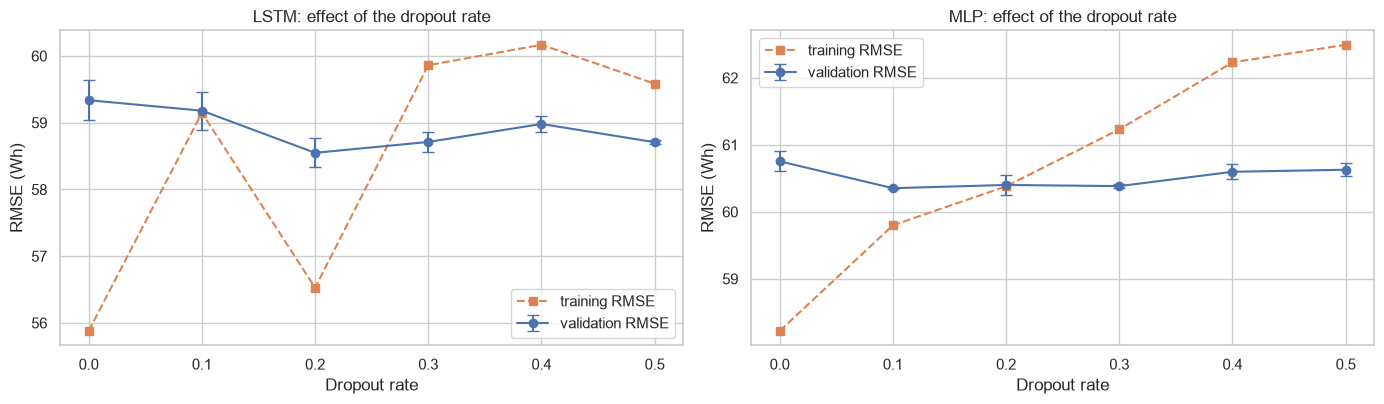


LSTM: dropout sweep (mean over seeds (42, 7))


,val RMSE (mean),val RMSE (std),val MAE (mean),train RMSE (mean),epochs (mean),overfit gap
dropout,,,,,,
0.0,59.337,0.302,27.427,55.879,26.5,3.457
0.1,59.180,0.285,26.471,59.148,23.0,0.032
0.2,58.548,0.216,26.036,56.527,33.5,2.022
0.3,58.711,0.147,25.985,59.861,28.5,-1.150
0.4,58.981,0.124,26.115,60.167,30.0,-1.186
0.5,58.707,0.029,25.485,59.584,39.5,-0.877


-> LSTM dropout rate: 0.2 -> 0.2

MLP: dropout sweep (mean over seeds (42, 7))


,val RMSE (mean),val RMSE (std),val MAE (mean),train RMSE (mean),epochs (mean),overfit gap
dropout,,,,,,
0.0,60.753,0.151,29.607,58.222,38.5,2.532
0.1,60.353,0.018,28.131,59.799,45.5,0.554
0.2,60.401,0.154,28.203,60.380,48.5,0.020
0.3,60.384,0.027,27.885,61.230,47.5,-0.847
0.4,60.597,0.113,27.656,62.230,47.5,-1.632
0.5,60.628,0.101,27.546,62.493,58.5,-1.865


-> MLP dropout rate: 0.1 -> 0.1


In [40]:
DROPOUT_RATES = [0.0, 0.1, 0.2, 0.3, 0.4, 0.5]
dropout_results = {}
for family in FAMILIES:
    rows = []
    for p in DROPOUT_RATES:
        for seed in SWEEP_SEEDS:
            r = run_experiment(f"E3: dropout {family}", f"{family} dropout {p} s{seed}", {**tuned_cfg[family], "dropout": p}, seed=seed)
            rows.append({"dropout": p, "seed": seed, "RMSE": r["RMSE (Wh)"], "MAE": r["MAE (Wh)"],
                         "Train RMSE": r["Train RMSE (Wh)"], "Epochs": r["Epochs"]})
    dropout_results[family] = pd.DataFrame(rows)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
for ax, family in zip(axes, FAMILIES):
    g = dropout_results[family].groupby("dropout")
    mean, std = g["RMSE"].mean(), g["RMSE"].std().fillna(0)
    ax.errorbar(mean.index, mean.values, yerr=std.values, marker="o", capsize=4, label="validation RMSE")
    ax.plot(g["Train RMSE"].mean().index, g["Train RMSE"].mean().values, marker="s", linestyle="--", label="training RMSE")
    ax.set(title=f"{family}: effect of the dropout rate", xlabel="Dropout rate", ylabel="RMSE (Wh)")
    ax.legend()
plt.tight_layout()
plt.show()

for family in FAMILIES:
    summary = dropout_results[family].groupby("dropout").agg(**{"val RMSE (mean)": ("RMSE", "mean"), "val RMSE (std)": ("RMSE", "std"),
                                                              "val MAE (mean)": ("MAE", "mean"), "train RMSE (mean)": ("Train RMSE", "mean"),
                                                              "epochs (mean)": ("Epochs", "mean")})
    summary["overfit gap"] = summary["val RMSE (mean)"] - summary["train RMSE (mean)"]
    print(f"\n{family}: dropout sweep (mean over seeds {SWEEP_SEEDS})")
    display(summary.round(3))
    current = tuned_cfg[family]["dropout"]
    best_rate = summary["val RMSE (mean)"].idxmin()
    if summary.loc[best_rate, "val RMSE (mean)"] > summary.loc[current, "val RMSE (mean)"] * 0.995:
        best_rate = current
    tuned_cfg[family]["dropout"] = float(best_rate)
    print(f"-> {family} dropout rate: {current} -> {tuned_cfg[family]['dropout']}")

**Regularization decision.** **LSTM:** mean validation RMSE 59.34 Wh without dropout (training RMSE 55.9 Wh, gap + 3.5 Wh = overfitting), 59.18 at 0.1, **58.55 at 0.2**, 58.71 at 0.3, 58.98 at 0.4 and 58.71 at 0.5. Rates 0.2 – 0.5 are within about 0.7 % of each other, which is the size of the seed-to-seed spread, whereas no dropout is clearly worse and overfits. **0.2 is kept.** **MLP:** 60.75 Wh without dropout (gap + 2.5 Wh), then 60.35 / 60.40 / 60.38 at 0.1 / 0.2 / 0.3 and 60.60 / 60.63 at 0.4 / 0.5. The curve is flat between 0.1 and 0.3; **0.1 is kept**. High rates (0.4 – 0.5) start to under-fit (the training error rises to 62.5 Wh for the MLP) while the MAE keeps falling, because the network shrinks toward the typical consumption and under-predicts peaks. In both families dropout is applied after the recurrent layer or the hidden layer and removes the overfitting gap with a rate of 0.1 – 0.3.

### 5.3 Early stopping
Early stopping watches the **validation loss** after every epoch and halts training when it has not improved for `patience` epochs; `restore_best_weights=True` then returns the network to its best epoch, so training for too long cannot hurt. A learning-rate reduction on plateau runs together with it. The only free choice is the **patience**: too small stops during a temporary plateau, too large wastes time and may drift to a worse optimum. Patience values are compared with several seeds, with the epoch cap raised to 100 so that stopping is always decided by the validation loss.

[E4: patience LSTM] LSTM patience 3 s42                    val RMSE  58.805 | MAE  26.063 | R² 0.6297 | epochs 19 |  14.4s


[E4: patience LSTM] LSTM patience 3 s7                     val RMSE  58.583 | MAE  26.112 | R² 0.6325 | epochs 22 |  16.3s


[E4: patience LSTM] LSTM patience 6 s42                    val RMSE  58.701 | MAE  26.273 | R² 0.6310 | epochs 27 |  19.8s


[E4: patience LSTM] LSTM patience 6 s7                     val RMSE  58.395 | MAE  25.799 | R² 0.6348 | epochs 41 |  30.1s


[E4: patience LSTM] LSTM patience 10 s42                   val RMSE  58.800 | MAE  26.026 | R² 0.6298 | epochs 32 |  23.6s


...

[E4: patience MLP] MLP patience 15 s7                     val RMSE  60.478 | MAE  28.554 | R² 0.6083 | epochs 50 |   7.4s

LSTM: patience study (mean over seeds (42, 7))


,val RMSE (mean),val RMSE (std),epochs used (mean),best epoch (mean),time s (mean)
patience,,,,,
3,58.694,0.157,20.5,17.5,15.35
6,58.548,0.216,34.0,28.0,24.95
10,58.621,0.254,35.5,25.5,25.80
15,58.775,0.471,41.5,26.5,31.10


-> LSTM patience = 3 (lowest validation RMSE at patience 6)

MLP: patience study (mean over seeds (42, 7))


,val RMSE (mean),val RMSE (std),epochs used (mean),best epoch (mean),time s (mean)
patience,,,,,
3,60.824,0.194,19.5,16.5,3.4
6,60.353,0.018,45.5,39.5,7.1
10,60.533,0.310,43.0,33.0,6.7
15,60.369,0.154,71.5,56.5,10.6


-> MLP patience = 6 (lowest validation RMSE at patience 6)


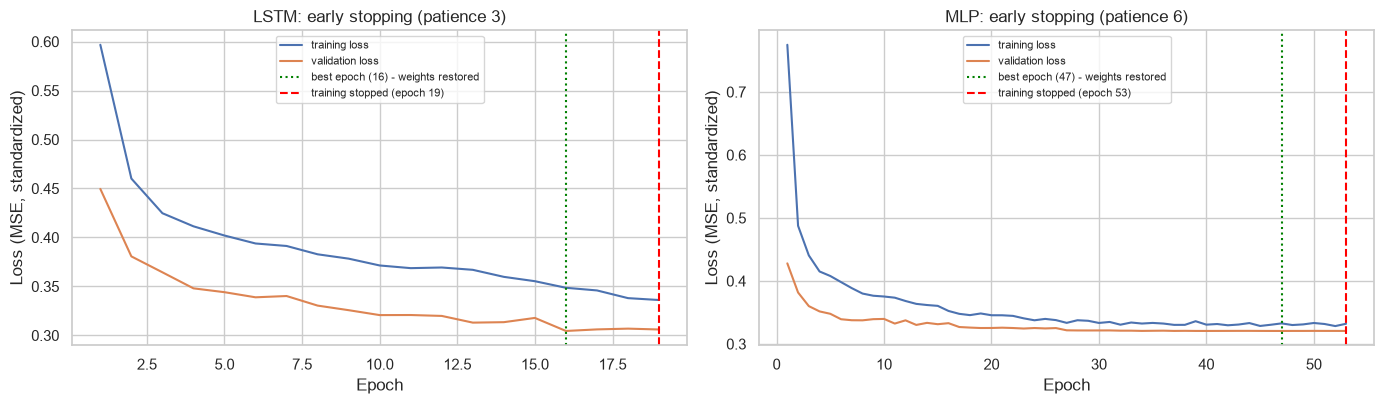

In [41]:
PATIENCES = [3, 6, 10, 15]
patience_results = {}
for family in FAMILIES:
    rows = []
    for pat in PATIENCES:
        for seed in SWEEP_SEEDS:
            r = run_experiment(f"E4: patience {family}", f"{family} patience {pat} s{seed}",
                               {**tuned_cfg[family], "patience": pat, "max_epochs": EPOCH_CAP}, seed=seed)
            rows.append({"patience": pat, "seed": seed, "RMSE": r["RMSE (Wh)"], "Epochs": r["Epochs"],
                         "Best epoch": r["Best epoch"], "Time": r["Time (s)"]})
    patience_results[family] = pd.DataFrame(rows)

for family in FAMILIES:
    summary = patience_results[family].groupby("patience").agg(**{"val RMSE (mean)": ("RMSE", "mean"), "val RMSE (std)": ("RMSE", "std"),
                                                                "epochs used (mean)": ("Epochs", "mean"),
                                                                "best epoch (mean)": ("Best epoch", "mean"), "time s (mean)": ("Time", "mean")})
    print(f"\n{family}: patience study (mean over seeds {SWEEP_SEEDS})")
    display(summary.round(3))
    best_pat = summary["val RMSE (mean)"].idxmin()
    # near-ties (within 0.5 %) -> the smaller patience (cheaper, less drift)
    near = summary[summary["val RMSE (mean)"] <= summary["val RMSE (mean)"].min() * 1.005]
    tuned_cfg[family]["patience"] = int(near.index.min())
    tuned_cfg[family]["max_epochs"] = EPOCH_CAP
    print(f"-> {family} patience = {tuned_cfg[family]['patience']} (lowest validation RMSE at patience {best_pat})")

# Early-stopping in action: training/validation loss of one tuned run per family, with the stopping point marked
fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
for ax, family in zip(axes, FAMILIES):
    name = f"{family} patience {tuned_cfg[family]['patience']} s{SWEEP_SEEDS[0]}"
    h = trained[name]["history"]; best_epoch = int(np.argmin(h["val_loss"]) + 1)
    ax.plot(range(1, len(h["loss"]) + 1), h["loss"], label="training loss")
    ax.plot(range(1, len(h["val_loss"]) + 1), h["val_loss"], label="validation loss")
    ax.axvline(best_epoch, color="green", linestyle=":", label=f"best epoch ({best_epoch}) - weights restored")
    ax.axvline(len(h["loss"]), color="red", linestyle="--", label=f"training stopped (epoch {len(h['loss'])})")
    ax.set(title=f"{family}: early stopping (patience {tuned_cfg[family]['patience']})", xlabel="Epoch", ylabel="Loss (MSE, standardized)")
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

**Early-stopping decision.** Early stopping is active in every run (validation-loss monitor, best weights restored). **LSTM:** patience 3 / 6 / 10 / 15 gives 58.69 / 58.55 / 58.62 / 58.78 Wh with 20 / 34 / 36 / 42 epochs on average. All four are within 0.4 %, so the **smallest patience (3) is chosen**: the same accuracy with about 40 % fewer epochs (15 s instead of 25 s per training run), and the restored best weights come from epoch 17 on average. **MLP:** patience 3 stops too early (60.82 Wh, 20 epochs, +0.8 % worse) because its validation loss has temporary plateaus; patience 6 (60.35 Wh, 46 epochs) is as good as 10 and 15 (60.53 and 60.37 Wh, 43 and 72 epochs) and is kept. The figure above shows one run per family: the validation loss reaches its minimum, training continues for `patience` more epochs, and training is then stopped with the best weights restored.

### 5.4 Final optimized models: walk-forward confirmation and validation of the seed ensemble
1. **Confirmation on the reliable protocol:** the final optimized configuration of each family is compared with its starting configuration once more with the walk-forward cross-validation (training part only). If the "optimized" configuration is not better, the starting configuration is kept: an optimization step must never make the model worse.
2. **Seed ensemble:** neural-network results vary from run to run (§4.1). Averaging the predictions of several networks trained with different seeds reduces this variance at no cost in data. Whether it helps is decided on the **validation set** (not the test set), and it is used only if it improves validation RMSE.

LSTM: optimized config ACCEPTED


MLP: optimized config ACCEPTED


,Family,Version,Config,Params,WF RMSE (Wh),WF MAE (Wh),WF RMSE std over fits,Worst fold (Wh),fold 1,fold 2,fold 3,fold 4
0,LSTM,before (start),u64 d32 p0.2 lr0.001 b128 L12 pat6,22337,65.765,31.263,4.708,71.085,69.702,71.085,61.502,60.770
1,LSTM,after (optimized),u64 d32 p0.2 lr0.001 b128 L12 pat3,22337,65.688,31.201,4.875,71.252,69.795,71.252,61.134,60.570
2,MLP,before (start),u128 d0 p0.2 lr0.001 b128 L12 pat6,21761,66.656,33.261,4.727,72.835,69.607,72.835,62.552,61.631
3,MLP,after (optimized),u128 d0 p0.1 lr0.001 b256 L6 pat6,11009,65.470,32.482,4.643,71.862,67.893,71.862,61.279,60.845


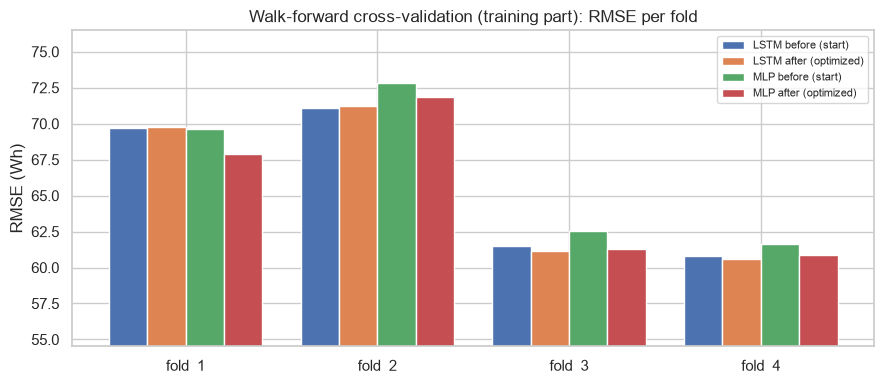

In [42]:
# 1) confirmation with walk-forward cross-validation: start configuration vs final optimized configuration
final_cfg, confirm_rows = {}, []
for family in FAMILIES:
    start = FAMILIES[family]
    opt = {**tuned_cfg[family]}
    wf_start, wf_opt = walk_forward_dl(start), walk_forward_dl(opt)
    keep_opt = wf_opt["WF RMSE (Wh)"] <= wf_start["WF RMSE (Wh)"]
    final_cfg[family] = opt if keep_opt else start
    for label, cfg, wf in [("before (start)", start, wf_start), ("after (optimized)", opt, wf_opt)]:
        confirm_rows.append({"Family": family, "Version": label, "Config": short(cfg) + f" pat{cfg.get('patience', PATIENCE)}",
                             "Params": count_params(cfg), **{k: wf[k] for k in ["WF RMSE (Wh)", "WF MAE (Wh)", "WF RMSE std over fits", "Worst fold (Wh)"]},
                             **{k: v for k, v in wf.items() if k.startswith("fold")}})
    print(f"{family}: optimized config {'ACCEPTED' if keep_opt else 'REJECTED (not better in walk-forward CV) - start config kept'}")
confirm = pd.DataFrame(confirm_rows)
display(confirm.round(3))

fig, ax = plt.subplots(figsize=(9, 4))
fold_cols = [c for c in confirm.columns if c.startswith("fold")]
width = 0.2
for k, (_, row) in enumerate(confirm.iterrows()):
    ax.bar(np.arange(len(fold_cols)) + k * width, row[fold_cols].astype(float), width, label=f"{row['Family']} {row['Version']}")
ax.set_xticks(np.arange(len(fold_cols)) + 1.5 * width); ax.set_xticklabels([c.replace("fold", "fold ") for c in fold_cols])
ax.set(title="Walk-forward cross-validation (training part): RMSE per fold", ylabel="RMSE (Wh)")
ax.set_ylim(bottom=confirm[fold_cols].astype(float).min().min() * 0.9)
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

In [43]:
# 2) final training with the same seeds as section 4 (paired before/after) + validation check of the seed ensemble
FINAL_SEEDS_OPT = [42, 7, 123]
before_runs, after_runs = {}, {}
for family in FAMILIES:
    for seed in FINAL_SEEDS_OPT:
        before_runs[(family, seed)] = run_experiment("F: before", f"{family} before s{seed}", FAMILIES[family], seed=seed, store_test=True)
        after_runs[(family, seed)] = run_experiment("F: after", f"{family} after s{seed}", final_cfg[family], seed=seed, store_test=True)

use_ensemble = {}
for family in FAMILIES:
    single = np.mean([after_runs[(family, s)]["RMSE (Wh)"] for s in FINAL_SEEDS_OPT])
    ens_val = np.mean([trained[f"{family} after s{s}"]["val_pred"] for s in FINAL_SEEDS_OPT], axis=0)
    ens_rmse = regression_metrics(y_val_wh, ens_val)["RMSE (Wh)"]
    use_ensemble[family] = ens_rmse < single
    print(f"{family}: validation RMSE single network (mean of {len(FINAL_SEEDS_OPT)} seeds) {single:.3f} Wh | "
          f"{len(FINAL_SEEDS_OPT)}-seed ensemble {ens_rmse:.3f} Wh -> ensemble {'USED' if use_ensemble[family] else 'not used'}")

[F: before] LSTM before s42                        val RMSE  58.701 | MAE  26.273 | R² 0.6310 | epochs 27 |  20.8s


[F: after] LSTM after s42                         val RMSE  58.805 | MAE  26.063 | R² 0.6297 | epochs 19 |  14.5s


[F: before] LSTM before s7                         val RMSE  58.395 | MAE  25.799 | R² 0.6348 | epochs 40 |  28.9s


[F: after] LSTM after s7                          val RMSE  58.583 | MAE  26.112 | R² 0.6325 | epochs 22 |  16.9s


[F: before] LSTM before s123                       val RMSE  59.598 | MAE  26.868 | R² 0.6196 | epochs 29 |  21.5s


...

[F: after] MLP after s42                          val RMSE  60.340 | MAE  28.143 | R² 0.6101 | epochs 53 |   7.8s


[F: before] MLP before s7                          val RMSE  60.540 | MAE  27.928 | R² 0.6075 | epochs 40 |   8.6s


[F: after] MLP after s7                           val RMSE  60.366 | MAE  28.119 | R² 0.6098 | epochs 38 |   5.8s


[F: before] MLP before s123                        val RMSE  60.643 | MAE  28.152 | R² 0.6062 | epochs 31 |   7.1s


[F: after] MLP after s123                         val RMSE  60.680 | MAE  27.742 | R² 0.6057 | epochs 27 |   4.5s
LSTM: validation RMSE single network (mean of 3 seeds) 59.010 Wh | 3-seed ensemble 58.689 Wh -> ensemble USED
MLP: validation RMSE single network (mean of 3 seeds) 60.462 Wh | 3-seed ensemble 60.119 Wh -> ensemble USED


### 5.5 Model evaluation after optimization (test set)
The test set is used here for the **final comparison** of the starting and the optimized models (same 3,947 test intervals as in §4, all metrics in Wh). Nothing in §5.1–§5.4 was decided on test data. Deep-learning rows show the **mean ± standard deviation over three seeds**; the ensemble row averages the predictions of those three networks.

**Reliability of the ranking:** the test set cannot be enlarged, so the uncertainty of every difference is estimated with a **paired block bootstrap**: whole days (144 consecutive intervals) of test errors are resampled with replacement 2,000 times, and each model pair is compared on the *same* resampled days. The 95 % interval shows how much of an RMSE difference could be due to chance; if it contains 0, the two models cannot be separated.

In [44]:
def ens_pred(prefix_runs, family, which="test_pred"):
    return np.mean([trained[f"{family} {prefix_runs} s{s}"][which] for s in FINAL_SEEDS_OPT], axis=0)

rows, pred_store = [], {}
for ref in ["Persistence", "Linear Regression", "Ridge Regression", "Random Forest"]:
    rows.append({"Model": ref, **regression_metrics(y_test_wh, baseline_test_pred[ref]), "RMSE std (seeds)": np.nan})
    pred_store[ref] = baseline_test_pred[ref]

for family in FAMILIES:
    for label, tag in [("before", "before"), ("after", "after")]:
        per_seed = [regression_metrics(y_test_wh, trained[f"{family} {tag} s{s}"]["test_pred"]) for s in FINAL_SEEDS_OPT]
        mean = {k: float(np.mean([m[k] for m in per_seed])) for k in per_seed[0]}
        rows.append({"Model": f"{family} {label} optimization (mean of seeds)", **mean,
                     "RMSE std (seeds)": float(np.std([m["RMSE (Wh)"] for m in per_seed]))})
        pred_store[f"{family} {label}"] = trained[f"{family} {tag} s{FINAL_SEEDS_OPT[0]}"]["test_pred"]
        ens = ens_pred(tag, family)
        rows.append({"Model": f"{family} {label} optimization (3-seed ensemble)", **regression_metrics(y_test_wh, ens), "RMSE std (seeds)": np.nan})
        pred_store[f"{family} {label} ensemble"] = ens

post_results = pd.DataFrame(rows)
print("=== TEST SET: before vs after optimization (original Wh scale) ===")
display(post_results.round(4))

# Change caused by the optimization, per family (paired by seed)
change_rows = []
for family in FAMILIES:
    b = np.array([regression_metrics(y_test_wh, trained[f"{family} before s{s}"]["test_pred"])["RMSE (Wh)"] for s in FINAL_SEEDS_OPT])
    a = np.array([regression_metrics(y_test_wh, trained[f"{family} after s{s}"]["test_pred"])["RMSE (Wh)"] for s in FINAL_SEEDS_OPT])
    change_rows.append({"Family": family, "RMSE before (mean)": b.mean(), "RMSE after (mean)": a.mean(),
                        "change (%)": (b.mean() - a.mean()) / b.mean() * 100, "seeds improved": f"{int((a < b).sum())} of {len(a)}",
                        "RMSE std before": b.std(), "RMSE std after": a.std()})
print("\nOptimization effect on the test RMSE (positive % = improvement):")
display(pd.DataFrame(change_rows).round(3))

=== TEST SET: before vs after optimization (original Wh scale) ===


,Model,MAE (Wh),RMSE (Wh),MAPE (%),R²,RMSE std (seeds)
0,Persistence,26.6506,66.4376,21.9361,0.4674,NaN
1,Linear Regression,27.1273,59.8152,25.0889,0.5683,NaN
2,Ridge Regression,27.1272,59.8152,25.0888,0.5683,NaN
3,Random Forest,26.3300,58.4030,23.9055,0.5885,NaN
4,LSTM before optimization (mean of seeds),26.2388,58.2019,23.4245,0.5912,0.8055
5,LSTM before optimization (3-seed ensemble),25.6742,57.3916,22.8261,0.6026,NaN
6,LSTM after optimization (mean of seeds),25.7793,57.2253,23.1617,0.6049,0.2088
7,LSTM after optimization (3-seed ensemble),25.4458,56.9102,22.7838,0.6092,NaN
8,MLP before optimization (mean of seeds),27.4049,58.1126,25.4827,0.5925,0.1359
9,MLP before optimization (3-seed ensemble),27.0916,57.8842,25.0662,0.5957,NaN



Optimization effect on the test RMSE (positive % = improvement):


,Family,RMSE before (mean),RMSE after (mean),change (%),seeds improved,RMSE std before,RMSE std after
0,LSTM,58.202,57.225,1.678,3 of 3,0.805,0.209
1,MLP,58.113,57.950,0.280,2 of 3,0.136,0.140


In [45]:
# Paired block bootstrap over whole days of the test set
def block_bootstrap_diff(y, p_a, p_b, block=144, n_boot=2000, seed=SEED):
    """RMSE(a) - RMSE(b) on resampled days; returns mean difference, 95 % interval, share of resamples where a is better."""
    rng = np.random.default_rng(seed)
    n = len(y); n_blocks = int(np.ceil(n / block))
    e_a, e_b = (y - p_a) ** 2, (y - p_b) ** 2
    diffs = np.empty(n_boot)
    for k in range(n_boot):
        starts = rng.integers(0, n - block + 1, size=n_blocks)
        idx = (starts[:, None] + np.arange(block)[None, :]).ravel()[:n]
        diffs[k] = np.sqrt(e_a[idx].mean()) - np.sqrt(e_b[idx].mean())
    return diffs.mean(), np.percentile(diffs, 2.5), np.percentile(diffs, 97.5), float((diffs < 0).mean())

def best_variant(family, tag):
    """The prediction that a family would deploy: the seed ensemble if it won on validation, else seed 42."""
    return pred_store[f"{family} {tag} ensemble"] if use_ensemble[family] else pred_store[f"{family} {tag}"]

comparisons = []
for family in FAMILIES:
    a_name = f"{family} after ({'ensemble' if use_ensemble[family] else 'single seed 42'})"
    pa = best_variant(family, "after")
    for ref_name, pref in [(f"{family} before", best_variant(family, "before")), ("Persistence", pred_store["Persistence"]),
                           ("Linear Regression", pred_store["Linear Regression"]), ("Random Forest", pred_store["Random Forest"])]:
        mean, lo, hi, p_better = block_bootstrap_diff(y_test_wh, pa, pref)
        comparisons.append({"Model A": a_name, "vs. Model B": ref_name, "RMSE(A) - RMSE(B) (Wh)": mean,
                            "95 % lower": lo, "95 % upper": hi, "P(A better)": p_better,
                            "verdict": "A better" if hi < 0 else ("B better" if lo > 0 else "cannot be separated")})
# LSTM vs MLP after optimization
mean, lo, hi, p_better = block_bootstrap_diff(y_test_wh, best_variant("LSTM", "after"), best_variant("MLP", "after"))
comparisons.append({"Model A": "LSTM after", "vs. Model B": "MLP after", "RMSE(A) - RMSE(B) (Wh)": mean, "95 % lower": lo, "95 % upper": hi,
                    "P(A better)": p_better, "verdict": "A better" if hi < 0 else ("B better" if lo > 0 else "cannot be separated")})
comparison_df = pd.DataFrame(comparisons)
print("Paired block bootstrap (1 day blocks, 2,000 resamples): negative difference = model A has the lower RMSE")
display(comparison_df.round(3))

Paired block bootstrap (1 day blocks, 2,000 resamples): negative difference = model A has the lower RMSE


,Model A,vs. Model B,RMSE(A) - RMSE(B) (Wh),95 % lower,95 % upper,P(A better),verdict
0,LSTM after (ensemble),LSTM before,-0.316,-0.938,0.321,0.836,cannot be separated
1,LSTM after (ensemble),Persistence,-9.479,-11.390,-7.500,1.000,A better
2,LSTM after (ensemble),Linear Regression,-3.073,-4.207,-1.900,1.000,A better
3,LSTM after (ensemble),Random Forest,-1.488,-2.667,-0.416,0.996,A better
4,MLP after (ensemble),MLP before,-0.389,-0.719,-0.068,0.990,A better
5,MLP after (ensemble),Persistence,-8.726,-10.627,-6.824,1.000,A better
6,MLP after (ensemble),Linear Regression,-2.319,-3.515,-1.220,1.000,A better
7,MLP after (ensemble),Random Forest,-0.734,-1.816,0.369,0.906,cannot be separated
8,LSTM after,MLP after,-0.754,-1.593,0.016,0.972,cannot be separated


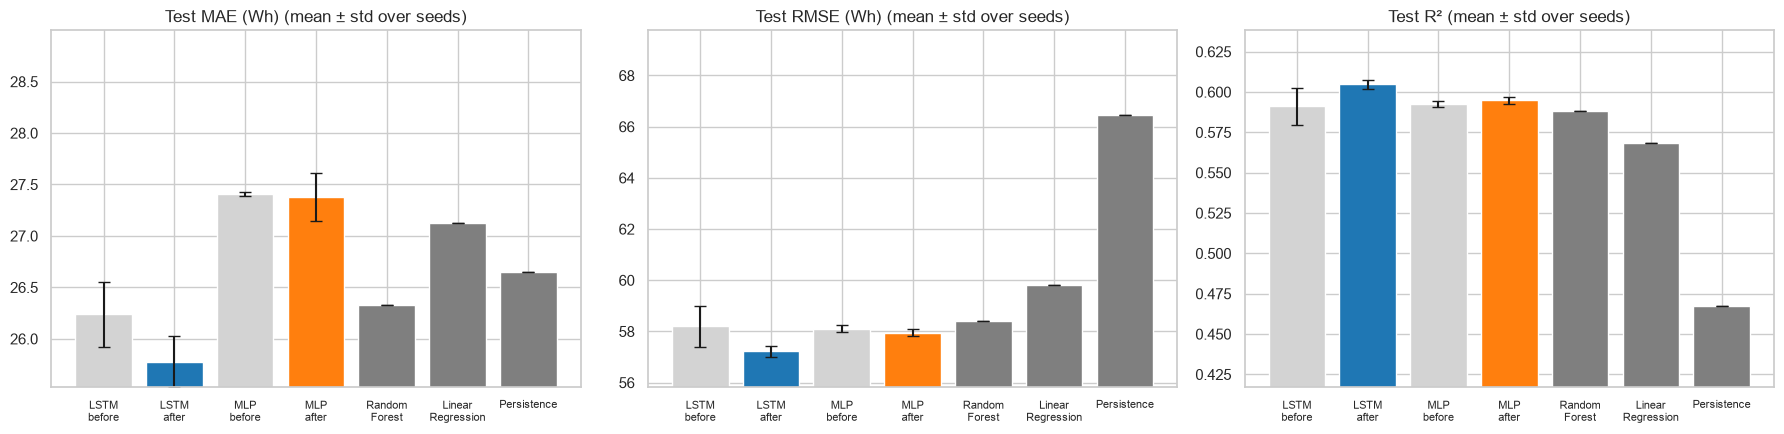

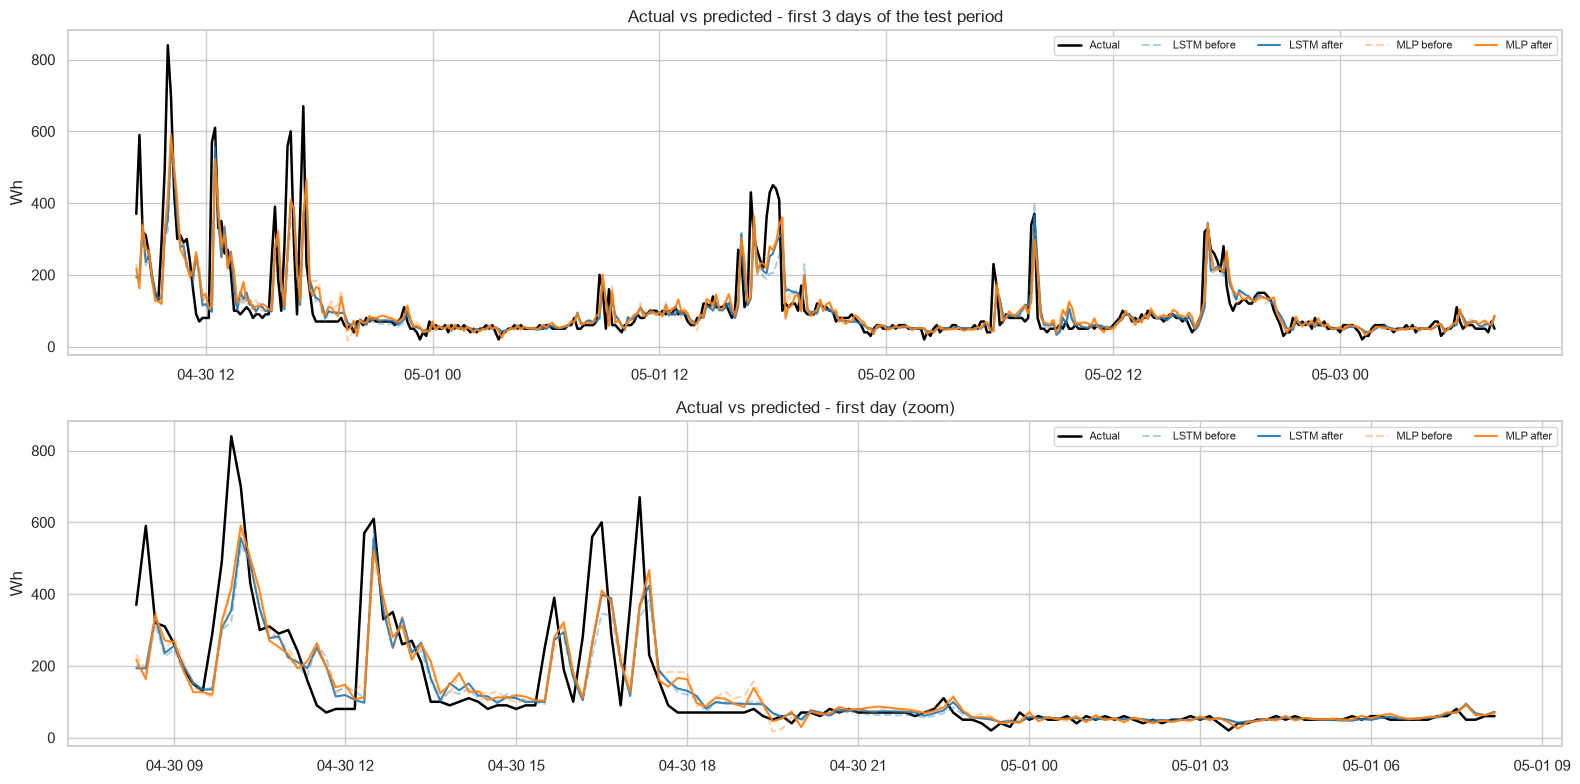

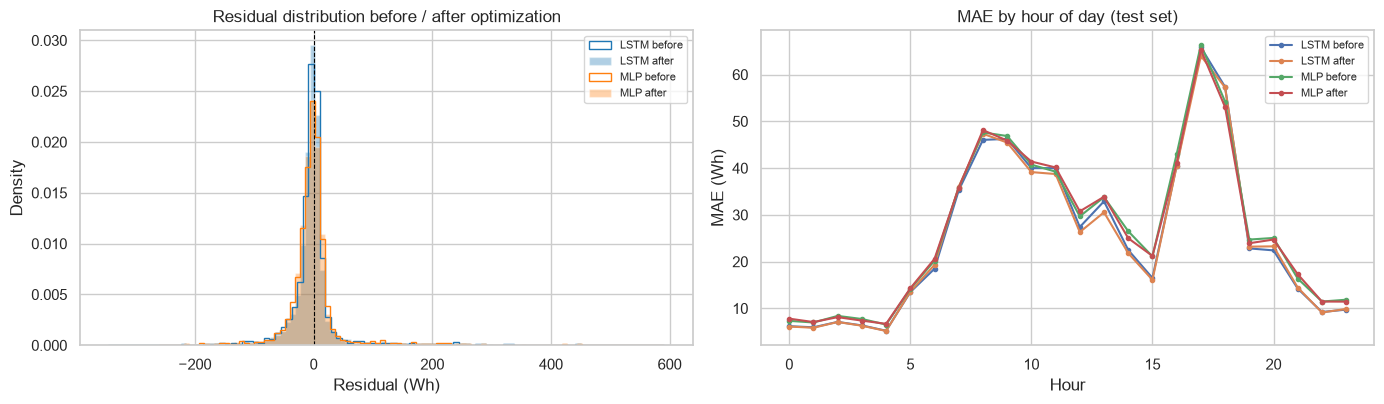

Saved: results/optimization_test_results.csv, optimization_bootstrap.csv, optimization_walk_forward.csv

Final optimized configurations:
  LSTM: units (64,), dense 32, dropout 0.2, lr 0.001, batch 128, look-back 12, patience 3, max epochs 100, ensemble: True
  MLP: units (128,), dense 0, dropout 0.1, lr 0.001, batch 256, look-back 6, patience 6, max epochs 100, ensemble: True


In [46]:
# Visualizations: before vs after optimization
plot_models = [("LSTM", "tab:blue"), ("MLP", "tab:orange")]
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
for ax, metric in zip(axes, ["MAE (Wh)", "RMSE (Wh)", "R²"]):
    labels, vals, errs, cols = [], [], [], []
    for family, color in plot_models:
        for tag in ["before", "after"]:
            per_seed = [regression_metrics(y_test_wh, trained[f"{family} {tag} s{s}"]["test_pred"])[metric] for s in FINAL_SEEDS_OPT]
            labels.append(f"{family}\n{tag}"); vals.append(np.mean(per_seed)); errs.append(np.std(per_seed)); cols.append(color if tag == "after" else "lightgray")
    for ref in ["Random Forest", "Linear Regression", "Persistence"]:
        labels.append(ref.replace(" ", "\n")); vals.append(regression_metrics(y_test_wh, pred_store[ref])[metric]); errs.append(0); cols.append("tab:gray")
    ax.bar(labels, vals, yerr=errs, color=cols, capsize=4)
    lo_v = min(vals) - 0.15 * (max(vals) - min(vals) + 1e-9) if metric != "R²" else min(vals) - 0.05
    ax.set(title=f"Test {metric} (mean ± std over seeds)", ylim=(lo_v, None)); ax.tick_params(axis="x", labelsize=8)
plt.tight_layout()
plt.show()

# Predicted vs actual and residuals for the deployed variants
dates_test = full.loc[idx_test, "date"].to_numpy()
fig, axes = plt.subplots(2, 1, figsize=(16, 8))
for ax, (lo, hi, title) in zip(axes, [(0, 432, "first 3 days of the test period"), (0, 144, "first day (zoom)")]):
    ax.plot(dates_test[lo:hi], y_test_wh[lo:hi], color="black", linewidth=1.8, label="Actual")
    for family, color in plot_models:
        ax.plot(dates_test[lo:hi], best_variant(family, "before")[lo:hi], color=color, alpha=0.35, linestyle="--", label=f"{family} before")
        ax.plot(dates_test[lo:hi], best_variant(family, "after")[lo:hi], color=color, alpha=0.9, label=f"{family} after")
    ax.set(title=f"Actual vs predicted - {title}", ylabel="Wh"); ax.legend(ncol=5, fontsize=8)
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
for family, color in plot_models:
    for tag, style in [("before", "step"), ("after", "stepfilled")]:
        res = y_test_wh - best_variant(family, tag)
        axes[0].hist(res, bins=100, histtype=style, alpha=0.35 if style == "stepfilled" else 1, density=True, color=color, label=f"{family} {tag}")
axes[0].axvline(0, color="black", linestyle="--", linewidth=0.8)
axes[0].set(title="Residual distribution before / after optimization", xlabel="Residual (Wh)", ylabel="Density"); axes[0].legend(fontsize=8)
hourly = {f"{fam} {tag}": pd.Series(np.abs(y_test_wh - best_variant(fam, tag))).groupby(full.loc[idx_test, "hour"].to_numpy()).mean()
          for fam, _ in plot_models for tag in ["before", "after"]}
pd.DataFrame(hourly).plot(ax=axes[1], marker="o", markersize=3)
axes[1].set(title="MAE by hour of day (test set)", xlabel="Hour", ylabel="MAE (Wh)"); axes[1].legend(fontsize=8)
plt.tight_layout()
plt.show()

# Save the optimization results
os.makedirs("results", exist_ok=True)
post_results.to_csv("results/optimization_test_results.csv", index=False)
comparison_df.to_csv("results/optimization_bootstrap.csv", index=False)
confirm.to_csv("results/optimization_walk_forward.csv", index=False)
print("Saved: results/optimization_test_results.csv, optimization_bootstrap.csv, optimization_walk_forward.csv")
print("\nFinal optimized configurations:")
for family in FAMILIES:
    c = final_cfg[family]
    print(f"  {family}: units {c['units']}, dense {c['dense']}, dropout {c['dropout']}, lr {c['lr']:g}, batch {c.get('batch', BATCH_SIZE)}, "
          f"look-back {c['lookback']}, patience {c.get('patience', PATIENCE)}, max epochs {c.get('max_epochs', MAX_EPOCHS)}, ensemble: {use_ensemble[family]}")

### 5.6 Conclusions of the optimization
**Final optimized models**

| | Before | After |
|---|---|---|
| LSTM | 64 units + dense 32, dropout 0.2, lr 0.001, batch 128, look-back 12, patience 6, max 40 epochs | same architecture and hyper-parameters, **patience 3**, max 100 epochs, 3-seed ensemble |
| MLP | 1 hidden layer of 128, dropout 0.2, lr 0.001, batch 128, look-back 12, patience 6 (21.8 k parameters) | 1 hidden layer of 128, **dropout 0.1, batch 256, look-back 6**, patience 6 (**11 k parameters**), 3-seed ensemble |

**Test-set results** (3,947 intervals, Wh; deep-learning rows are the mean over three seeds, "ensemble" averages the three networks):

| Model | MAE | RMSE | R² |
|---|---|---|---|
| Persistence | 26.65 | 66.44 | 0.467 |
| Linear Regression | 27.13 | 59.82 | 0.568 |
| Random Forest | 26.33 | 58.40 | 0.589 |
| LSTM before (mean ± std) | 26.24 | 58.20 ± 0.81 | 0.591 |
| LSTM after (mean ± std) | 25.78 | 57.23 ± 0.21 | 0.605 |
| **LSTM after, 3-seed ensemble** | **25.45** | **56.91** | **0.609** |
| MLP before (mean ± std) | 27.40 | 58.11 ± 0.14 | 0.593 |
| MLP after (mean ± std) | 27.38 | 57.95 ± 0.14 | 0.595 |
| MLP after, 3-seed ensemble | 26.95 | 57.64 | 0.599 |

**What the evidence supports**
1. **Optimization gave small gains, and most of them are not statistically separable.** The LSTM test RMSE improved by 1.7 % (3 of 3 seeds improved, the spread between seeds fell from 0.81 to 0.21 Wh), but the LSTM hyper-parameters did not change; only the patience did (and the ensemble was added). The walk-forward test, the more reliable measure, shows only a 0.1 % difference, and the paired bootstrap cannot separate the ensembles before and after (−0.32 Wh, 95 % interval −0.94 … + 0.32). A good part of the 1.7 % is therefore seed luck: the "before" average is pulled up by one weak seed (59.3 Wh). The honest summary is: **the LSTM was already close to its optimum; the optimization confirmed this, made training about 40 % shorter at the same accuracy, and the ensemble reduces the variance.**
2. **The MLP profited more from tuning** in the reliable measure (walk-forward −1.8 %) and became half as large; on the test set the effect is small (−0.3 %, mean of seeds; −0.4 Wh as ensemble with a bootstrap interval that excludes 0).
3. **Seed ensembling is the most consistent improvement:** averaging three networks lowered the test RMSE in every case (LSTM 57.23 → 56.91 Wh, MLP 57.95 → 57.64 Wh), and it was only accepted because it also won on the validation set. The price is three times the inference cost, which matters on an edge device.
4. **Ranking on the test set, with the uncertainty from the day-block bootstrap:** the optimized LSTM ensemble (56.91 Wh) is better than persistence (−9.5 Wh, interval −11.4 … −7.5), Linear Regression (−3.1 Wh, −4.2 … −1.9) and the **Random Forest (−1.5 Wh, −2.7 … −0.4)**, so it is now separable from the Random Forest, which was not the case in §4. The optimized MLP ensemble is better than persistence and Linear Regression but **cannot be separated from the Random Forest** (−0.7 Wh, −1.8 … + 0.4) or from the LSTM (LSTM − MLP = −0.75 Wh, interval −1.6 … + 0.02).
5. **Recommendation:** the LSTM (single layer, 22 k parameters) gives the lowest error; the MLP (11 k parameters, about 5 – 9 s of training) is almost as good and is the cheaper choice if inference cost or memory is limited. A single network of either type is preferable to the ensemble when the 3× inference cost is not acceptable.

**Limitations**
* The data cannot be extended and the 80 % / 20 % split is fixed. The walk-forward folds, the seeds and the block bootstrap make the ranking more reliable, but the bootstrap only reflects the variation *inside* the 20 % test period (about 27 days of May); it cannot cover other seasons.
* Differences of 0.5 % or less are not resolvable with this data and these budgets. Search budgets were modest (16 – 20 random configurations, two seeds for the sweeps); a Bayesian optimizer or more seeds could be tried if more compute were available, but the flat optimum found here suggests the gains would be small.
* Test results were looked at once, at the end, for the before/after comparison; all choices in §5.1 – §5.4 were made on training-part data only.